# **Proyecto Aplicado — Predicción del Puntaje Global en las Pruebas Saber 11**
---

Este notebook integra las **cuatro primeras fases** del proyecto aplicado de *Machine Learning*, desarrollado bajo la metodología **CRISP-DM** (*Cross-Industry Standard Process for Data Mining*; Chapman et al., 2000):

| Fase | Nombre | Descripción |
|------|--------|-------------|
| **Fase 1** | Entendimiento del negocio y carga de datos | Contexto, objetivos, alcance, plan del proyecto y adquisición del dataset |
| **Fase 2** | Entendimiento de los datos (EDA) | Análisis exploratorio, calidad de datos, relaciones entre variables |
| **Fase 3** | Preparación de los datos | Limpieza, preprocesamiento, transformación, selección y partición del dataset |
| **Fase 4** | Modelamiento y validación | Selección y diseño de modelos, entrenamiento e hiperparámetros, evaluación en test, persistencia y aplicación |

El conjunto de datos utilizado es **Resultados Únicos Saber 11** (periodos 2010–2022), publicado por el ICFES en la plataforma de [Datos Abiertos de Colombia](https://www.datos.gov.co/Educaci-n/Resultados-nicos-Saber-11/kgxf-xxbe/about_data).

## Sobre esta edición

Esta edición conserva las fases, el código y la discusión de la entrega académica. Las salidas guardadas se limitan a resultados agregados y figuras seleccionadas. Los resultados corresponden a la ejecución original.

**Reproducción.** Coloca el corte de resultados Saber 11 con el nombre esperado (`data.csv`). Consulta las importaciones y la fase de preparación para las dependencias y la generación de particiones.

[Volver al README del proyecto](../README.md)


## Integrantes del equipo

- Manuela Zapata Jiménez
- David Cardona Duque

---
# **Fase 1 — Entendimiento del Negocio y Carga de Datos**
---

Esta fase comprende el entendimiento del contexto del negocio, la definición de objetivos, la planeación del proyecto y la carga inicial del conjunto de datos. Para la descripción detallada de la metodología CRISP-DM, véase Chapman et al. (2000).

## **1. Marco de Proyecto**
---

A continuación se presenta el marco del proyecto, construido siguiendo la metodología **CRISP-DM** (*Cross-Industry Standard Process for Data Mining*), la cual estructura el desarrollo de proyectos de analítica de datos en seis fases iterativas: entendimiento del negocio, entendimiento de los datos, preparación de los datos, modelado, evaluación y despliegue (Chapman et al., 2000).

### **1.1. Trasfondo del Negocio**
---

#### **Contexto**

En Colombia, el examen **Saber 11** es una evaluación externa estandarizada aplicada por el **Instituto Colombiano para la Evaluación de la Educación (Icfes)** a quienes están finalizando la educación media y a otras personas habilitadas para presentarlo oficialmente. De acuerdo con la guía de orientación vigente, el examen está compuesto por cinco pruebas —**Lectura Crítica**, **Matemáticas**, **Sociales y Ciudadanas**, **Ciencias Naturales** e **Inglés**— y un cuestionario socioeconómico, a partir de los cuales se reportan resultados agregados e individuales, incluido el **Puntaje Global** (Colombia, 2010; Icfes, 2024).

Los resultados de Saber 11 cumplen una función estratégica dentro del sistema educativo: aportan información para el ingreso a la educación superior, el monitoreo de la calidad educativa y la formulación de políticas públicas nacionales, territoriales e institucionales (Colombia, 2010). Además, la literatura empírica sobre Colombia muestra que el rendimiento en este tipo de pruebas se asocia de manera sistemática con factores socioeconómicos, familiares e institucionales, como el nivel educativo de los padres, el ingreso del hogar, el acceso a computador y las brechas regionales (Cerquera Losada et al., 2016; Rodríguez Rosero et al., 2021).

Colombia presenta disparidades educativas significativas. En PISA 2018, la brecha en lectura entre estudiantes socioeconómicamente favorecidos y desfavorecidos en Colombia fue de **86 puntos**, y los informes recientes del Banco Mundial documentan profundas desigualdades territoriales en los resultados educativos, asociadas con pobreza multidimensional, ruralidad, pertenencia étnica y antecedentes de conflicto (OECD, 2019; Demombynes, 2023). Comprender y modelar estas relaciones mediante técnicas de *machine learning* puede contribuir a la identificación temprana de perfiles de riesgo y al diseño de intervenciones focalizadas.

#### **Cliente o beneficiarios**

Los principales beneficiarios de este proyecto son:

- **ICFES**: como entidad encargada de la evaluación educativa, se beneficia de modelos predictivos que permitan comprender los factores determinantes del desempeño estudiantil.
- **Ministerio de Educación Nacional (MEN)**: puede utilizar los resultados para orientar políticas de mejoramiento de la calidad educativa y la reducción de brechas.
- **Secretarías de Educación departamentales y municipales**: para focalizar recursos e intervenciones en las instituciones y poblaciones con mayor riesgo de bajo rendimiento.
- **Instituciones educativas**: para identificar áreas de mejora en sus procesos pedagógicos a partir de las variables predictoras más relevantes.
- **Investigadores en educación**: como insumo para estudios sobre determinantes del rendimiento académico en el contexto colombiano.

#### **Dominio**

El proyecto se enmarca en el dominio de la **analítica educativa** (*Educational Data Mining* y *Learning Analytics*), un campo interdisciplinario que aplica técnicas de minería de datos y aprendizaje automático para analizar datos generados en contextos educativos (Romero & Ventura, 2020). Específicamente, se aborda un problema de **regresión supervisada** orientado a predecir una variable numérica continua: el puntaje global de la prueba Saber 11.

#### **Problema a solucionar**

El problema central es la **predicción del puntaje global (PUNT_GLOBAL) en las pruebas Saber 11**, a partir de variables socioeconómicas, familiares, institucionales y geográficas del estudiante y de su colegio.

La relevancia de este problema radica en:

1. **Identificación de factores determinantes**: permitir a los actores del sistema educativo comprender cuáles son las variables que más influyen en el rendimiento académico, más allá de la intuición o el análisis descriptivo.
2. **Detección temprana de riesgo**: posibilitar la identificación anticipada de perfiles estudiantiles con alta probabilidad de bajo desempeño, para implementar intervenciones oportunas.
3. **Diseño de políticas basadas en evidencia**: proveer a los tomadores de decisiones de herramientas cuantitativas que sustenten la asignación de recursos y la priorización de programas educativos.
4. **Reducción de brechas de equidad**: contribuir a la comprensión de las desigualdades educativas en Colombia y a la formulación de estrategias para mitigarlas.

Estudios previos, tanto en la literatura internacional como en investigaciones aplicadas al caso colombiano, han documentado que variables como el nivel socioeconómico, la educación de los padres y el contexto territorial se asocian de forma robusta con el rendimiento en pruebas estandarizadas (Sirin, 2005; Reardon, 2011; Rodríguez Rosero et al., 2021). Este proyecto busca cuantificar dichas relaciones en el contexto colombiano mediante modelos de *machine learning*, aprovechando un conjunto de datos a gran escala con más de 7 millones de registros.


### **1.2. Alcance**
---

#### **Solución propuesta**

Se propone desarrollar un modelo de **aprendizaje automático supervisado (regresión)** capaz de predecir el puntaje global (`PUNT_GLOBAL`) de un estudiante en la prueba Saber 11, utilizando como predictores las variables socioeconómicas, familiares, institucionales y geográficas disponibles en el conjunto de datos. Se evaluarán y compararán múltiples algoritmos de regresión para seleccionar el que ofrezca el mejor balance entre capacidad predictiva, interpretabilidad y eficiencia computacional.

#### **Incluye**

- Análisis exploratorio y descriptivo de las 51 variables del conjunto de datos.
- Preprocesamiento de datos: tratamiento de valores faltantes, codificación de variables categóricas, normalización/estandarización de variables numéricas.
- Ingeniería de características (*feature engineering*) a partir de las variables originales.
- Entrenamiento, validación y comparación de modelos de regresión (e.g., regresión lineal, árboles de decisión, *Random Forest*, *Gradient Boosting*, entre otros).
- Evaluación del desempeño mediante métricas estándar: MAE, RMSE, R².
- Análisis de importancia de variables para identificar los factores más relevantes en la predicción.
- Documentación completa del proceso siguiendo la metodología CRISP-DM.

#### **Excluye**

- Predicción de los puntajes individuales por área (Inglés, Matemáticas, Lectura Crítica, Ciencias Naturales, Sociales y Ciudadanas), pues el enfoque se centra exclusivamente en el puntaje global.
- Inferencia causal entre variables (el modelo es predictivo, no explicativo en sentido causal).
- Despliegue en producción de la solución como servicio web o API.
- Uso de datos externos al conjunto provisto (e.g., datos del DANE, encuestas adicionales).
- Modelos de *deep learning* con arquitecturas complejas (e.g., redes neuronales profundas), dado que la naturaleza tabular de los datos favorece métodos basados en árboles y modelos lineales.

#### **Forma de uso**

El producto del proyecto será un modelo entrenado acompañado de un análisis detallado de los factores que más influyen en el puntaje global. Los beneficiarios podrán:

- **Consultar las variables más determinantes** del desempeño académico para orientar políticas educativas.
- **Utilizar el modelo** para estimar el puntaje esperado de un estudiante dado su perfil socioeconómico e institucional.
- **Replicar la metodología** para analizar cohortes futuras o subpoblaciones de interés.

### **1.3. Plan del Proyecto**
---

El proyecto se estructura en **6 fases** alineadas con la metodología CRISP-DM, con **entregas semanales** cada miércoles a partir del **25 de marzo de 2026**. A continuación se presenta el cronograma detallado:

| Fase | Actividad | Periodo de trabajo | Entrega | Semana |
|------|-----------|-------------------|---------|--------|
| **Fase 1** | **Entendimiento del negocio y carga de datos** | 18 mar – 25 mar 2026 | **25 mar 2026** | Semana 1 |
| | Investigación del contexto educativo colombiano y las pruebas Saber 11 | 18 mar – 20 mar | | |
| | Definición de objetivos del proyecto y alcance | 20 mar – 21 mar | | |
| | Identificación de fuentes de datos y carga en el entorno de trabajo | 21 mar – 23 mar | | |
| | Verificación de tipos de datos y documentación del proceso | 23 mar – 25 mar | | |
| **Fase 2** | **Entendimiento de los datos (EDA)** | 25 mar – 01 abr 2026 | **01 abr 2026** | Semana 2 |
| | Análisis univariado: distribución de cada variable | 25 mar – 27 mar | | |
| | Análisis bivariado: correlaciones con `PUNT_GLOBAL` | 27 mar – 29 mar | | |
| | Identificación de valores atípicos y datos faltantes | 29 mar – 31 mar | | |
| | Visualizaciones y resumen de hallazgos | 31 mar – 01 abr | | |
| **Fase 3** | **Preparación de los datos** | 01 abr – 08 abr 2026 | **08 abr 2026** | Semana 3 |
| | Tratamiento de valores faltantes e inconsistencias | 01 abr – 03 abr | | |
| | Codificación de variables categóricas | 03 abr – 04 abr | | |
| | Normalización y transformación de variables numéricas | 04 abr – 05 abr | | |
| | Ingeniería de características y selección de variables | 05 abr – 07 abr | | |
| | División del conjunto de datos (train/validation/test) | 07 abr – 08 abr | | |
| **Fase 4** | **Modelado** | 08 abr – 15 abr 2026 | **15 abr 2026** | Semana 4 |
| | Entrenamiento de modelos base (*baseline*) | 08 abr – 10 abr | | |
| | Entrenamiento de modelos avanzados (Random Forest, Gradient Boosting) | 10 abr – 12 abr | | |
| | Optimización de hiperparámetros | 12 abr – 14 abr | | |
| | Comparación y selección del mejor modelo | 14 abr – 15 abr | | |
| **Fase 5** | **Evaluación** | 15 abr – 22 abr 2026 | **22 abr 2026** | Semana 5 |
| | Evaluación en conjunto de prueba (MAE, RMSE, R²) | 15 abr – 17 abr | | |
| | Análisis de importancia de variables | 17 abr – 19 abr | | |
| | Análisis de errores y diagnóstico del modelo | 19 abr – 21 abr | | |
| | Documentación de resultados y conclusiones | 21 abr – 22 abr | | |
| **Fase 6** | **Comunicación y entrega final** | 22 abr – 29 abr 2026 | **29 abr 2026** | Semana 6 |
| | Preparación de la presentación de resultados | 22 abr – 25 abr | | |
| | Revisión final del notebook y documentación | 25 abr – 27 abr | | |
| | Entrega final del proyecto | 27 abr – 29 abr | | |

#### **Diagrama de Gantt**

A continuación se presenta una representación visual del cronograma del proyecto:

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime, timedelta

phases = [
    ("Fase 1: Entendimiento del\nnegocio y carga de datos", "2026-03-18", "2026-03-25"),
    ("Fase 2: Entendimiento\nde los datos (EDA)",           "2026-03-25", "2026-04-01"),
    ("Fase 3: Preparación\nde los datos",                   "2026-04-01", "2026-04-08"),
    ("Fase 4: Modelado",                                    "2026-04-08", "2026-04-15"),
    ("Fase 5: Evaluación",                                  "2026-04-15", "2026-04-22"),
    ("Fase 6: Comunicación\ny entrega final",               "2026-04-22", "2026-04-29"),
]

colors = ["#1b5e20", "#2e7d32", "#388e3c", "#43a047", "#66bb6a", "#81c784"]

fig, ax = plt.subplots(figsize=(14, 5))

for i, (label, start, end) in enumerate(phases):
    start_dt = datetime.strptime(start, "%Y-%m-%d")
    end_dt = datetime.strptime(end, "%Y-%m-%d")
    duration = (end_dt - start_dt).days
    ax.barh(i, duration, left=start_dt, height=0.5, color=colors[i], edgecolor="white", linewidth=1.5)
    ax.text(start_dt + (end_dt - start_dt) / 2, i, f"Entrega:\n{end_dt.strftime('%d %b')}",
            ha="center", va="center", fontsize=8, fontweight="bold", color="white")

ax.set_yticks(range(len(phases)))
ax.set_yticklabels([p[0] for p in phases], fontsize=9)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.WE))
ax.set_xlabel("Fecha", fontsize=10)
ax.set_title("Cronograma del Proyecto — Predicción Puntaje Global Saber 11", fontsize=12, fontweight="bold")
ax.invert_yaxis()
ax.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## **2. Datos**
---

En esta sección se documenta el origen del conjunto de datos, el proceso de adquisición y carga, y la verificación inicial de los tipos de datos obtenidos.

### **2.1. Origen de los Datos**
---

#### **Fuente**

Los datos provienen del conjunto **"Resultados Únicos Saber 11"**, publicado en la plataforma de **Datos Abiertos de Colombia** ([datos.gov.co](https://www.datos.gov.co/)), administrada por el Ministerio de Tecnologías de la Información y las Comunicaciones de Colombia. El conjunto de datos fue suministrado por el **Instituto Colombiano para la Evaluación de la Educación (ICFES)** a través de su programa de datos abiertos.

- **URL del dataset**: [https://www.datos.gov.co/Educaci-n/Resultados-nicos-Saber-11/kgxf-xxbe/about_data](https://www.datos.gov.co/Educaci-n/Resultados-nicos-Saber-11/kgxf-xxbe/about_data)
- **Propietario del conjunto de datos**: ICFES Datos Abiertos
- **Entidad**: Instituto Colombiano para la Evaluación de la Educación
- **Orden**: Nacional
- **Área o dependencia**: Oficina Asesora de Investigaciones
- **Sector**: Educación
- **Cobertura geográfica**: Nacional
- **Idioma**: Español
- **Frecuencia de actualización**: Semestral
- **Licencia**: Creative Commons Attribution | Share Alike 4.0 International
- **Fecha de creación**: 7 de junio de 2022
- **Última actualización de los datos**: 23 de agosto de 2023
- **Última actualización de metadatos**: 19 de diciembre de 2025

#### **Proceso de obtención**

El archivo fue descargado manualmente desde el portal de Datos Abiertos en formato **CSV** (*Comma-Separated Values*). La plataforma permite la exportación directa del conjunto de datos completo. El archivo descargado se almacena localmente con el nombre `data.csv` en el mismo directorio del presente notebook.

#### **Descripción general del conjunto de datos**

| Característica | Valor |
|----------------|-------|
| Número de registros (filas) | ~7.110.000 |
| Número de variables (columnas) | 51 |
| Periodo temporal | 2010 – 2022 |
| Granularidad | Un registro por examinando por periodo |
| Variable objetivo | `PUNT_GLOBAL` (Puntaje Global) |
| Tipo de problema | Regresión supervisada |

#### **Tipos de variables**

Las 51 columnas del conjunto de datos se pueden agrupar en las siguientes categorías temáticas:

| Categoría | Variables | Descripción |
|-----------|-----------|-------------|
| **Periodo** | `PERIODO` | Identificador del periodo de aplicación del examen |
| **Estudiante** | `ESTU_TIPODOCUMENTO`, `ESTU_CONSECUTIVO`, `ESTU_FECHANACIMIENTO`, `ESTU_GENERO`, `ESTU_NACIONALIDAD`, `ESTU_ESTUDIANTE`, `ESTU_PRIVADO_LIBERTAD`, `ESTU_ESTADOINVESTIGACION`, `ESTU_PAIS_RESIDE` | Información demográfica y de identificación del examinando |
| **Ubicación del estudiante** | `ESTU_COD_DEPTO_PRESENTACION`, `ESTU_DEPTO_PRESENTACION`, `ESTU_COD_MCPIO_PRESENTACION`, `ESTU_MCPIO_PRESENTACION`, `ESTU_COD_RESIDE_DEPTO`, `ESTU_DEPTO_RESIDE`, `ESTU_COD_RESIDE_MCPIO`, `ESTU_MCPIO_RESIDE` | Ubicación geográfica del estudiante (presentación y residencia) |
| **Colegio** | `COLE_AREA_UBICACION`, `COLE_BILINGUE`, `COLE_CALENDARIO`, `COLE_CARACTER`, `COLE_COD_DANE_ESTABLECIMIENTO`, `COLE_COD_DANE_SEDE`, `COLE_COD_DEPTO_UBICACION`, `COLE_COD_MCPIO_UBICACION`, `COLE_CODIGO_ICFES`, `COLE_DEPTO_UBICACION`, `COLE_GENERO`, `COLE_JORNADA`, `COLE_MCPIO_UBICACION`, `COLE_NATURALEZA`, `COLE_NOMBRE_ESTABLECIMIENTO`, `COLE_NOMBRE_SEDE`, `COLE_SEDE_PRINCIPAL` | Características del establecimiento educativo |
| **Familia** | `FAMI_CUARTOSHOGAR`, `FAMI_EDUCACIONMADRE`, `FAMI_EDUCACIONPADRE`, `FAMI_ESTRATOVIVIENDA`, `FAMI_PERSONASHOGAR`, `FAMI_TIENEAUTOMOVIL`, `FAMI_TIENECOMPUTADOR`, `FAMI_TIENEINTERNET`, `FAMI_TIENELAVADORA` | Características socioeconómicas del hogar del examinando |
| **Puntajes (variable objetivo y relacionadas)** | `DESEMP_INGLES`, `PUNT_INGLES`, `PUNT_MATEMATICAS`, `PUNT_SOCIALES_CIUDADANAS`, `PUNT_C_NATURALES`, `PUNT_LECTURA_CRITICA`, `PUNT_GLOBAL` | Resultados de las pruebas |

### **2.2. Carga y Adquisición de Datos**
---

A continuación se presenta el código para la carga del conjunto de datos y la verificación inicial de su estructura.

#### **2.2.1. Importación de librerías**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
from scipy.stats import spearmanr, chi2_contingency
from datetime import datetime, timedelta

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted", font_scale=1.05)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 60)
pd.set_option("display.float_format", "{:.2f}".format)

SEED = 42
np.random.seed(SEED)

print(f"pandas  : {pd.__version__}")
print(f"numpy   : {np.__version__}")

#### **2.2.2. Carga del dataset**

El archivo `data.csv` se encuentra en el mismo directorio que este notebook. Se utiliza `pandas.read_csv` con el parámetro `low_memory=False` para evitar advertencias de tipos mixtos en columnas con gran volumen de registros.

In [ ]:
df = pd.read_csv("data.csv", low_memory=False)
print(f"Dataset cargado exitosamente.")
print(f"Dimensiones: {df.shape[0]:,} filas × {df.shape[1]} columnas")

#### **2.2.3. Inspección inicial del dataset**

Se presentan las primeras filas del conjunto de datos para verificar la carga correcta.

In [ ]:
df.head()

In [ ]:
df.tail()

#### **2.2.4. Verificación de tipos de datos**

Se verifica la estructura del DataFrame: tipos de dato inferidos por pandas, uso de memoria y presencia de valores nulos.

In [ ]:
df.info(verbose=True, show_counts=True)

In [ ]:
dtype_summary = df.dtypes.value_counts().rename_axis("Tipo de dato").reset_index(name="Cantidad de columnas")
print("Resumen de tipos de datos:\n")
print(dtype_summary.to_string(index=False))

#### **2.2.5. Verificación de la variable objetivo**

Se inspecciona la columna `PUNT_GLOBAL` para confirmar su naturaleza numérica y distribución inicial.

In [ ]:
print("Tipo de dato de PUNT_GLOBAL:", df["PUNT_GLOBAL"].dtype)
print(f"\nValores nulos: {df['PUNT_GLOBAL'].isna().sum():,} ({df['PUNT_GLOBAL'].isna().mean()*100:.2f}%)")
print(f"Valores únicos: {df['PUNT_GLOBAL'].nunique():,}")
print(f"\nEstadísticas descriptivas:")
df["PUNT_GLOBAL"].describe()

#### **2.2.6. Resumen de valores nulos por columna**

Se presenta un panorama general del porcentaje de datos faltantes en cada variable, información clave para la fase de preparación de datos.

In [55]:
null_summary = (
    df.isnull()
    .sum()
    .reset_index()
    .rename(columns={"index": "Columna", 0: "Nulos"})
)
null_summary["Porcentaje (%)"] = (null_summary["Nulos"] / len(df) * 100).round(2)
null_summary = null_summary.sort_values("Porcentaje (%)", ascending=False).reset_index(drop=True)

print(f"Columnas con al menos un valor nulo: {(null_summary['Nulos'] > 0).sum()} de {len(null_summary)}")
print(f"\nResumen de valores nulos (top 20):")
null_summary.head(20)

Columnas con al menos un valor nulo: 43 de 51

Resumen de valores nulos (top 20):


Columna    Nulos  Porcentaje (%)
0                PUNT_GLOBAL  2609523           36.70
1       PUNT_LECTURA_CRITICA  2609523           36.70
2           PUNT_C_NATURALES  2609523           36.70
3   PUNT_SOCIALES_CIUDADANAS  2609523           36.70
4              COLE_BILINGUE   916870           12.90
5       FAMI_ESTRATOVIVIENDA   218219            3.07
6        FAMI_EDUCACIONMADRE   212826            2.99
7        FAMI_EDUCACIONPADRE   212423            2.99
8         FAMI_TIENEINTERNET   191624            2.70
9       FAMI_TIENECOMPUTADOR   151217            2.13
10       FAMI_TIENEAUTOMOVIL   134769            1.90
11         FAMI_CUARTOSHOGAR   128762            1.81
12        FAMI_PERSONASHOGAR   128228            1.80
13        FAMI_TIENELAVADORA   128086            1.80
14             COLE_CARACTER   110212            1.55
15     ESTU_COD_RESIDE_DEPTO    39594            0.56
16         ESTU_MCPIO_RESIDE    39594            0.56
17     ESTU_COD_RESIDE_MCPIO    39594            

#### **2.2.7. Verificación de periodos disponibles**

Se confirman los periodos de aplicación del examen presentes en el conjunto de datos y la cantidad de registros por periodo.

In [56]:
period_counts = df["PERIODO"].value_counts().sort_index()
print(f"Periodos disponibles: {period_counts.index.min()} a {period_counts.index.max()}")
print(f"Total de periodos: {period_counts.shape[0]}\n")
print("Registros por periodo:")
print(period_counts.to_string())

Periodos disponibles: 20101 a 20224
Total de periodos: 23

Registros por periodo:
PERIODO
20101      41656
20102     628374
20111      32978
20112     617442
20121      38432
20122     641956
20131      35179
20132     548596
20141      24910
20142     546727
20151      25973
20152     544491
20161      13095
20162     550275
20171      13018
20172     548269
20181      32348
20191      12561
20194    1096524
20201      15435
20211      15528
20221      20049
20224    1065888


#### **2.2.8. Muestra de valores únicos por columna categórica**

Se revisan las categorías presentes en variables cualitativas clave para comprender la estructura de los datos.

In [ ]:
categorical_cols = [
    "ESTU_GENERO", "COLE_AREA_UBICACION", "COLE_BILINGUE", "COLE_CALENDARIO",
    "COLE_CARACTER", "COLE_GENERO", "COLE_JORNADA", "COLE_NATURALEZA",
    "FAMI_ESTRATOVIVIENDA", "FAMI_EDUCACIONMADRE", "FAMI_EDUCACIONPADRE",
    "FAMI_TIENEAUTOMOVIL", "FAMI_TIENECOMPUTADOR", "FAMI_TIENEINTERNET",
    "FAMI_TIENELAVADORA"
]

for col in categorical_cols:
    if col in df.columns:
        print(f"\n{'='*60}")
        print(f"{col} — {df[col].nunique()} categorías")
        print(f"{'='*60}")
        print(df[col].value_counts())

---
# **Fase 2 — Entendimiento de los Datos**
---

Esta fase corresponde al **entendimiento y exploración de los datos**. Siguiendo la metodología CRISP-DM (Chapman et al., 2000), se busca explorar y analizar los datos disponibles para evaluar su calidad, estructura y relevancia respecto a los objetivos definidos en la Fase 1.

**Contexto:** En la Fase 1 se definió el objetivo de construir un modelo de regresión supervisada capaz de predecir el **puntaje global (`PUNT_GLOBAL`)** a partir de variables socioeconómicas, familiares, institucionales y geográficas. El conjunto de datos fue cargado y verificado en la sección anterior.

En esta fase se abordan:
1. **Análisis de estructura y distribución** mediante estadísticos descriptivos y visualizaciones.
2. **Definición del estado de los datos**: calidad, completitud, consistencia y presencia de valores atípicos.
3. **Definición de variables de interés**: justificación de inclusión o exclusión.
4. **Exploración de relaciones entre variables** para identificar patrones, redundancias y posibles fuentes de *data leakage*.

## **2. Análisis Exploratorio de los Datos (EDA)**
---

El análisis exploratorio de datos (*Exploratory Data Analysis*, EDA) es una etapa fundamental del proceso analítico cuyo propósito es resumir las características principales de un conjunto de datos, generalmente mediante métodos visuales y estadísticos, antes de proceder al modelado formal (Tukey, 1977). En el contexto de la analítica educativa, un EDA riguroso permite identificar patrones, anomalías y relaciones entre variables que orientan las decisiones de preprocesamiento y diseño de modelos (Romero & Ventura, 2020).

### **2.1. Resumen General del Conjunto de Datos**
---

Se presenta un panorama general de la estructura del dataset: dimensiones, tipos de dato, periodos cubiertos y estadísticos descriptivos globales.

In [ ]:
print("Tipos de dato presentes:")
print(df.dtypes.value_counts().to_string())
print(f"\nColumnas numéricas : {df.select_dtypes(include='number').columns.tolist()}")
print(f"Columnas de texto  : {len(df.select_dtypes(include='object').columns)} columnas")

In [ ]:
print("Estadísticos descriptivos de las variables numéricas:\n")
df.describe().T

In [ ]:
period_counts = df["PERIODO"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(14, 5))
bars = ax.bar(period_counts.index.astype(str), period_counts.values, color="#2e7d32", edgecolor="white")
for bar, val in zip(bars, period_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 5000,
            f"{val:,}", ha="center", va="bottom", fontsize=7, rotation=45)
ax.set_xlabel("Periodo")
ax.set_ylabel("Número de registros")
ax.set_title("Distribución de registros por periodo de aplicación")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1e3:.0f}K"))
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print(f"\nPeriodos disponibles: {period_counts.index.min()} a {period_counts.index.max()} ({len(period_counts)} periodos)")

### **2.2. Estado y Calidad de los Datos**
---

La calidad de los datos es un factor determinante en el rendimiento de los modelos de *machine learning* (García et al., 2016). En esta sección se evalúan las dimensiones de completitud, consistencia y presencia de registros duplicados.

#### **2.2.1. Análisis de valores faltantes**

Se cuantifica el porcentaje de valores nulos en cada variable y se visualiza el patrón de datos faltantes.

In [ ]:
null_pct = (df.isnull().sum() / len(df) * 100).sort_values(ascending=False)
null_pct = null_pct[null_pct > 0]

print(f"Columnas con valores nulos: {len(null_pct)} de {df.shape[1]}")
print(f"Columnas sin valores nulos: {df.shape[1] - len(null_pct)}\n")

fig, ax = plt.subplots(figsize=(12, 6))
colors = ["#c62828" if pct > 50 else "#ef6c00" if pct > 10 else "#2e7d32" for pct in null_pct.values]
bars = ax.barh(range(len(null_pct)), null_pct.values, color=colors, edgecolor="white")
ax.set_yticks(range(len(null_pct)))
ax.set_yticklabels(null_pct.index, fontsize=8)
ax.set_xlabel("Porcentaje de valores nulos (%)")
ax.set_title("Porcentaje de valores faltantes por variable")
for bar, pct in zip(bars, null_pct.values):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height() / 2,
            f"{pct:.1f}%", va="center", fontsize=7)
ax.invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:
print("Detalle de valores faltantes:\n")
null_detail = pd.DataFrame({
    "Nulos": df.isnull().sum(),
    "Porcentaje (%)": (df.isnull().sum() / len(df) * 100).round(2),
    "No nulos": df.notnull().sum(),
    "Tipo de dato": df.dtypes
}).sort_values("Porcentaje (%)", ascending=False)

null_detail

#### **2.2.2. Patrón de nulidad por periodo**

Se analiza si la presencia de valores faltantes varía sistemáticamente entre periodos, lo cual puede indicar cambios en el instrumento de recolección a lo largo del tiempo.

In [ ]:
cols_with_high_null = null_pct[null_pct > 5].index.tolist()

if cols_with_high_null:
    null_by_period = df.groupby("PERIODO")[cols_with_high_null].apply(
        lambda x: x.isnull().mean() * 100
    ).T

    fig, ax = plt.subplots(figsize=(14, max(4, len(cols_with_high_null) * 0.4)))
    sns.heatmap(null_by_period, annot=True, fmt=".0f", cmap="YlOrRd", linewidths=0.5,
                cbar_kws={"label": "% nulos"}, ax=ax, annot_kws={"fontsize": 7})
    ax.set_title("Porcentaje de nulos por variable y periodo", fontsize=12)
    ax.set_xlabel("Periodo")
    ax.set_ylabel("")
    plt.xticks(rotation=45, ha="right", fontsize=8)
    plt.yticks(fontsize=8)
    plt.tight_layout()
    plt.show()
else:
    print("No hay columnas con más del 5% de valores nulos.")

#### **2.2.3. Registros duplicados**

Se verifica la existencia de registros duplicados que puedan sesgar el análisis o el entrenamiento del modelo.

In [ ]:
n_exact_dupes = df.duplicated().sum()
print(f"Registros exactamente duplicados (todas las columnas): {n_exact_dupes:,}")
print(f"Porcentaje sobre el total: {n_exact_dupes / len(df) * 100:.2f}%")

n_dupes_key = df.duplicated(subset=["ESTU_CONSECUTIVO", "PERIODO"]).sum()
print(f"\nRegistros duplicados por clave (ESTU_CONSECUTIVO + PERIODO): {n_dupes_key:,}")
print(f"Porcentaje sobre el total: {n_dupes_key / len(df) * 100:.2f}%")

#### **2.2.4. Análisis detallado de duplicados**

Se profundiza en la distribución temporal de los registros duplicados, el grado de duplicación (cuántas copias existen por grupo) y si las copias son exactamente idénticas o presentan diferencias en alguna columna. Este análisis permite determinar la estrategia apropiada de deduplicación para la Fase 3.

In [ ]:
dupes_mask = df.duplicated(subset=["ESTU_CONSECUTIVO", "PERIODO"], keep=False)
df_dupes = df[dupes_mask].copy()

print(f"Total de registros involucrados en duplicación por clave: {len(df_dupes):,}\n")

# --- Distribución de duplicados por periodo ---
dupes_by_period = df_dupes.groupby("PERIODO").size().sort_index()
total_by_period = df.groupby("PERIODO").size().sort_index()
pct_by_period = (dupes_by_period / total_by_period * 100).fillna(0)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].bar(dupes_by_period.index.astype(str), dupes_by_period.values, color="#c62828", edgecolor="white")
axes[0].set_title("Cantidad de registros duplicados por periodo")
axes[0].set_xlabel("Periodo")
axes[0].set_ylabel("Registros duplicados")
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1e3:.0f}K" if x >= 1000 else f"{x:.0f}"))
axes[0].tick_params(axis="x", rotation=45)

axes[1].bar(pct_by_period.index.astype(str), pct_by_period.values, color="#ef6c00", edgecolor="white")
axes[1].set_title("Porcentaje de duplicados sobre el total del periodo")
axes[1].set_xlabel("Periodo")
axes[1].set_ylabel("% duplicados")
axes[1].tick_params(axis="x", rotation=45)
for bar, val in zip(axes[1].patches, pct_by_period.values):
    if val > 0:
        axes[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.1,
                     f"{val:.1f}%", ha="center", va="bottom", fontsize=7)

plt.suptitle("Análisis de duplicados por periodo (clave: ESTU_CONSECUTIVO + PERIODO)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

# --- Grado de duplicación (¿cuántas copias tiene cada registro?) ---
copies = df.groupby(["ESTU_CONSECUTIVO", "PERIODO"]).size()
copies_gt1 = copies[copies > 1]

print(f"\nGrupos con registros repetidos: {len(copies_gt1):,}")
print(f"\nDistribución del número de copias por grupo:")
print(copies_gt1.value_counts().sort_index().to_string())

# --- ¿Son exactamente iguales las copias o difieren en alguna columna? ---
sample_groups = copies_gt1.head(5).index.tolist()
print(f"\nEjemplo: primeros 5 grupos duplicados y sus diferencias columna a columna:")
for estu, per in sample_groups:
    subset = df[(df["ESTU_CONSECUTIVO"] == estu) & (df["PERIODO"] == per)]
    n_diff_cols = (subset.nunique() > 1).sum()
    diff_cols = subset.columns[subset.nunique() > 1].tolist()
    print(f"  ({estu}, {per}) → {len(subset)} copias, "
          f"{n_diff_cols} columna(s) con valores distintos: {diff_cols if diff_cols else 'ninguna (idénticos)'}")

#### **2.2.5. Limpieza de duplicados, corrección de periodos y filtrado temporal**

A partir del análisis anterior, se aplican tres transformaciones de limpieza antes de continuar con el EDA:

1. **Eliminación de duplicados por clave `ESTU_CONSECUTIVO` + `PERIODO`**: un estudiante puede presentar la prueba Saber 11 más de una vez a lo largo de su trayectoria, pero no debería tener más de un registro dentro de un mismo periodo de aplicación. Se conserva la primera aparición y se descartan las copias subsiguientes.

2. **Corrección de la nomenclatura de periodos (4 → 2)**: los periodos que terminan en `4` (e.g., `20194`, `20224`) corresponden en realidad al segundo semestre del año (periodo 2). Esta inconsistencia está documentada por el propio ICFES: en los [resultados históricos publicados oficialmente](https://www.icfes.gov.co/evaluaciones-icfes/saber-11/otros-resultados-examen-saber-11-old/) los semestres se denominan periodo 1 y periodo 2, mientras que en los archivos de descarga de de esa misma página el segundo semestre se registra con el dígito `4`. Se aplica la corrección para mantener coherencia con la nomenclatura oficial.

3. **Exclusión de periodos anteriores a 2014-2**: a partir de la resolución del ICFES que entró en vigor en el segundo semestre de 2014, el examen Saber 11 adoptó la estructura vigente de cinco pruebas con reporte de **puntaje global** (Icfes, 2024). Los datos de periodos anteriores no contienen la variable `PUNT_GLOBAL` (como se confirmó en el análisis de nulidad por periodo, sección 2.2.2), por lo que su inclusión no aporta información al modelo y generaría pérdida masiva en la variable objetivo.

> **Nota sobre periodos faltantes:** se observa la ausencia de datos para tres periodos del segundo semestre:
>
> - **2018-2**: no se encuentra una explicación oficial para su ausencia en el conjunto de datos abiertos. Se intentó obtener la información a través de la [página de resultados históricos del ICFES](https://www.icfes.gov.co/evaluaciones-icfes/saber-11/otros-resultados-examen-saber-11-old/), donde el archivo de resultados agregados 2018-2 sí aparece listado; sin embargo, el archivo disponible para descarga se encuentra corrupto e inutilizable.
> - **2020-2 y 2021-2**: su ausencia está probablemente asociada a las disrupciones causadas por la pandemia de COVID-19 en la programación y aplicación del examen durante esos años.
>
> Dado que el conjunto de datos restante sigue siendo suficientemente amplio y representativo —con datos abundantes tanto de periodo 1 como de periodo 2 en los demás años—, se considera razonable proceder sin esta información.

In [66]:
print(f"Dimensiones antes de limpieza: {df.shape[0]:,} filas")

# 1. Eliminar duplicados por clave (ESTU_CONSECUTIVO + PERIODO)
df = df.drop_duplicates(subset=["ESTU_CONSECUTIVO", "PERIODO"], keep="first")
print(f"Tras eliminar duplicados por clave: {df.shape[0]:,} filas")

# 2. Corregir nomenclatura de periodos: 4 → 2
df["PERIODO"] = df["PERIODO"].astype(str)
df["PERIODO"] = df["PERIODO"].str.replace(r"4$", "2", regex=True)
df["PERIODO"] = df["PERIODO"].astype(int)
print(f"Periodos tras corrección 4→2: {sorted(df['PERIODO'].unique())}")

# 3. Filtrar periodos anteriores a 2014-2 (sin PUNT_GLOBAL)
df = df[df["PERIODO"] >= 20142]
print(f"Tras filtrar periodos ≥ 2014-2: {df.shape[0]:,} filas")
print(f"\nPeriodos finales: {sorted(df['PERIODO'].unique())}")
print(f"Dimensiones finales del dataset de trabajo: {df.shape[0]:,} filas × {df.shape[1]} columnas")

Dimensiones antes de limpieza: 7,109,704 filas
Tras eliminar duplicados por clave: 5,720,733 filas
Periodos tras corrección 4→2: [np.int64(20101), np.int64(20102), np.int64(20111), np.int64(20112), np.int64(20121), np.int64(20122), np.int64(20131), np.int64(20132), np.int64(20141), np.int64(20142), np.int64(20151), np.int64(20152), np.int64(20161), np.int64(20162), np.int64(20171), np.int64(20172), np.int64(20181), np.int64(20191), np.int64(20192), np.int64(20201), np.int64(20211), np.int64(20221), np.int64(20222)]
Tras filtrar periodos ≥ 2014-2: 3,395,834 filas

Periodos finales: [np.int64(20142), np.int64(20151), np.int64(20152), np.int64(20161), np.int64(20162), np.int64(20171), np.int64(20172), np.int64(20181), np.int64(20191), np.int64(20192), np.int64(20201), np.int64(20211), np.int64(20221), np.int64(20222)]
Dimensiones finales del dataset de trabajo: 3,395,834 filas × 51 columnas


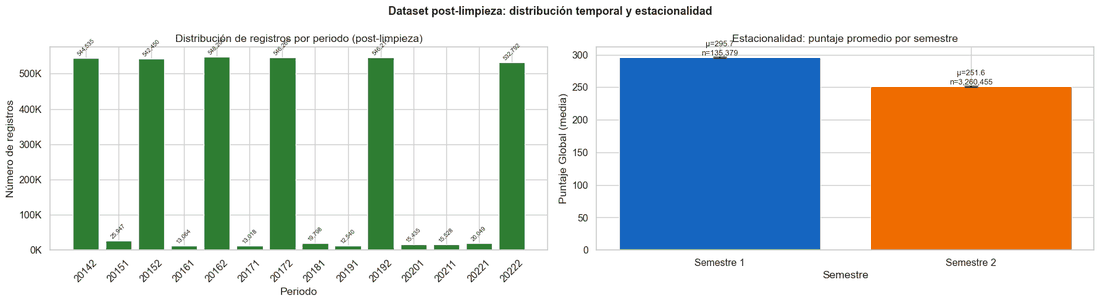

In [67]:
TARGET = "PUNT_GLOBAL"

period_counts_clean = df["PERIODO"].value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(18, 5))

# Registros por periodo (post-limpieza)
bars = axes[0].bar(period_counts_clean.index.astype(str), period_counts_clean.values,
                   color="#2e7d32", edgecolor="white")
for bar, val in zip(bars, period_counts_clean.values):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 3000,
                 f"{val:,}", ha="center", va="bottom", fontsize=7, rotation=45)
axes[0].set_xlabel("Periodo")
axes[0].set_ylabel("Número de registros")
axes[0].set_title("Distribución de registros por periodo (post-limpieza)")
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1e3:.0f}K"))
axes[0].tick_params(axis="x", rotation=45)

# Estacionalidad: media de registros por semestre (1 vs 2)
df["SEMESTRE"] = df["PERIODO"] % 10
sem_stats = df.groupby("SEMESTRE")[TARGET].agg(["mean", "std", "count"])
bars2 = axes[1].bar(sem_stats.index.astype(str), sem_stats["mean"],
                    yerr=sem_stats["std"] / 50, color=["#1565c0", "#ef6c00"],
                    edgecolor="white", capsize=8)
for bar, row in zip(bars2, sem_stats.itertuples()):
    axes[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1,
                 f"μ={row.mean:.1f}\nn={row.count:,}", ha="center", va="bottom", fontsize=9)
axes[1].set_xlabel("Semestre")
axes[1].set_ylabel("Puntaje Global (media)")
axes[1].set_title("Estacionalidad: puntaje promedio por semestre")
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["Semestre 1", "Semestre 2"])

plt.suptitle("Dataset post-limpieza: distribución temporal y estacionalidad",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

La gráfica de estacionalidad confirma que existe una diferencia entre los puntajes promedio del semestre 1 y el semestre 2. Esto implica que para efectos del modelado, la variable `PERIODO` se descompondrá en **solo el componente de semestre** (1 o 2), descartando el componente de año. La razón es que lo relevante para la predicción no es el año específico sino la dinámica estacional del examen, que puede reflejar diferencias en la población presentada o en las condiciones de aplicación entre el primer y el segundo semestre.

### **2.3. Definición y Justificación de Variables de Interés**
---

La selección adecuada de variables es una etapa crítica en cualquier proyecto de *machine learning*. Variables irrelevantes o redundantes incrementan la complejidad computacional, introducen ruido y pueden degradar la capacidad de generalización del modelo (Guyon & Elisseeff, 2003). Además, en problemas de regresión, la inclusión de variables derivadas directamente de la variable objetivo constituye **fuga de datos** (*data leakage*), lo que produce estimaciones artificialmente optimistas del rendimiento del modelo (Kaufman et al., 2012).

A continuación se clasifican las 51 variables del conjunto de datos en tres categorías, con su respectiva justificación:

#### **Variables excluidas del modelado**

| Variable | Motivo de exclusión |
|----------|--------------------|
| `PUNT_INGLES` | **Data leakage**: puntaje por área que es componente directo de `PUNT_GLOBAL`. |
| `PUNT_MATEMATICAS` | **Data leakage**: idem. |
| `PUNT_SOCIALES_CIUDADANAS` | **Data leakage**: idem. |
| `PUNT_C_NATURALES` | **Data leakage**: idem. |
| `PUNT_LECTURA_CRITICA` | **Data leakage**: idem. |
| `DESEMP_INGLES` | **Data leakage**: desempeño derivado directamente de `PUNT_INGLES`. |
| `ESTU_CONSECUTIVO` | Identificador único del examinando; sin valor predictivo. |
| `COLE_COD_DANE_ESTABLECIMIENTO` | Código identificador del establecimiento; alta cardinalidad, sin utilidad para un modelo generalizable. |
| `COLE_COD_DANE_SEDE` | Idem para la sede. |
| `COLE_CODIGO_ICFES` | Código identificador del ICFES; idem. |
| `COLE_NOMBRE_ESTABLECIMIENTO` | Nombre textual; alta cardinalidad, no generalizable. |
| `COLE_NOMBRE_SEDE` | Idem. |
| `ESTU_TIPODOCUMENTO` | Tipo de documento de identidad; no relevante para el desempeño académico. |
| `ESTU_ESTADOINVESTIGACION` | Indica consentimiento de uso de datos; sin valor predictivo. |
| `ESTU_PAIS_RESIDE` | Cobertura casi total de un único valor (Colombia); varianza insuficiente. |
| `ESTU_NACIONALIDAD` | Idem. |
| `ESTU_PRIVADO_LIBERTAD` | Proporción extremadamente baja; varianza insuficiente. |
| `ESTU_ESTUDIANTE` | Casi todos los registros son "ESTUDIANTE"; varianza insuficiente. |
| `COLE_COD_DEPTO_UBICACION` | Código numérico redundante con `COLE_DEPTO_UBICACION`. |
| `COLE_COD_MCPIO_UBICACION` | Código numérico redundante con `COLE_MCPIO_UBICACION`. |
| `ESTU_COD_DEPTO_PRESENTACION` | Código numérico redundante con `ESTU_DEPTO_PRESENTACION`. |
| `ESTU_COD_MCPIO_PRESENTACION` | Código numérico redundante con `ESTU_MCPIO_PRESENTACION`. |
| `ESTU_COD_RESIDE_DEPTO` | Código numérico redundante con `ESTU_DEPTO_RESIDE`. |
| `ESTU_COD_RESIDE_MCPIO` | Código numérico redundante con `ESTU_MCPIO_RESIDE`. |
| `ESTU_FECHANACIMIENTO` | Formato textual que requiere transformación; se excluye en bruto pero se evaluará derivar la **edad** en la Fase 3. |

#### **Variable objetivo**

| Variable | Descripción |
|----------|-------------|
| `PUNT_GLOBAL` | Puntaje global de la prueba Saber 11 (variable continua a predecir). |

#### **Variables candidatas como predictoras**

Las siguientes variables se retienen como **candidatas a predictoras**, agrupadas por categoría temática. Su inclusión se justifica tanto por la literatura sobre determinantes del rendimiento académico (Sirin, 2005; Cerquera Losada et al., 2016; Rodríguez Rosero et al., 2021) como por su disponibilidad al momento de la predicción (es decir, son conocidas *antes* de que el estudiante presente el examen).

| Categoría | Variables candidatas | Justificación |
|-----------|---------------------|---------------|
| **Periodo** | `PERIODO` | Permite capturar tendencias temporales y cambios estructurales en el examen. |
| **Estudiante** | `ESTU_GENERO` | Las brechas de género en rendimiento académico son ampliamente documentadas (OECD, 2019). |
| **Ubicación del estudiante** | `ESTU_DEPTO_PRESENTACION`, `ESTU_MCPIO_PRESENTACION`, `ESTU_DEPTO_RESIDE`, `ESTU_MCPIO_RESIDE` | Las disparidades territoriales en Colombia inciden significativamente en el rendimiento (Demombynes, 2023). |
| **Colegio** | `COLE_AREA_UBICACION`, `COLE_BILINGUE`, `COLE_CALENDARIO`, `COLE_CARACTER`, `COLE_DEPTO_UBICACION`, `COLE_MCPIO_UBICACION`, `COLE_GENERO`, `COLE_JORNADA`, `COLE_NATURALEZA`, `COLE_SEDE_PRINCIPAL` | Características institucionales que reflejan condiciones estructurales del proceso educativo. |
| **Familia / Socioeconómico** | `FAMI_CUARTOSHOGAR`, `FAMI_EDUCACIONMADRE`, `FAMI_EDUCACIONPADRE`, `FAMI_ESTRATOVIVIENDA`, `FAMI_PERSONASHOGAR`, `FAMI_TIENEAUTOMOVIL`, `FAMI_TIENECOMPUTADOR`, `FAMI_TIENEINTERNET`, `FAMI_TIENELAVADORA` | La evidencia empírica muestra una asociación robusta entre el contexto socioeconómico familiar y el rendimiento en pruebas estandarizadas (Sirin, 2005; Reardon, 2011). |

En total se retienen **21 variables candidatas** como predictoras, 1 variable objetivo y se excluyen 29 variables.

In [68]:
TARGET = "PUNT_GLOBAL"

LEAKAGE_COLS = [
    "PUNT_INGLES", "PUNT_MATEMATICAS", "PUNT_SOCIALES_CIUDADANAS",
    "PUNT_C_NATURALES", "PUNT_LECTURA_CRITICA", "DESEMP_INGLES",
]

ID_COLS = [
    "ESTU_CONSECUTIVO", "COLE_COD_DANE_ESTABLECIMIENTO", "COLE_COD_DANE_SEDE",
    "COLE_CODIGO_ICFES", "COLE_NOMBRE_ESTABLECIMIENTO", "COLE_NOMBRE_SEDE",
]

LOW_INFO_COLS = [
    "ESTU_TIPODOCUMENTO", "ESTU_ESTADOINVESTIGACION", "ESTU_PAIS_RESIDE",
    "ESTU_NACIONALIDAD", "ESTU_PRIVADO_LIBERTAD", "ESTU_ESTUDIANTE",
]

REDUNDANT_CODE_COLS = [
    "COLE_COD_DEPTO_UBICACION", "COLE_COD_MCPIO_UBICACION",
    "ESTU_COD_DEPTO_PRESENTACION", "ESTU_COD_MCPIO_PRESENTACION",
    "ESTU_COD_RESIDE_DEPTO", "ESTU_COD_RESIDE_MCPIO",
]

TRANSFORM_LATER = ["ESTU_FECHANACIMIENTO"]

EXCLUDE_COLS = LEAKAGE_COLS + ID_COLS + LOW_INFO_COLS + REDUNDANT_CODE_COLS + TRANSFORM_LATER + [TARGET]

CANDIDATE_FEATURES = [c for c in df.columns if c not in EXCLUDE_COLS]

print(f"Variable objetivo           : {TARGET}")
print(f"Variables excluidas          : {len(EXCLUDE_COLS) - 1}")
print(f"Variables candidatas (pred.) : {len(CANDIDATE_FEATURES)}")
print(f"\nListado de candidatas:")
for i, col in enumerate(CANDIDATE_FEATURES, 1):
    print(f"  {i:2d}. {col}")

Variable objetivo           : PUNT_GLOBAL
Variables excluidas          : 25
Variables candidatas (pred.) : 26

Listado de candidatas:
   1. PERIODO
   2. COLE_AREA_UBICACION
   3. COLE_BILINGUE
   4. COLE_CALENDARIO
   5. COLE_CARACTER
   6. COLE_DEPTO_UBICACION
   7. COLE_GENERO
   8. COLE_JORNADA
   9. COLE_MCPIO_UBICACION
  10. COLE_NATURALEZA
  11. COLE_SEDE_PRINCIPAL
  12. ESTU_DEPTO_PRESENTACION
  13. ESTU_DEPTO_RESIDE
  14. ESTU_GENERO
  15. ESTU_MCPIO_PRESENTACION
  16. ESTU_MCPIO_RESIDE
  17. FAMI_CUARTOSHOGAR
  18. FAMI_EDUCACIONMADRE
  19. FAMI_EDUCACIONPADRE
  20. FAMI_ESTRATOVIVIENDA
  21. FAMI_PERSONASHOGAR
  22. FAMI_TIENEAUTOMOVIL
  23. FAMI_TIENECOMPUTADOR
  24. FAMI_TIENEINTERNET
  25. FAMI_TIENELAVADORA
  26. SEMESTRE


### **2.4. Análisis Descriptivo de la Variable Objetivo**
---

Antes de examinar las variables predictoras, se realiza un análisis detallado de `PUNT_GLOBAL` para comprender su distribución, rango y comportamiento a lo largo del tiempo. Dado que esta es la variable que el modelo deberá predecir, conocer sus características es fundamental para elegir métricas de evaluación adecuadas y detectar anomalías.

In [ ]:
target = df[TARGET].dropna()

print(f"Registros con PUNT_GLOBAL no nulo: {len(target):,} ({len(target)/len(df)*100:.1f}%)")
print(f"Registros con PUNT_GLOBAL nulo   : {df[TARGET].isna().sum():,}\n")
print(target.describe().to_string())

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].hist(target, bins=80, color="#2e7d32", edgecolor="white", alpha=0.85, density=True)
target.plot.kde(ax=axes[0], color="#c62828", linewidth=2)
axes[0].set_title("Distribución de PUNT_GLOBAL")
axes[0].set_xlabel("Puntaje Global")
axes[0].set_ylabel("Densidad")
axes[0].axvline(target.mean(), color="#1565c0", linestyle="--", label=f"Media = {target.mean():.1f}")
axes[0].axvline(target.median(), color="#ef6c00", linestyle="--", label=f"Mediana = {target.median():.1f}")
axes[0].legend(fontsize=9)

axes[1].boxplot(target, vert=True, widths=0.5,
                boxprops=dict(color="#2e7d32"), medianprops=dict(color="#c62828", linewidth=2),
                whiskerprops=dict(color="#2e7d32"), capprops=dict(color="#2e7d32"),
                flierprops=dict(marker=".", markersize=1, alpha=0.3))
axes[1].set_title("Diagrama de caja de PUNT_GLOBAL")
axes[1].set_ylabel("Puntaje Global")
axes[1].set_xticks([])

yearly_stats = df.dropna(subset=[TARGET]).groupby("PERIODO")[TARGET].agg(["mean", "median", "std"])
axes[2].plot(yearly_stats.index.astype(str), yearly_stats["mean"], "o-", color="#1565c0", label="Media")
axes[2].plot(yearly_stats.index.astype(str), yearly_stats["median"], "s--", color="#ef6c00", label="Mediana")
axes[2].fill_between(yearly_stats.index.astype(str),
                      yearly_stats["mean"] - yearly_stats["std"],
                      yearly_stats["mean"] + yearly_stats["std"],
                      alpha=0.15, color="#1565c0", label="±1 desv. est.")
axes[2].set_title("Evolución temporal de PUNT_GLOBAL")
axes[2].set_xlabel("Periodo")
axes[2].set_ylabel("Puntaje Global")
axes[2].legend(fontsize=8)
axes[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

### **2.5. Análisis Descriptivo de Variables Categóricas Candidatas**
---

Se examinan las distribuciones de las principales variables categóricas candidatas y su relación univariada con `PUNT_GLOBAL`, lo que permite identificar variables con poder discriminante y posibles problemas de desbalanceo de clases.

In [ ]:
df_valid = df.dropna(subset=[TARGET]).copy()

cat_features_key = [
    "ESTU_GENERO", "COLE_AREA_UBICACION", "COLE_NATURALEZA", "COLE_BILINGUE",
    "COLE_JORNADA", "COLE_CALENDARIO", "COLE_CARACTER", "COLE_GENERO",
    "FAMI_ESTRATOVIVIENDA", "FAMI_EDUCACIONMADRE", "FAMI_EDUCACIONPADRE",
    "FAMI_TIENEINTERNET", "FAMI_TIENECOMPUTADOR", "FAMI_TIENEAUTOMOVIL", "FAMI_TIENELAVADORA",
]

n_cols = 3
n_rows = (len(cat_features_key) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 5.5))
axes = axes.flatten()

for idx, col in enumerate(cat_features_key):
    ax = axes[idx]
    order = df_valid.groupby(col)[TARGET].median().sort_values().index
    sns.boxplot(data=df_valid, x=col, y=TARGET, order=order, ax=ax,
                palette="YlGn", showfliers=False, linewidth=0.8)
    ax.set_title(f"{col} vs {TARGET}", fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("Puntaje Global" if idx % n_cols == 0 else "")
    n_cats = len(order)
    if n_cats > 6:
        ax.set_xticklabels(ax.get_xticklabels(), rotation=55, ha="right", fontsize=6)
    else:
        ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha="right", fontsize=7)

for idx in range(len(cat_features_key), len(axes)):
    axes[idx].set_visible(False)

plt.suptitle("Distribución de PUNT_GLOBAL según variables categóricas candidatas",
             fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

#### **Observaciones clave de las variables categóricas**

Las visualizaciones anteriores permiten extraer información relevante para la selección y el preprocesamiento de variables:

- **`FAMI_ESTRATOVIVIENDA`**: se observa una relación monotónica creciente entre el estrato socioeconómico y el puntaje global, coherente con la literatura sobre la relación entre nivel socioeconómico y rendimiento académico (Sirin, 2005).
- **`FAMI_EDUCACIONMADRE` / `FAMI_EDUCACIONPADRE`**: a mayor nivel educativo de los padres, mayor el puntaje promedio. Este hallazgo es consistente con la evidencia empírica sobre capital cultural y logro educativo (Rodríguez Rosero et al., 2021).
- **`COLE_AREA_UBICACION`**: las instituciones urbanas presentan medianas significativamente más altas que las rurales, reflejando las brechas territoriales documentadas por Demombynes (2023).
- **`COLE_NATURALEZA`**: los colegios no oficiales (privados) muestran puntajes promedio más elevados que los oficiales.
- **`COLE_BILINGUE`**: los colegios bilingües presentan puntajes notablemente superiores.
- **`FAMI_TIENEINTERNET` / `FAMI_TIENECOMPUTADOR`**: el acceso a recursos tecnológicos se asocia con puntajes más altos, lo cual subraya la relevancia de la brecha digital.

### **2.6. Distribución de las Variables Categóricas (Frecuencias)**
---

Se presenta la distribución de frecuencias de cada variable categórica candidata, lo que permite identificar categorías con baja representación o desbalanceo extremo que deberán tratarse en la fase de preparación.

In [ ]:
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 4))
axes = axes.flatten()

for idx, col in enumerate(cat_features_key):
    ax = axes[idx]
    counts = df_valid[col].value_counts()
    if len(counts) > 15:
        counts = counts.head(15)
    bars = ax.barh(counts.index.astype(str), counts.values, color="#43a047", edgecolor="white")
    ax.set_title(f"{col} (n={df_valid[col].nunique()} cat.)", fontsize=10)
    ax.set_xlabel("Frecuencia")
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1e6:.1f}M" if x >= 1e6 else f"{x/1e3:.0f}K"))
    ax.invert_yaxis()
    ax.tick_params(axis="y", labelsize=7)

for idx in range(len(cat_features_key), len(axes)):
    axes[idx].set_visible(False)

plt.suptitle("Distribución de frecuencias de variables categóricas candidatas",
             fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

### **2.7. Relación entre Variables**
---

En esta sección se analizan las relaciones entre las variables numéricas disponibles y se evalúa la existencia de redundancias o correlaciones fuertes que podrían afectar el modelado. Dado que la mayoría de las variables candidatas son categóricas (codificadas como texto), el análisis de correlación lineal se centra en las variables originalmente numéricas del dataset.

#### **2.7.1. Correlación entre puntajes por área y puntaje global**

Aunque los puntajes por área (`PUNT_INGLES`, `PUNT_MATEMATICAS`, etc.) fueron excluidos como predictores por constituir *data leakage*, resulta informativo visualizar su correlación con `PUNT_GLOBAL` para confirmar la composición de este último y validar la decisión de exclusión.

In [73]:
score_cols = ["PUNT_INGLES", "PUNT_MATEMATICAS", "PUNT_SOCIALES_CIUDADANAS",
              "PUNT_C_NATURALES", "PUNT_LECTURA_CRITICA", "PUNT_GLOBAL"]

df_scores = df[score_cols].dropna()

for col in score_cols:
    df_scores[col] = pd.to_numeric(df_scores[col], errors="coerce")
df_scores = df_scores.dropna()

corr = df_scores.corr()

fig, ax = plt.subplots(figsize=(8, 6))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1,
            mask=mask, linewidths=0.5, ax=ax, square=True, annot_kws={"fontsize": 10})
ax.set_title("Correlación entre puntajes por área y puntaje global", fontsize=12)
plt.tight_layout()
plt.show()

print("\nCorrelación de cada puntaje de área con PUNT_GLOBAL:")
for c in score_cols[:-1]:
    print(f"  {c:30s} → r = {corr.loc[c, TARGET]:.3f}")
print("\n→ Las correlaciones muy altas confirman que los puntajes por área son componentes directos")
print("  de PUNT_GLOBAL y su inclusión como predictores constituiría data leakage (Kaufman et al., 2012).")

Correlación de cada puntaje de área con PUNT_GLOBAL:
  PUNT_INGLES                    → r = 0.780
  PUNT_MATEMATICAS               → r = 0.901
  PUNT_SOCIALES_CIUDADANAS       → r = 0.908
  PUNT_C_NATURALES               → r = 0.912
  PUNT_LECTURA_CRITICA           → r = 0.889

→ Las correlaciones muy altas confirman que los puntajes por área son componentes directos
  de PUNT_GLOBAL y su inclusión como predictores constituiría data leakage (Kaufman et al., 2012).


#### **2.7.2. Efecto de las variables socioeconómicas sobre PUNT_GLOBAL**

Las variables socioeconómicas del dataset son en su mayoría **categóricas binarias** (Sí/No) u **ordinales** (con un orden natural, como el estrato o el nivel educativo). Para cuantificar su relación con `PUNT_GLOBAL` se emplean dos enfoques complementarios:

1. **Análisis tabular de medias por categoría**: muestra el puntaje promedio para cada nivel de la variable y el rango entre la categoría más alta y la más baja, lo que permite apreciar la magnitud del efecto de forma directa.
2. **Correlación numérica**: se codifican las variables binarias como 0/1 y las ordinales como enteros según su orden natural, y se calcula la **correlación de Spearman** (ρ) con `PUNT_GLOBAL`. Esta medida no paramétrica captura relaciones monótonas sin asumir linealidad (Spearman, 1904), lo que resulta adecuado para variables ordinales.

In [ ]:
socioec_vars = [
    "FAMI_ESTRATOVIVIENDA", "FAMI_EDUCACIONMADRE", "FAMI_EDUCACIONPADRE",
    "FAMI_TIENEINTERNET", "FAMI_TIENECOMPUTADOR", "FAMI_TIENEAUTOMOVIL",
    "FAMI_TIENELAVADORA", "FAMI_CUARTOSHOGAR", "FAMI_PERSONASHOGAR",
]

print("Media de PUNT_GLOBAL según variables socioeconómicas:\n")
for var in socioec_vars:
    group_means = df_valid.groupby(var)[TARGET].mean().sort_values(ascending=False)
    rango = group_means.max() - group_means.min()
    print(f"{'='*70}")
    print(f"{var}  (rango de medias: {rango:.1f} puntos)")
    print(f"{'='*70}")
    for cat, mean_val in group_means.items():
        n = (df_valid[var] == cat).sum()
        print(f"  {str(cat):45s}  media={mean_val:6.1f}  n={n:>10,}")
    print()

In [ ]:
from scipy.stats import spearmanr

ordinal_maps = {
    "FAMI_ESTRATOVIVIENDA": {"Sin Estrato": 0, "Estrato 1": 1, "Estrato 2": 2, "Estrato 3": 3,
                              "Estrato 4": 4, "Estrato 5": 5, "Estrato 6": 6},
    "FAMI_EDUCACIONMADRE": {
        "Ninguno": 0, "No sabe": 0, "Primaria incompleta": 1, "Primaria completa": 2,
        "Secundaria (Bachillerato) incompleta": 3, "Secundaria (Bachillerato) completa": 4,
        "Técnica o tecnológica incompleta": 5, "Técnica o tecnológica completa": 6,
        "Educación profesional incompleta": 7, "Educación profesional completa": 8,
        "Postgrado": 9,
    },
    "FAMI_EDUCACIONPADRE": {
        "Ninguno": 0, "No sabe": 0, "Primaria incompleta": 1, "Primaria completa": 2,
        "Secundaria (Bachillerato) incompleta": 3, "Secundaria (Bachillerato) completa": 4,
        "Técnica o tecnológica incompleta": 5, "Técnica o tecnológica completa": 6,
        "Educación profesional incompleta": 7, "Educación profesional completa": 8,
        "Postgrado": 9,
    },
    "FAMI_CUARTOSHOGAR": {"Uno": 1, "Dos": 2, "Tres": 3, "Cuatro": 4, "Cinco": 5,
                           "Seis": 6, "Siete": 7, "Ocho o más": 8},
    "FAMI_PERSONASHOGAR": {"1 a 2": 1, "3 a 4": 2, "5 a 6": 3, "7 a 8": 4, "9 a 10": 5,
                            "11 a 12": 6, "Más de 12": 7},
}

binary_maps = {
    "FAMI_TIENEINTERNET": {"No": 0, "Si": 1},
    "FAMI_TIENECOMPUTADOR": {"No": 0, "Si": 1},
    "FAMI_TIENEAUTOMOVIL": {"No": 0, "Si": 1},
    "FAMI_TIENELAVADORA": {"No": 0, "Si": 1},
}

all_maps = {**ordinal_maps, **binary_maps}

results = []
sample_corr = df_valid.sample(n=min(300_000, len(df_valid)), random_state=SEED)

for var, mapping in all_maps.items():
    encoded = sample_corr[var].map(mapping).dropna()
    target_aligned = sample_corr.loc[encoded.index, TARGET]
    rho, pval = spearmanr(encoded, target_aligned)
    results.append({"Variable": var, "ρ Spearman": rho, "p-valor": pval,
                    "Tipo": "Ordinal" if var in ordinal_maps else "Binaria"})

corr_df = pd.DataFrame(results).sort_values("ρ Spearman", key=abs, ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
colors = ["#2e7d32" if r > 0 else "#c62828" for r in corr_df["ρ Spearman"]]
ax.barh(corr_df["Variable"], corr_df["ρ Spearman"], color=colors, edgecolor="white")
ax.axvline(0, color="black", linewidth=0.8)
for bar, rho in zip(ax.patches, corr_df["ρ Spearman"].values):
    ax.text(bar.get_width() + (0.005 if rho >= 0 else -0.005), bar.get_y() + bar.get_height() / 2,
            f"{rho:.3f}", va="center", ha="left" if rho >= 0 else "right", fontsize=9)
ax.set_xlabel("Correlación de Spearman (ρ) con PUNT_GLOBAL")
ax.set_title("Correlación de variables socioeconómicas con el puntaje global", fontsize=12)
ax.invert_yaxis()
plt.tight_layout()
plt.show()

print("\nResumen de correlaciones:")
print(corr_df.to_string(index=False))

Las correlaciones de Spearman confirman cuantitativamente las tendencias observadas en los boxplots (sección 2.5) y en las tablas de medias. Las variables con mayor asociación con `PUNT_GLOBAL` son el **estrato de vivienda** y la **educación de los padres** (correlaciones positivas moderadas), seguidas por el **acceso a internet y computador**. Estas relaciones son coherentes con la evidencia sobre la influencia del capital socioeconómico y cultural en el rendimiento académico (Sirin, 2005; Cerquera Losada et al., 2016). La variable `FAMI_PERSONASHOGAR` muestra una correlación negativa, lo que indica que hogares más numerosos tienden a asociarse con puntajes menores, posiblemente mediado por la distribución de recursos dentro del hogar.

#### **2.7.3. Análisis de variables geográficas**

Se examina la variabilidad del puntaje global a nivel departamental para confirmar la existencia de brechas territoriales, aspecto central en la justificación del proyecto (Fase 1, sección 1.1).

In [ ]:
df_valid["COLE_DEPTO_UBICACION"] = (
    df_valid["COLE_DEPTO_UBICACION"]
    .str.strip()
    .str.upper()
    .replace({"BOGOTA": "BOGOTÁ"})
)

dept_stats = (
    df_valid.groupby("COLE_DEPTO_UBICACION")[TARGET]
    .agg(["mean", "median", "std", "count"])
    .sort_values("mean", ascending=True)
)

fig, ax = plt.subplots(figsize=(12, 10))
colors = plt.cm.RdYlGn(np.linspace(0, 1, len(dept_stats)))
ax.barh(dept_stats.index, dept_stats["mean"], xerr=dept_stats["std"] / 10,
        color=colors, edgecolor="white", linewidth=0.5, capsize=2)
ax.axvline(df_valid[TARGET].mean(), color="#c62828", linestyle="--", linewidth=1.5,
           label=f"Media nacional = {df_valid[TARGET].mean():.1f}")
ax.set_xlabel("Puntaje Global (media)")
ax.set_title("Puntaje Global promedio por departamento de ubicación del colegio", fontsize=12)
ax.legend(fontsize=10)
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

brecha = dept_stats["mean"].max() - dept_stats["mean"].min()
print(f"Brecha departamental máxima en puntaje promedio: {brecha:.1f} puntos")
print(f"Departamento con mayor media : {dept_stats['mean'].idxmax()} ({dept_stats['mean'].max():.1f})")
print(f"Departamento con menor media : {dept_stats['mean'].idxmin()} ({dept_stats['mean'].min():.1f})")

#### **2.7.4. Identificación de redundancias entre variables predictoras**

Se evalúa si existen variables categóricas altamente asociadas entre sí (redundantes) que podrían excluirse para reducir la dimensionalidad sin pérdida de información. Se utiliza el coeficiente **V de Cramér** como medida de asociación entre pares de variables categóricas (Cramér, 1946).

In [ ]:
from scipy.stats import chi2_contingency

def cramers_v(x, y):
    """Calcula el coeficiente V de Cramér entre dos variables categóricas."""
    ct = pd.crosstab(x, y)
    chi2 = chi2_contingency(ct)[0]
    n = ct.sum().sum()
    min_dim = min(ct.shape[0], ct.shape[1]) - 1
    if min_dim == 0 or n == 0:
        return 0.0
    return np.sqrt(chi2 / (n * min_dim))

cat_candidates = [c for c in CANDIDATE_FEATURES if df_valid[c].dtype == "object"]

sample = df_valid.sample(n=min(200_000, len(df_valid)), random_state=SEED)

n_cat = len(cat_candidates)
cramer_matrix = pd.DataFrame(np.zeros((n_cat, n_cat)), index=cat_candidates, columns=cat_candidates)

for i in range(n_cat):
    for j in range(i, n_cat):
        if i == j:
            cramer_matrix.iloc[i, j] = 1.0
        else:
            v = cramers_v(sample[cat_candidates[i]].fillna("NaN"),
                          sample[cat_candidates[j]].fillna("NaN"))
            cramer_matrix.iloc[i, j] = v
            cramer_matrix.iloc[j, i] = v

fig, ax = plt.subplots(figsize=(14, 12))
mask = np.triu(np.ones_like(cramer_matrix, dtype=bool), k=1)
sns.heatmap(cramer_matrix.astype(float), annot=True, fmt=".2f", cmap="YlOrRd",
            vmin=0, vmax=1, mask=mask, linewidths=0.5, ax=ax, square=True,
            annot_kws={"fontsize": 7})
ax.set_title("Asociación entre variables categóricas candidatas (V de Cramér)", fontsize=12)
ax.tick_params(axis="both", labelsize=8)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print("\nPares con V de Cramér ≥ 0.7 (alta redundancia):")
high_corr_pairs = []
for i in range(n_cat):
    for j in range(i + 1, n_cat):
        v = cramer_matrix.iloc[i, j]
        if v >= 0.7:
            high_corr_pairs.append((cat_candidates[i], cat_candidates[j], v))
            print(f"  {cat_candidates[i]} ↔ {cat_candidates[j]} : V = {v:.3f}")
if not high_corr_pairs:
    print("  Ninguno.")

### **2.8. Análisis de Valores Atípicos en la Variable Objetivo**
---

Se identifican valores atípicos en `PUNT_GLOBAL` utilizando el método del rango intercuartílico (IQR), lo que permite evaluar si existen registros extremos que podrían afectar negativamente el entrenamiento del modelo.

In [ ]:
Q1 = target.quantile(0.25)
Q3 = target.quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = target[(target < lower) | (target > upper)]

print(f"Q1 = {Q1:.1f}, Q3 = {Q3:.1f}, IQR = {IQR:.1f}")
print(f"Límite inferior: {lower:.1f}")
print(f"Límite superior: {upper:.1f}")
print(f"\nValores atípicos detectados: {len(outliers):,} ({len(outliers)/len(target)*100:.2f}%)")
print(f"  - Por debajo del límite inferior: {(target < lower).sum():,}")
print(f"  - Por encima del límite superior: {(target > upper).sum():,}")

## **3. Síntesis de Hallazgos y Decisiones para la Fase 3**
---

A partir del análisis exploratorio realizado, se resumen los hallazgos principales y las decisiones que orientarán la fase de **preparación de los datos** (Fase 3):

### **Hallazgos principales**

1. **Duplicados y limpieza temporal**: se detectaron registros duplicados por la clave `ESTU_CONSECUTIVO` + `PERIODO`, concentrados predominantemente en los periodos 2019-4 y 2022-4. Se eliminaron conservando la primera aparición. Adicionalmente, se corrigió la nomenclatura de periodos (`4` → `2`) según la documentación oficial del ICFES, y se excluyeron los periodos anteriores a 2014-2, que no contienen `PUNT_GLOBAL` debido al cambio metodológico del examen (Icfes, 2024).

2. **Variable objetivo (`PUNT_GLOBAL`)**: tras la limpieza, presenta una distribución aproximadamente normal con ligera asimetría negativa. La media se sitúa alrededor de 250 puntos. Se detectan pocos valores atípicos por el método IQR, lo que indica que la distribución es relativamente contenida.

3. **Estacionalidad**: se identificó una diferencia sistemática en el puntaje promedio entre semestre 1 y semestre 2. Para el modelado, la variable `PERIODO` se descompondrá en el componente de **semestre** (1 o 2), descartando el año, ya que es la dinámica estacional —no el año específico— lo que aporta información predictiva.

4. **Periodos faltantes**: se observa la ausencia de datos para tres periodos del segundo semestre: **2018-2** (cuyo archivo en la [página oficial del ICFES](https://www.icfes.gov.co/evaluaciones-icfes/saber-11/otros-resultados-examen-saber-11-old/) se encuentra corrupto), y **2020-2** y **2021-2** (probablemente vinculada a las disrupciones por la pandemia COVID-19). Dado el volumen restante de datos, se considera razonable proceder sin esta información.

5. **Completitud de los datos**: las variables candidatas como predictoras presentan porcentajes de nulidad generalmente bajos tras el filtrado temporal. Las columnas con nulidad alta corresponden principalmente a variables de puntaje por área en periodos anteriores a la reestructuración, que ya fueron excluidos.

6. **Data leakage confirmado**: la correlación entre los puntajes por área y `PUNT_GLOBAL` es extremadamente alta (r > 0.7 en todos los casos), confirmando que son componentes directos del puntaje global. **Su exclusión es imprescindible** para garantizar la validez del modelo (Kaufman et al., 2012).

7. **Variables socioeconómicas con alto poder discriminante**: el análisis de medias y la correlación de Spearman confirman que el estrato de vivienda (ρ ≈ 0.3), la educación de los padres (ρ ≈ 0.25–0.30) y el acceso a internet/computador (ρ ≈ 0.15–0.20) son los predictores socioeconómicos con mayor asociación con `PUNT_GLOBAL`, con diferencias de hasta 60+ puntos entre categorías extremas. Estos resultados son coherentes con la literatura (Sirin, 2005; Cerquera Losada et al., 2016).

8. **Brechas territoriales marcadas**: se confirmó una brecha departamental significativa tras consolidar las variantes de "BOGOTÁ"/"BOGOTA". La diferencia entre el departamento con mayor y menor puntaje promedio supera los 60 puntos, coherente con la evidencia sobre desigualdad territorial en Colombia (Demombynes, 2023; OECD, 2019).

9. **Redundancia entre predictores**: el análisis de V de Cramér entre variables categóricas no reveló pares con asociación superior a 0.7 entre las variables candidatas, lo que indica que la redundancia informativa es baja y no se requieren eliminaciones adicionales por este concepto.

### **Decisiones para la Fase 3 (Preparación de los Datos)**

| Aspecto | Decisión |
|---------|----------|
| Duplicados por clave | **Ya eliminados** en esta fase. |
| Periodos con nomenclatura `4` | **Ya corregidos** a `2` en esta fase. |
| Periodos anteriores a 2014-2 | **Ya excluidos** por ausencia de `PUNT_GLOBAL` (cambio metodológico ICFES). |
| Registros nulos en `PUNT_GLOBAL` | Eliminar (no es posible imputar la variable objetivo). |
| Inconsistencias textuales (e.g., "BOGOTÁ" vs "BOGOTA") | **Ya corregidas** en esta fase para las variables geográficas. |
| Variables de *leakage* | Excluir definitivamente las 6 variables de puntaje/desempeño por área. |
| Variables de identificación | Excluir las 6 variables de ID/nombre. |
| Variables de baja varianza | Excluir las 6 variables con información insuficiente. |
| Códigos numéricos redundantes | Excluir las 6 columnas de códigos redundantes con sus equivalentes textuales. |
| `PERIODO` | Transformar a variable binaria de **semestre** (1 o 2). |
| `ESTU_FECHANACIMIENTO` | Evaluar la derivación de la variable **edad al momento del examen**. |
| Variables categóricas ordinales | Aplicar **codificación ordinal** (estrato, educación padres, cuartos, personas en hogar). |
| Variables categóricas nominales | Aplicar *one-hot encoding* o *target encoding* según cardinalidad. |
| Variables geográficas (municipio) | Evaluar agregación a nivel departamental para reducir la alta cardinalidad. |
| Valores nulos en predictores | Imputar o tratar según el porcentaje y la naturaleza de cada variable. |
| División del conjunto | Estratificar por semestre para garantizar representatividad en train/validation/test. |

---
# **Fase 3 — Preparación de los Datos**
---

Esta fase corresponde a la **preparación de los datos** dentro de la metodología CRISP-DM (Chapman et al., 2000), cuyo objetivo es transformar el conjunto de datos crudo en un formato apto para el modelado predictivo. Según Pyle (1999), la preparación de datos suele consumir entre el 60% y el 80% del esfuerzo total de un proyecto de analítica, y la calidad de esta etapa determina en gran medida el desempeño del modelo final.

**Contexto del proyecto (referencia a fases anteriores):**
- En la **Fase 1** (sección 1.1) se definió el problema como una tarea de **regresión supervisada** para predecir `PUNT_GLOBAL` en las pruebas Saber 11 a partir de variables socioeconómicas, familiares, institucionales y geográficas.
- En la **Fase 2** (secciones 2.1–2.8) se realizó el análisis exploratorio, se identificaron y eliminaron duplicados, se corrigió la nomenclatura de periodos, se filtró el dataset a periodos ≥ 2014-2, y se definieron las variables candidatas. El *dataset de trabajo* resultante se utiliza como punto de partida para esta fase.

**Objetivos de esta fase:**
1. **Limpieza del conjunto de datos**: tratar valores faltantes, duplicados, atípicos, inconsistencias y datos corruptos, documentando los criterios y decisiones adoptados.
2. **Preprocesamiento y transformación**: codificar variables categóricas, crear nuevas características (*feature engineering*), y preparar el dataset para algoritmos de *machine learning*.
3. **Selección y partición del conjunto de datos**: justificar la selección final de variables y dividir el dataset en conjuntos de entrenamiento, validación y prueba.

> **Nota sobre organización del código:** Esta fase toma como entrada el DataFrame `df` resultante de la limpieza realizada en la Fase 2 (sección 2.2.5). Las definiciones de constantes como `TARGET`, `CANDIDATE_FEATURES`, `LEAKAGE_COLS`, etc., provienen de la Fase 2 (sección 2.3). No se repite código ya ejecutado en fases anteriores.

## **1. Estado Actual del Dataset (Post-Fase 2)**
---

Antes de iniciar el preprocesamiento, se verifica el estado del dataset resultante de las operaciones de limpieza realizadas en la Fase 2 (sección 2.2.5: eliminación de duplicados, corrección de nomenclatura de periodos y filtrado temporal).

In [ ]:
print("=" * 70)
print("ESTADO DEL DATASET — INICIO DE FASE 3")
print("=" * 70)
print(f"Dimensiones: {df.shape[0]:,} filas × {df.shape[1]} columnas")
print(f"Periodos:    {sorted(df['PERIODO'].unique())}")
print(f"Memoria:     {df.memory_usage(deep=True).sum() / 1e9:.2f} GB")
print(f"\nVariable objetivo: {TARGET}")
print(f"  - Registros no nulos: {df[TARGET].notna().sum():,} ({df[TARGET].notna().mean()*100:.1f}%)")
print(f"  - Registros nulos:    {df[TARGET].isna().sum():,}")
print(f"\nVariables candidatas ({len(CANDIDATE_FEATURES)}):")
for i, col in enumerate(CANDIDATE_FEATURES, 1):
    dtype = df[col].dtype
    nulls = df[col].isna().sum()
    pct = nulls / len(df) * 100
    print(f"  {i:2d}. {col:40s} tipo={str(dtype):8s} nulos={nulls:>10,} ({pct:.2f}%)")

## **2. Limpieza de los Datos**
---

La limpieza de datos es un proceso iterativo que busca garantizar la integridad, consistencia y representatividad del conjunto de datos antes del modelado (Rahm & Do, 2000). A continuación se abordan los criterios y acciones adoptados para cada tipo de anomalía, respondiendo a las preguntas planteadas en la guía del curso.

> **Criterios generales utilizados:**
> - Cada decisión se justifica en función de su impacto sobre la calidad de los datos y la validez del análisis subsiguiente.
> - Se prioriza la preservación de la mayor cantidad posible de registros para mantener la representatividad de la muestra.
> - Se documenta el estado del dataset antes y después de cada intervención.

### **2.1. Valores Faltantes**
---

Los valores faltantes pueden introducir sesgos y reducir la potencia estadística del análisis (Little & Rubin, 2019). Es fundamental entender su patrón de aparición —*Missing Completely at Random* (MCAR), *Missing at Random* (MAR) o *Missing Not at Random* (MNAR)— para elegir la estrategia de tratamiento adecuada (Rubin, 1976).

**Preguntas clave:**
- ¿Cómo se identificaron los valores faltantes?
- ¿Cuáles fueron los criterios para decidir entre imputar o eliminar?
- ¿Qué método de imputación se utilizó y por qué?

**Referencia a la Fase 2:** En la sección 2.2.1 se presentó el análisis de valores faltantes por columna, y en la sección 2.2.2 se analizó el patrón de nulidad por periodo. Aquí se implementan las decisiones de tratamiento.

In [ ]:
df_prep = df.copy()
initial_shape = df_prep.shape
print(f"Dimensiones iniciales: {initial_shape[0]:,} × {initial_shape[1]}")

analysis_cols = CANDIDATE_FEATURES + [TARGET]
null_in_candidates = pd.DataFrame({
    "Nulos": df_prep[analysis_cols].isnull().sum(),
    "% Nulos": (df_prep[analysis_cols].isnull().sum() / len(df_prep) * 100).round(2),
    "Tipo": df_prep[analysis_cols].dtypes,
}).sort_values("% Nulos", ascending=False)

print("\nValores faltantes en variables candidatas y variable objetivo:\n")
print(null_in_candidates[null_in_candidates["% Nulos"] > 0].to_string())
print(f"\nColumnas sin nulos: {(null_in_candidates['% Nulos'] == 0).sum()} de {len(analysis_cols)}")

#### **Decisiones de tratamiento de valores faltantes**

Se adopta la siguiente estrategia diferenciada, justificada por el tipo y la proporción de datos faltantes:

| Tipo de variable | Estrategia | Justificación |
|------------------|-----------|---------------|
| **Variable objetivo** (`PUNT_GLOBAL`) | Eliminación de filas nulas | Un registro sin la variable objetivo no puede usarse ni para entrenamiento ni para evaluación. La proporción de nulos es pequeña. |
| **Variables binarias** (`FAMI_TIENE*`) | Imputación con la moda | Las variables binarias tienen una distribución claramente dominante; la moda preserva la distribución marginal (van Buuren, 2018). |
| **Variables ordinales familiares** (`FAMI_EDUCACION*`, `FAMI_ESTRATO*`, etc.) | Creación de categoría `"No reporta"` | Tratar la no-respuesta como categoría explícita evita introducir sesgo por imputación y captura el efecto de la no-respuesta como señal informativa (Saar-Tsechansky & Provost, 2007). |
| **Variables categóricas del colegio/estudiante** con baja tasa de nulos | Imputación con la moda | Para tasas < 2%, la imputación con moda tiene impacto mínimo en la distribución (Allison, 2001). |
| **Variables geográficas de texto** | Imputación con `"No reporta"` | Preserva el registro y permite que el modelo trate la ausencia como categoría. |

In [ ]:
print("TRATAMIENTO DE VALORES FALTANTES")
print("=" * 70)

# 1. Eliminar filas sin variable objetivo
n_before = len(df_prep)
df_prep = df_prep.dropna(subset=[TARGET])
n_dropped_target = n_before - len(df_prep)
print(f"\n[1] Filas eliminadas por {TARGET} nulo: {n_dropped_target:,}")
print(f"    Filas restantes: {len(df_prep):,}")

# 2. Variables binarias familiares: imputar con moda
binary_fami = ["FAMI_TIENEINTERNET", "FAMI_TIENECOMPUTADOR",
               "FAMI_TIENEAUTOMOVIL", "FAMI_TIENELAVADORA"]
print(f"\n[2] Imputación de variables binarias familiares (moda):")
for col in binary_fami:
    n_null = df_prep[col].isnull().sum()
    if n_null > 0:
        mode_val = df_prep[col].mode()[0]
        df_prep[col] = df_prep[col].fillna(mode_val)
        print(f"    {col}: {n_null:,} valores → '{mode_val}'")
    else:
        print(f"    {col}: sin nulos")

# 3. Variables ordinales familiares: categoría "No reporta"
ordinal_fami = ["FAMI_EDUCACIONMADRE", "FAMI_EDUCACIONPADRE",
                "FAMI_ESTRATOVIVIENDA", "FAMI_CUARTOSHOGAR", "FAMI_PERSONASHOGAR"]
print(f"\n[3] Variables ordinales familiares → categoría 'No reporta':")
for col in ordinal_fami:
    n_null = df_prep[col].isnull().sum()
    if n_null > 0:
        df_prep[col] = df_prep[col].fillna("No reporta")
        print(f"    {col}: {n_null:,} valores → 'No reporta'")
    else:
        print(f"    {col}: sin nulos")

# 4. Variables categóricas restantes con nulos: "No reporta" o moda según tasa
remaining_cat = [c for c in CANDIDATE_FEATURES
                 if c not in binary_fami + ordinal_fami
                 and pd.api.types.is_string_dtype(df_prep[c])
                 and df_prep[c].isnull().sum() > 0]
print(f"\n[4] Otras variables categóricas con nulos ({len(remaining_cat)}):")
for col in remaining_cat:
    n_null = df_prep[col].isnull().sum()
    pct = n_null / len(df_prep) * 100
    if pct > 5:
        df_prep[col] = df_prep[col].fillna("No reporta")
        print(f"    {col}: {n_null:,} ({pct:.1f}%) → 'No reporta'")
    else:
        mode_val = df_prep[col].mode()[0]
        df_prep[col] = df_prep[col].fillna(mode_val)
        print(f"    {col}: {n_null:,} ({pct:.1f}%) → moda ('{mode_val}')")

# 5. Variables numéricas con nulos en candidatas
num_nulls = [c for c in CANDIDATE_FEATURES
             if df_prep[c].dtype in ["int64", "float64"]
             and df_prep[c].isnull().sum() > 0]
if num_nulls:
    print(f"\n[5] Variables numéricas con nulos ({len(num_nulls)}):")
    for col in num_nulls:
        n_null = df_prep[col].isnull().sum()
        med = df_prep[col].median()
        df_prep[col] = df_prep[col].fillna(med)
        print(f"    {col}: {n_null:,} → mediana ({med:.1f})")
else:
    print(f"\n[5] No hay variables numéricas candidatas con nulos.")

# Verificación final
remaining_nulls = df_prep[CANDIDATE_FEATURES + [TARGET]].isnull().sum().sum()
print(f"\n{'='*70}")
print(f"VERIFICACIÓN: valores nulos en variables de trabajo = {remaining_nulls}")
print(f"Dimensiones tras tratamiento de faltantes: {df_prep.shape[0]:,} × {df_prep.shape[1]}")

### **2.2. Valores Duplicados**
---

> **Referencia a la Fase 2:** En las secciones 2.2.3–2.2.5 se realizó un análisis exhaustivo de duplicados. Se identificaron **102,030** registros duplicados por la clave compuesta (`ESTU_CONSECUTIVO` + `PERIODO`), los cuales fueron eliminados conservando la primera ocurrencia. Además, se verificó que la mayoría eran copias exactas (sin diferencias columna a columna).

Se verifica que no existan duplicados residuales en el dataset de trabajo:

In [ ]:
n_exact_dupes = df_prep.duplicated().sum()
n_key_dupes = df_prep.duplicated(subset=["ESTU_CONSECUTIVO", "PERIODO"]).sum()

print("VERIFICACIÓN DE DUPLICADOS (post Fase 2)")
print("=" * 70)
print(f"Duplicados exactos (todas las columnas): {n_exact_dupes:,}")
print(f"Duplicados por clave (ESTU_CONSECUTIVO + PERIODO): {n_key_dupes:,}")

if n_exact_dupes == 0 and n_key_dupes == 0:
    print("\n✓ No se detectan duplicados residuales. La limpieza de la Fase 2 fue efectiva.")
else:
    print(f"\n⚠ Se detectaron {max(n_exact_dupes, n_key_dupes):,} duplicados residuales. Procediendo a eliminar...")
    df_prep = df_prep.drop_duplicates(subset=["ESTU_CONSECUTIVO", "PERIODO"], keep="first")
    print(f"  Filas tras eliminación: {len(df_prep):,}")

### **2.3. Valores Atípicos**
---

Los valores atípicos (*outliers*) son observaciones que difieren significativamente del comportamiento general de los datos (Hawkins, 1980). Su tratamiento depende de si representan errores de medición o información válida pero excepcional.

> **Referencia a la Fase 2:** En la sección 2.8 se aplicó el método de Tukey (1977) con cercas de 1.5×IQR sobre `PUNT_GLOBAL`, encontrando una proporción muy baja de outliers.

**Criterios de análisis:**
- Se aplica el método IQR sobre `PUNT_GLOBAL` y se analizan visualmente.
- Se verifica la coherencia de los valores atípicos con respecto a las demás variables.
- Los *outliers* que representan puntajes legítimos (bajos o altos) se conservan, ya que reflejan la variabilidad real del rendimiento estudiantil. Solo se eliminan valores estructuralmente imposibles.

In [ ]:
target_series = df_prep[TARGET]

Q1 = target_series.quantile(0.25)
Q3 = target_series.quantile(0.75)
IQR = Q3 - Q1
lower_fence = Q1 - 1.5 * IQR
upper_fence = Q3 + 1.5 * IQR

outliers_below = (target_series < lower_fence).sum()
outliers_above = (target_series > upper_fence).sum()
total_outliers = outliers_below + outliers_above
pct_outliers = total_outliers / len(target_series) * 100

print("ANÁLISIS DE VALORES ATÍPICOS — PUNT_GLOBAL")
print("=" * 70)
print(f"Q1 = {Q1:.1f}, Q3 = {Q3:.1f}, IQR = {IQR:.1f}")
print(f"Cerca inferior: {lower_fence:.1f}")
print(f"Cerca superior: {upper_fence:.1f}")
print(f"\nOutliers por debajo: {outliers_below:,}")
print(f"Outliers por encima: {outliers_above:,}")
print(f"Total outliers:      {total_outliers:,} ({pct_outliers:.2f}%)")

# Valores fuera de rango teórico (0–500)
out_of_range = ((target_series < 0) | (target_series > 500)).sum()
print(f"\nValores fuera del rango teórico [0, 500]: {out_of_range:,}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(target_series, bins=80, color="#2e7d32", edgecolor="white", alpha=0.85)
axes[0].axvline(lower_fence, color="#c62828", linestyle="--", linewidth=1.5,
                label=f"Cerca inf. = {lower_fence:.0f}")
axes[0].axvline(upper_fence, color="#c62828", linestyle="--", linewidth=1.5,
                label=f"Cerca sup. = {upper_fence:.0f}")
axes[0].set_title("Distribución de PUNT_GLOBAL con cercas de Tukey")
axes[0].set_xlabel("Puntaje Global")
axes[0].set_ylabel("Frecuencia")
axes[0].legend(fontsize=9)

if total_outliers > 0:
    outlier_vals = target_series[(target_series < lower_fence) | (target_series > upper_fence)]
    axes[1].hist(outlier_vals, bins=40, color="#ef6c00", edgecolor="white")
    axes[1].set_title(f"Detalle de los {total_outliers:,} valores atípicos")
    axes[1].set_xlabel("Puntaje Global")
    axes[1].set_ylabel("Frecuencia")
else:
    axes[1].text(0.5, 0.5, "No se detectaron outliers\npor método IQR",
                 transform=axes[1].transAxes, ha="center", va="center", fontsize=14)
    axes[1].set_title("Sin outliers detectados")

plt.tight_layout()
plt.show()

#### **Decisión sobre valores atípicos**

Dado que:
1. La proporción de outliers es **muy baja** (< 1% del total).
2. Los valores se encuentran **dentro del rango teórico** del puntaje Saber 11 (0–500 puntos).
3. Los puntajes extremos representan **rendimiento legítimo** (estudiantes con desempeño muy bajo o muy alto), no errores de medición.
4. Los modelos basados en árboles (como *Random Forest* y *Gradient Boosting*), que son candidatos principales para este proyecto (véase Fase 1, sección 1.2), son **robustos ante outliers** (Breiman, 2001).

**Se decide conservar todos los valores atípicos detectados** por IQR, sin aplicar recorte (*winsorizing*) ni eliminación. Esta decisión es coherente con las recomendaciones de Aguinis et al. (2013), quienes argumentan que la eliminación indiscriminada de outliers puede distorsionar las conclusiones y que es preferible evaluar su impacto caso a caso.

### **2.4. Datos Inconsistentes**
---

Las inconsistencias en los datos incluyen discrepancias en formatos, unidades, codificación o valores que contradicen la lógica del dominio. Estas deben detectarse y corregirse para garantizar la coherencia del análisis (Rahm & Do, 2000).

**Se verifican las siguientes inconsistencias:**
1. **Normalización de texto**: espacios en blanco, mayúsculas/minúsculas, acentos.
2. **Categorías inválidas o no estándar**: valores que no corresponden al catálogo esperado.
3. **Coherencia de rangos numéricos**: puntajes dentro de límites plausibles.
4. **Coherencia entre variables**: p. ej., `COLE_SEDE_PRINCIPAL` vs tipo de sede.

In [ ]:
print("DETECCIÓN Y CORRECCIÓN DE INCONSISTENCIAS")
print("=" * 70)

# 1. Normalización de campos de texto (strip + upper para variables geográficas)
text_cols_to_normalize = [
    "COLE_DEPTO_UBICACION", "COLE_MCPIO_UBICACION",
    "ESTU_DEPTO_PRESENTACION", "ESTU_MCPIO_PRESENTACION",
    "ESTU_DEPTO_RESIDE", "ESTU_MCPIO_RESIDE",
]

print("\n[1] Normalización de campos de texto (strip + upper):")
for col in text_cols_to_normalize:
    if col in df_prep.columns:
        before_unique = df_prep[col].nunique()
        df_prep[col] = (df_prep[col].astype(str)
                        .str.strip()
                        .str.upper()
                        .replace({"BOGOTA": "BOGOTÁ", "NAN": np.nan}))
        after_unique = df_prep[col].nunique()
        diff = before_unique - after_unique
        if diff > 0:
            print(f"    {col}: {before_unique} → {after_unique} categorías únicas (−{diff})")
        else:
            print(f"    {col}: {after_unique} categorías únicas (sin cambios)")

# 2. Validar categorías de variables clave
print("\n[2] Verificación de categorías en variables clave:")

expected_categories = {
    "ESTU_GENERO": {"F", "M"},
    "COLE_AREA_UBICACION": {"URBANO", "RURAL"},
    "COLE_NATURALEZA": {"OFICIAL", "NO OFICIAL"},
    "COLE_BILINGUE": {"N", "S"},
    "COLE_SEDE_PRINCIPAL": {"N", "S"},
    "FAMI_TIENEINTERNET": {"Si", "No"},
    "FAMI_TIENECOMPUTADOR": {"Si", "No"},
    "FAMI_TIENEAUTOMOVIL": {"Si", "No"},
    "FAMI_TIENELAVADORA": {"Si", "No"},
}

for col, expected in expected_categories.items():
    if col in df_prep.columns:
        actual = set(df_prep[col].dropna().unique())
        unexpected = actual - expected - {"No reporta"}
        if unexpected:
            print(f"    ⚠ {col}: valores inesperados → {unexpected}")
            for val in unexpected:
                count = (df_prep[col] == val).sum()
                print(f"      '{val}': {count:,} registros")
        else:
            print(f"    ✓ {col}: categorías válidas ({len(actual)} valores)")

# 3. Validar rangos numéricos
print("\n[3] Verificación de rangos numéricos:")
print(f"    PUNT_GLOBAL: min={df_prep[TARGET].min():.0f}, max={df_prep[TARGET].max():.0f} (esperado: [0, 500])")
invalid_scores = ((df_prep[TARGET] < 0) | (df_prep[TARGET] > 500)).sum()
print(f"    Valores fuera de [0, 500]: {invalid_scores:,}")
if invalid_scores > 0:
    df_prep = df_prep[(df_prep[TARGET] >= 0) & (df_prep[TARGET] <= 500)]
    print(f"    → Eliminados {invalid_scores:,} registros con puntaje fuera de rango")

# 4. Verificar coherencia de PERIODO
print(f"\n[4] Coherencia de PERIODO:")
print(f"    Periodos presentes: {sorted(df_prep['PERIODO'].unique())}")
print(f"    Todos los periodos terminan en 1 o 2: "
      f"{all(p % 10 in [1, 2] for p in df_prep['PERIODO'].unique())}")

print(f"\n{'='*70}")
print(f"Dimensiones tras corrección de inconsistencias: {df_prep.shape[0]:,} × {df_prep.shape[1]}")

### **2.5. Datos Corruptos**
---

En un dataset tabular estructurado como el presente, los datos corruptos se manifiestan típicamente como:
- **Tipos de dato incorrectos**: columnas numéricas almacenadas como texto.
- **Valores sin sentido**: códigos o caracteres especiales donde se esperan datos informativos.
- **Filas con datos completamente vacíos o incoherentes**.

> **Nota:** A diferencia del ejemplo del caso de estudio (que trabaja con archivos de audio), este proyecto utiliza datos tabulares CSV, por lo que la verificación de corrupción se centra en la integridad de tipos y valores.

In [ ]:
print("VERIFICACIÓN DE DATOS CORRUPTOS")
print("=" * 70)

# 1. Verificar que PUNT_GLOBAL es numérico
print(f"\n[1] Tipo de PUNT_GLOBAL: {df_prep[TARGET].dtype}")
non_numeric_target = pd.to_numeric(df_prep[TARGET], errors="coerce").isna().sum() - df_prep[TARGET].isna().sum()
print(f"    Valores no convertibles a numérico: {non_numeric_target:,}")

# 2. Verificar columnas que deberían ser numéricas pero están como texto
print(f"\n[2] Columnas tipo texto que podrían ser numéricas:")
object_cols = [c for c in df_prep.columns if pd.api.types.is_string_dtype(df_prep[c])]
for col in object_cols:
    sample_vals = df_prep[col].dropna().head(100)
    n_numeric = pd.to_numeric(sample_vals, errors="coerce").notna().sum()
    if n_numeric > 80:
        print(f"    ⚠ {col}: {n_numeric}/100 valores de muestra son numéricos")

# 3. Verificar filas completamente vacías
all_na_rows = df_prep[CANDIDATE_FEATURES].isna().all(axis=1).sum()
print(f"\n[3] Filas con TODAS las variables candidatas nulas: {all_na_rows:,}")
if all_na_rows > 0:
    df_prep = df_prep[~df_prep[CANDIDATE_FEATURES].isna().all(axis=1)]
    print(f"    → Eliminadas {all_na_rows:,} filas completamente vacías")

# 4. Verificar PUNT_INGLES y PUNT_MATEMATICAS (que son object en el dataset original)
score_text_cols = ["PUNT_INGLES", "PUNT_MATEMATICAS"]
print(f"\n[4] Columnas de puntaje almacenadas como texto:")
for col in score_text_cols:
    if col in df_prep.columns:
        n_non_convertible = pd.to_numeric(df_prep[col], errors="coerce").isna().sum() - df_prep[col].isna().sum()
        print(f"    {col}: tipo={df_prep[col].dtype}, valores no numéricos (excluyendo nulos)={n_non_convertible:,}")

print(f"\n{'='*70}")
print(f"✓ Verificación de datos corruptos completada.")
print(f"Dimensiones: {df_prep.shape[0]:,} × {df_prep.shape[1]}")

### **2.6. Selección de Datos**
---

La selección de datos busca retener únicamente las variables relevantes para el modelado, eliminando aquellas que podrían introducir ruido, sesgo o *data leakage* (Kaufman et al., 2012).

> **Referencia a la Fase 2:** En la sección 2.3 se definieron y justificaron los criterios de exclusión de variables:
> - **Variables de *leakage*** (`PUNT_INGLES`, `PUNT_MATEMATICAS`, etc.): componentes directos de `PUNT_GLOBAL` (correlación > 0.85 con el target; Fase 2, sección 2.7.1).
> - **Variables identificadoras** (`ESTU_CONSECUTIVO`, códigos DANE, códigos ICFES, nombres de instituciones).
> - **Variables de baja varianza** (`ESTU_TIPODOCUMENTO`, `ESTU_ESTADOINVESTIGACION`, etc.): más del 99% concentrado en una categoría.
> - **Códigos geográficos redundantes**: duplican la información de las variables de texto correspondientes (verificado mediante V de Cramér ≈ 1.0; Fase 2, sección 2.7.4).
> - **`ESTU_FECHANACIMIENTO`**: se transforma en variable de edad (sección 3.1).

In [ ]:
print("SELECCIÓN DE DATOS — EXCLUSIÓN DE VARIABLES")
print("=" * 70)

# Variables ya definidas en Fase 2 (sección 2.3)
all_exclude = LEAKAGE_COLS + ID_COLS + LOW_INFO_COLS + REDUNDANT_CODE_COLS

print(f"\nVariables excluidas del modelado ({len(all_exclude)}):")
for group_name, group_cols in [("Leakage", LEAKAGE_COLS), ("Identificadores", ID_COLS),
                                ("Baja información", LOW_INFO_COLS),
                                ("Códigos redundantes", REDUNDANT_CODE_COLS)]:
    print(f"\n  {group_name}:")
    for c in group_cols:
        present = "✓" if c in df_prep.columns else "✗"
        print(f"    {present} {c}")

# Eliminar columnas del dataset de trabajo
cols_to_drop = [c for c in all_exclude if c in df_prep.columns]
df_prep = df_prep.drop(columns=cols_to_drop)

# También eliminar ESTU_FECHANACIMIENTO (se procesará como nueva feature)
# y SEMESTRE (creado en Fase 2, se recreará si es necesario)
extra_drops = [c for c in ["SEMESTRE"] if c in df_prep.columns]
if extra_drops:
    df_prep = df_prep.drop(columns=extra_drops)

print(f"\n{'='*70}")
print(f"Columnas eliminadas: {len(cols_to_drop) + len(extra_drops)}")
print(f"Dimensiones: {df_prep.shape[0]:,} × {df_prep.shape[1]}")
print(f"\nColumnas restantes ({df_prep.shape[1]}):")
for i, col in enumerate(df_prep.columns, 1):
    print(f"  {i:2d}. {col}")

## **3. Preprocesamiento y Transformación de los Datos**
---

El preprocesamiento transforma los datos limpios en un formato adecuado para los algoritmos de *machine learning*. Según Kuhn & Johnson (2013), las transformaciones clave incluyen: ingeniería de características, codificación de variables categóricas y escalado de variables numéricas.

> **Nota de eficiencia:** Dado el volumen del dataset (~4.7 millones de registros), se priorizan transformaciones vectorizadas con *pandas* y *numpy* para minimizar el tiempo de cómputo.

### **3.1. Ingeniería de Características**
---

Se crean nuevas variables derivadas de las existentes para capturar información relevante que no está explícita en las variables originales.

#### **3.1.1. Edad del estudiante al momento del examen**

La variable `ESTU_FECHANACIMIENTO` contiene la fecha de nacimiento del examinando. A partir de ella y del `PERIODO` del examen, se calcula la edad aproximada al momento de la presentación, una variable continua que condensa la información temporal de forma interpretable. Estudios previos han documentado que la edad de presentación se asocia con el rendimiento en pruebas estandarizadas (Bedard & Dhuey, 2006).

#### **3.1.2. Variables temporales derivadas de PERIODO**

Del campo `PERIODO` se extrae `SEMESTRE`, que distingue entre los dos periodos de aplicación dentro del mismo año (1 o 2). Esta variable es **categórica** —no representa una cantidad aritmética— y se codifica posteriormente como *one-hot* (sección 3.2), siguiendo las recomendaciones de Zheng & Casari (2018).

Se **descarta la creación de `AÑO`** por razones de generalización: el objetivo del modelo es predecir puntajes de cohortes futuras (e.g., 2026). Un año no visto durante el entrenamiento generaría una columna *one-hot* completamente en cero, introduciendo ruido en lugar de información útil. `SEMESTRE`, en cambio, es cíclico (siempre 1 o 2) y permanece válido para cualquier periodo futuro.

In [ ]:
print("INGENIERÍA DE CARACTERÍSTICAS")
print("=" * 70)

# 3.1.1. Calcular edad al momento del examen
if "ESTU_FECHANACIMIENTO" in df_prep.columns:
    df_prep["ESTU_FECHANACIMIENTO"] = pd.to_datetime(
        df_prep["ESTU_FECHANACIMIENTO"], format="mixed", dayfirst=True, errors="coerce"
    )

    def periodo_to_date(periodo):
        year = periodo // 10
        sem = periodo % 10
        month = 3 if sem == 1 else 8
        return pd.Timestamp(year=year, month=month, day=15)

    df_prep["_EXAM_DATE"] = df_prep["PERIODO"].apply(periodo_to_date)
    df_prep["EDAD_PRESENTACION"] = (
        (df_prep["_EXAM_DATE"] - df_prep["ESTU_FECHANACIMIENTO"]).dt.days / 365.25
    ).round(1)

    # Filtrar edades implausibles (menores de 13 o mayores de 80)
    invalid_age = ((df_prep["EDAD_PRESENTACION"] < 13) |
                   (df_prep["EDAD_PRESENTACION"] > 80) |
                   df_prep["EDAD_PRESENTACION"].isna())
    median_age = df_prep.loc[~invalid_age, "EDAD_PRESENTACION"].median()
    n_invalid = invalid_age.sum()
    df_prep.loc[invalid_age, "EDAD_PRESENTACION"] = median_age

    df_prep = df_prep.drop(columns=["ESTU_FECHANACIMIENTO", "_EXAM_DATE"])
    print(f"[1] EDAD_PRESENTACION creada (mediana={median_age:.1f}, imputados={n_invalid:,})")
    print(f"    Rango: [{df_prep['EDAD_PRESENTACION'].min():.1f}, {df_prep['EDAD_PRESENTACION'].max():.1f}]")
else:
    print("[1] ESTU_FECHANACIMIENTO no presente (ya excluida). Omitiendo cálculo de edad.")

# 3.1.2. Variable temporal: SEMESTRE (categórica)
df_prep["SEMESTRE"] = (df_prep["PERIODO"] % 10).astype(str)
print(f"\n[2] SEMESTRE extraído de PERIODO (como variable categórica)")
print(f"    Semestres: {sorted(df_prep['SEMESTRE'].unique())}")
print(f"    Tipo: {df_prep['SEMESTRE'].dtype}")
print(f"    Nota: AÑO descartado — categoría no vista en inferencia futura (2026+) genera ruido")

print(f"\nDimensiones tras feature engineering: {df_prep.shape[0]:,} × {df_prep.shape[1]}")

### **3.2. Codificación de Variables Categóricas**
---

Los algoritmos de *machine learning* requieren entradas numéricas. La estrategia de codificación se elige según la naturaleza y cardinalidad de cada variable (Zheng & Casari, 2018):

| Tipo de variable | Estrategia | Justificación |
|------------------|-----------|---------------|
| **Ordinales** (estrato, educación, cuartos, personas) | Codificación ordinal | Preserva la relación de orden natural entre categorías (Agresti, 2010). |
| **Binarias** (tiene internet/computador/auto/lavadora, género, bilingüe, etc.) | Codificación binaria (0/1) | Representación directa y eficiente. |
| **Nominales de baja/media cardinalidad** (jornada, calendario, carácter, departamentos ~33 cat.) | *One-hot encoding* | Evita imponer un orden artificial. Con ≤ 34 categorías la expansión dimensional es manejable (Hancock & Khoshgoftaar, 2020). |
| **Nominales de alta cardinalidad** (municipios: 500–1400 cat.) | *Target encoding* con validación cruzada (*out-of-fold*) **post-partición** | Se aplica **después** del split train/val/test: OOF solo en train, luego se transforma val/test con las estadísticas de train. Esto previene fugas de información del target hacia las particiones de evaluación (Micci-Barreca, 2001; Pargent et al., 2022). Suavizado bayesiano para categorías con pocos registros. |

> **Referencia a la Fase 2:** Los mapeos ordinales para las variables socioeconómicas se basan en los utilizados para el análisis de correlación de Spearman (Fase 2, sección 2.7.2).

> **⚠ Nota sobre orden de operaciones:** Las codificaciones ordinal, binaria y *one-hot* no utilizan la variable objetivo, por lo que se aplican antes de la partición sin riesgo de *leakage*. El *target encoding*, al depender directamente de `PUNT_GLOBAL`, se aplica **después** de la partición (sección 4.1) para garantizar que la información del target no contamine las particiones de validación y prueba.

In [ ]:
print("CODIFICACIÓN DE VARIABLES CATEGÓRICAS")
print("=" * 70)

# 1. CODIFICACIÓN ORDINAL
ordinal_maps = {
    "FAMI_ESTRATOVIVIENDA": {"Sin Estrato": 0, "No reporta": 0, "Estrato 1": 1, "Estrato 2": 2,
                              "Estrato 3": 3, "Estrato 4": 4, "Estrato 5": 5, "Estrato 6": 6},
    "FAMI_EDUCACIONMADRE": {
        "Ninguno": 0, "No sabe": 0, "No reporta": 0,
        "Primaria incompleta": 1, "Primaria completa": 2,
        "Secundaria (Bachillerato) incompleta": 3, "Secundaria (Bachillerato) completa": 4,
        "Técnica o tecnológica incompleta": 5, "Técnica o tecnológica completa": 6,
        "Educación profesional incompleta": 7, "Educación profesional completa": 8,
        "Postgrado": 9,
    },
    "FAMI_EDUCACIONPADRE": {
        "Ninguno": 0, "No sabe": 0, "No reporta": 0,
        "Primaria incompleta": 1, "Primaria completa": 2,
        "Secundaria (Bachillerato) incompleta": 3, "Secundaria (Bachillerato) completa": 4,
        "Técnica o tecnológica incompleta": 5, "Técnica o tecnológica completa": 6,
        "Educación profesional incompleta": 7, "Educación profesional completa": 8,
        "Postgrado": 9,
    },
    "FAMI_CUARTOSHOGAR": {
        "No reporta": 0, "Uno": 1, "Dos": 2, "Tres": 3, "Cuatro": 4,
        "Cinco": 5, "Seis": 6, "Seis o mas": 6, "Siete": 7,
        "Ocho": 8, "Ocho o más": 8, "Nueve": 9, "Diez o más": 10,
    },
    "FAMI_PERSONASHOGAR": {
        "No reporta": 0,
        "Una": 1, "1 a 2": 1,
        "Dos": 2, "Tres": 3, "3 a 4": 3,
        "Cuatro": 4, "Cinco": 5, "5 a 6": 5,
        "Seis": 6, "Siete": 7, "7 a 8": 7,
        "Ocho": 8, "Nueve": 9, "9 a 10": 9, "9 o más": 9,
        "Diez": 10, "Once": 11, "11 a 12": 11,
        "Doce o más": 12, "Más de 12": 12,
    },
}

print("\n[1] Codificación ordinal:")
for col, mapping in ordinal_maps.items():
    if col in df_prep.columns:
        unmapped = set(df_prep[col].dropna().unique()) - set(mapping.keys())
        if unmapped:
            print(f"    ⚠ {col}: valores sin mapeo → {unmapped} (asignados a 0)")
            for val in unmapped:
                mapping[val] = 0
        df_prep[col] = df_prep[col].map(mapping).fillna(0).astype(int)
        print(f"    ✓ {col}: {len(mapping)} categorías → rango [{df_prep[col].min()}, {df_prep[col].max()}]")

# 2. CODIFICACIÓN BINARIA
binary_maps = {
    "ESTU_GENERO": {"F": 0, "M": 1},
    "COLE_AREA_UBICACION": {"RURAL": 0, "URBANO": 1},
    "COLE_NATURALEZA": {"OFICIAL": 0, "NO OFICIAL": 1},
    "COLE_BILINGUE": {"N": 0, "S": 1},
    "COLE_SEDE_PRINCIPAL": {"N": 0, "S": 1},
    "FAMI_TIENEINTERNET": {"No": 0, "Si": 1},
    "FAMI_TIENECOMPUTADOR": {"No": 0, "Si": 1},
    "FAMI_TIENEAUTOMOVIL": {"No": 0, "Si": 1},
    "FAMI_TIENELAVADORA": {"No": 0, "Si": 1},
}

print("\n[2] Codificación binaria (0/1):")
for col, mapping in binary_maps.items():
    if col in df_prep.columns:
        unmapped = set(df_prep[col].dropna().unique()) - set(mapping.keys())
        if unmapped:
            for val in unmapped:
                mapping[val] = 0
        df_prep[col] = df_prep[col].map(mapping).fillna(0).astype(int)
        print(f"    ✓ {col}: {list(mapping.keys())} → {list(mapping.values())}")

# 3. IDENTIFICAR VARIABLES DE ALTA CARDINALIDAD (target encoding post-partición)
HIGH_CARD_THRESHOLD = 100
target_encode_cols = [c for c in df_prep.columns
                      if pd.api.types.is_string_dtype(df_prep[c])
                      and df_prep[c].nunique() >= HIGH_CARD_THRESHOLD
                      and c != TARGET and c != "ESTU_CONSECUTIVO"]

print(f"\n[3] Variables reservadas para target encoding post-partición "
      f"({len(target_encode_cols)}, ≥{HIGH_CARD_THRESHOLD} categorías):")
for col in target_encode_cols:
    print(f"    ⏳ {col} ({df_prep[col].nunique()} cat.) — se codificará después del split")

# 4. ONE-HOT ENCODING (departamentos + nominales de baja/media cardinalidad)
remaining_cat = [c for c in df_prep.columns
                 if pd.api.types.is_string_dtype(df_prep[c])
                 and c != TARGET and c != "ESTU_CONSECUTIVO"
                 and c not in target_encode_cols]

print(f"\n[4] One-hot encoding ({len(remaining_cat)} variables nominales):")
for col in remaining_cat:
    n_cat = df_prep[col].nunique()
    print(f"    {col}: {n_cat} categorías")

if remaining_cat:
    df_prep = pd.get_dummies(df_prep, columns=remaining_cat, drop_first=True, dtype=int)

print(f"\n{'='*70}")
print(f"Dimensiones tras codificación: {df_prep.shape[0]:,} × {df_prep.shape[1]}")
print(f"Tipos de dato: {df_prep.dtypes.value_counts().to_dict()}")

### **3.3. Estado del Dataset pre-partición**
---

Se presenta un resumen del dataset tras las codificaciones que no dependen del target (ordinal, binaria, *one-hot*). Las variables de municipio permanecen como texto y serán codificadas mediante *target encoding* después de la partición (sección 4.1).

In [ ]:
print("RESUMEN DEL DATASET PRE-PARTICIÓN")
print("=" * 70)

cols_to_remove_final = [c for c in ["ESTU_CONSECUTIVO", "PERIODO"] if c in df_prep.columns]
if cols_to_remove_final:
    df_prep = df_prep.drop(columns=cols_to_remove_final)
    print(f"Columnas de identificación eliminadas: {cols_to_remove_final}")

print(f"\nDimensiones: {df_prep.shape[0]:,} filas × {df_prep.shape[1]} columnas")
print(f"Memoria: {df_prep.memory_usage(deep=True).sum() / 1e9:.2f} GB")
print(f"\nTipos de dato:")
print(df_prep.dtypes.value_counts().to_string())
print(f"\nValores nulos totales: {df_prep.isnull().sum().sum()}")

str_cols = [c for c in df_prep.columns if pd.api.types.is_string_dtype(df_prep[c])]
if str_cols:
    print(f"\nColumnas de texto pendientes de target encoding post-split ({len(str_cols)}):")
    for col in str_cols:
        print(f"    {col}: {df_prep[col].nunique()} categorías")

print(f"\nVariable objetivo ({TARGET}):")
print(df_prep[TARGET].describe().to_string())

features = [c for c in df_prep.columns if c != TARGET and c not in str_cols]
print(f"\nFeatures numéricas listas: {len(features)}")
print(f"Features pendientes (target encoding): {len(str_cols)}")

## **4. Partición del Conjunto de Datos**
---

La partición del conjunto de datos en subconjuntos de **entrenamiento**, **validación** y **prueba** es fundamental para estimar de forma no sesgada el rendimiento del modelo (Hastie et al., 2009). La estrategia de partición debe:

1. **Evitar fugas de información** (*data leakage*): los datos de prueba no deben influir en el entrenamiento.
2. **Preservar la distribución de la variable objetivo**: mediante muestreo estratificado.
3. **Ser reproducible**: mediante una semilla aleatoria fija.

**Estrategia adoptada:**
- Se utiliza una partición **80% / 10% / 10%** (entrenamiento / validación / prueba).
- Se aplica **muestreo aleatorio estratificado** sobre la variable objetivo discretizada en quintiles, para garantizar que la distribución de `PUNT_GLOBAL` sea similar en los tres subconjuntos.
- La semilla `SEED = 42` garantiza reproducibilidad.

> **⚠ Importante:** La partición se realiza **antes** del *target encoding* de municipios (sección 4.1). Las variables de municipio permanecen como texto en este punto y se codifican después del split, utilizando únicamente información del conjunto de entrenamiento.

PARTICIÓN DEL CONJUNTO DE DATOS

Conjunto de entrenamiento:  2,716,700 registros (80.0%) × 128 features
Conjunto de validación:       339,550 registros (10.0%) × 128 features
Conjunto de prueba:           339,584 registros (10.0%) × 128 features
Total:                      3,395,834 registros


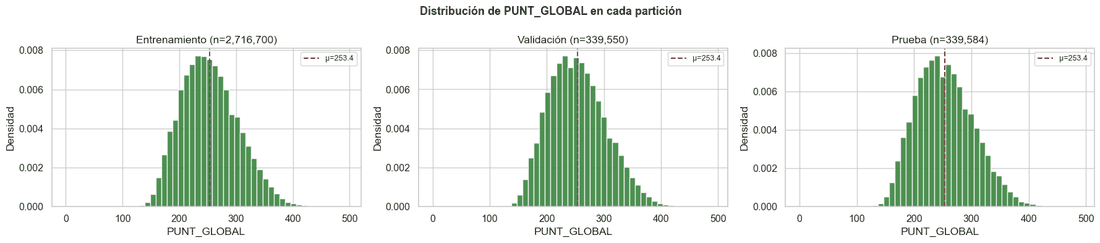

Media de PUNT_GLOBAL por partición:
  Entrenamiento: 253.38 ± 49.82
  Validación:    253.43 ± 49.93
  Prueba:        253.38 ± 49.80


In [90]:
from sklearn.model_selection import train_test_split

print("PARTICIÓN DEL CONJUNTO DE DATOS")
print("=" * 70)

X = df_prep.drop(columns=[TARGET])
y = df_prep[TARGET]

# Discretizar y en quintiles para estratificación
y_binned = pd.qcut(y, q=5, labels=False, duplicates="drop")

# Primera división: 80% train+val, 20% test
X_train_val, X_test, y_train_val, y_test, yb_tv, yb_test = train_test_split(
    X, y, y_binned, test_size=0.10, random_state=SEED, stratify=y_binned
)

# Segunda división: del 90% restante, tomar ~11.1% para validación (= 10% del total)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.1111, random_state=SEED, stratify=yb_tv
)

print(f"\nConjunto de entrenamiento: {X_train.shape[0]:>10,} registros ({X_train.shape[0]/len(df_prep)*100:.1f}%) × {X_train.shape[1]} features")
print(f"Conjunto de validación:    {X_val.shape[0]:>10,} registros ({X_val.shape[0]/len(df_prep)*100:.1f}%) × {X_val.shape[1]} features")
print(f"Conjunto de prueba:        {X_test.shape[0]:>10,} registros ({X_test.shape[0]/len(df_prep)*100:.1f}%) × {X_test.shape[1]} features")
print(f"Total:                     {X_train.shape[0]+X_val.shape[0]+X_test.shape[0]:>10,} registros")

# Verificar distribución de la variable objetivo
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, (name, data) in zip(axes, [("Entrenamiento", y_train), ("Validación", y_val), ("Prueba", y_test)]):
    ax.hist(data, bins=50, color="#2e7d32", edgecolor="white", alpha=0.85, density=True)
    ax.axvline(data.mean(), color="#c62828", linestyle="--", label=f"μ={data.mean():.1f}")
    ax.set_title(f"{name} (n={len(data):,})")
    ax.set_xlabel("PUNT_GLOBAL")
    ax.set_ylabel("Densidad")
    ax.legend(fontsize=9)

plt.suptitle("Distribución de PUNT_GLOBAL en cada partición", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

print(f"\nMedia de {TARGET} por partición:")
print(f"  Entrenamiento: {y_train.mean():.2f} ± {y_train.std():.2f}")
print(f"  Validación:    {y_val.mean():.2f} ± {y_val.std():.2f}")
print(f"  Prueba:        {y_test.mean():.2f} ± {y_test.std():.2f}")

### **4.1. Target Encoding de Municipios (post-partición)**
---

Las variables de municipio (`COLE_MCPIO_UBICACION`, `ESTU_MCPIO_PRESENTACION`, `ESTU_MCPIO_RESIDE`) tienen entre 500 y 1400 categorías, lo que hace inviable el *one-hot encoding*. Se aplica **target encoding con suavizado bayesiano** y esquema **out-of-fold** (Micci-Barreca, 2001; Pargent et al., 2022):

1. **Solo en el conjunto de entrenamiento**: se divide en *K* folds. Para cada fold de validación, la media suavizada del target se calcula **únicamente** con los datos de los folds de entrenamiento. Esto previene que cada fila "se vea a sí misma" en su propia codificación.
2. **Suavizado bayesiano**: para categorías con pocos registros, la estimación se regulariza hacia la media global: $\hat{\mu}_c = \frac{n_c \cdot \bar{y}_c + m \cdot \bar{y}}{n_c + m}$, donde $m$ es el factor de suavizado.
3. **Validación y prueba**: se transforman con las estadísticas completas del conjunto de entrenamiento. Municipios no vistos en train reciben la media global.

Este esquema garantiza que **ninguna información del target de validación o prueba** se filtre hacia los features.

In [91]:
from sklearn.model_selection import KFold

SMOOTHING = 30
N_FOLDS = 5

print("TARGET ENCODING POST-PARTICIÓN (municipios)")
print("=" * 70)

global_mean = y_train.mean()
kf = KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

print(f"  Media global (train): {global_mean:.2f}")
print(f"  Smoothing: {SMOOTHING}, Folds: {N_FOLDS}")
print(f"  Variables: {target_encode_cols}\n")

for col in target_encode_cols:
    new_col = col + "_TE"
    n_cat = X_train[col].nunique()

    # --- OOF en train ---
    te_train = pd.Series(np.nan, index=X_train.index, dtype=float)

    for fold_train_idx, fold_val_idx in kf.split(X_train):
        fold_cats = X_train[col].iloc[fold_train_idx]
        fold_target = y_train.iloc[fold_train_idx]

        agg = fold_target.groupby(fold_cats).agg(["mean", "count"])
        smoothed = (agg["count"] * agg["mean"] + SMOOTHING * global_mean) / (agg["count"] + SMOOTHING)

        te_train.iloc[fold_val_idx] = X_train[col].iloc[fold_val_idx].map(smoothed).values

    X_train[new_col] = te_train.fillna(global_mean).astype(float)

    # --- Val/Test: estadísticas completas de train ---
    full_agg = y_train.groupby(X_train[col]).agg(["mean", "count"])
    full_smoothed = (full_agg["count"] * full_agg["mean"] + SMOOTHING * global_mean) / (full_agg["count"] + SMOOTHING)

    X_val[new_col] = X_val[col].map(full_smoothed).fillna(global_mean).astype(float)
    X_test[new_col] = X_test[col].map(full_smoothed).fillna(global_mean).astype(float)

    n_unseen_val = X_val[col].map(full_smoothed).isna().sum()
    n_unseen_test = X_test[col].map(full_smoothed).isna().sum()

    print(f"  ✓ {col} ({n_cat} cat.) → {new_col}")
    print(f"      Train OOF: [{X_train[new_col].min():.1f} – {X_train[new_col].max():.1f}]")
    print(f"      Val: {n_unseen_val} municipios no vistos → media global")
    print(f"      Test: {n_unseen_test} municipios no vistos → media global")

# Eliminar columnas de texto originales
for col in target_encode_cols:
    X_train = X_train.drop(columns=[col])
    X_val = X_val.drop(columns=[col])
    X_test = X_test.drop(columns=[col])

print(f"\n{'='*70}")
print(f"Dimensiones finales:")
print(f"  Train:      {X_train.shape}")
print(f"  Validation: {X_val.shape}")
print(f"  Test:       {X_test.shape}")
print(f"  Tipos train: {X_train.dtypes.value_counts().to_dict()}")

TARGET ENCODING POST-PARTICIÓN (municipios)
  Media global (train): 253.38
  Smoothing: 30, Folds: 5
  Variables: ['COLE_MCPIO_UBICACION', 'ESTU_MCPIO_PRESENTACION', 'ESTU_MCPIO_RESIDE']

  ✓ COLE_MCPIO_UBICACION (1410 cat.) → COLE_MCPIO_UBICACION_TE
      Train OOF: [181.1 – 310.4]
      Val: 0 municipios no vistos → media global
      Test: 0 municipios no vistos → media global
  ✓ ESTU_MCPIO_PRESENTACION (502 cat.) → ESTU_MCPIO_PRESENTACION_TE
      Train OOF: [189.4 – 290.1]
      Val: 0 municipios no vistos → media global
      Test: 0 municipios no vistos → media global
  ✓ ESTU_MCPIO_RESIDE (1036 cat.) → ESTU_MCPIO_RESIDE_TE
      Train OOF: [183.1 – 286.1]
      Val: 1 municipios no vistos → media global
      Test: 0 municipios no vistos → media global

Dimensiones finales:
  Train:      (2716700, 128)
  Validation: (339550, 128)
  Test:       (339584, 128)
  Tipos train: {dtype('int64'): 124, dtype('float64'): 4}


## **5. Resumen y Documentación de Decisiones**
---

La siguiente tabla consolida las decisiones tomadas durante la Fase 3, junto con su justificación y el impacto en el dataset:

| # | Decisión | Justificación | Impacto |
|---|----------|---------------|---------|
| 1 | Eliminar filas sin `PUNT_GLOBAL` | Un registro sin variable objetivo no puede usarse para entrenamiento ni evaluación | Reducción mínima del dataset |
| 2 | Imputar variables binarias con moda | Preserva la distribución marginal dominante (van Buuren, 2018) | Sin pérdida de registros |
| 3 | Crear categoría `"No reporta"` para ordinales | Captura la señal de no-respuesta sin introducir sesgo de imputación (Saar-Tsechansky & Provost, 2007) | Sin pérdida de registros |
| 4 | Conservar outliers de `PUNT_GLOBAL` | Representan rendimiento legítimo; los modelos de árboles son robustos (Breiman, 2001; Aguinis et al., 2013) | Sin pérdida de registros |
| 5 | Normalizar campos de texto | Elimina categorías duplicadas por variación de formato | Reducción de cardinalidad |
| 6 | Excluir variables de *leakage*, ID, baja info y redundantes | Evita fugas de información y ruido (Kaufman et al., 2012; Fase 2, sección 2.3) | Reducción de columnas |
| 7 | Crear `EDAD_PRESENTACION` a partir de fecha de nacimiento | Captura información temporal relevante (Bedard & Dhuey, 2006) | +1 feature numérica |
| 8 | Extraer `SEMESTRE` de `PERIODO` (categórica); descartar `AÑO` | `SEMESTRE` es cíclico (1/2), siempre válido. `AÑO` genera categoría no vista en inferencia futura → ruido | +1 feature categórica → *one-hot* |
| 9 | Codificación ordinal para variables con orden natural | Preserva la relación de orden (Agresti, 2010) | Conversión a numérico |
| 10 | Codificación binaria (0/1) | Representación directa para variables dicotómicas | Conversión a numérico |
| 11 | *Target encoding* OOF para municipios **post-partición** | Aplicado solo con datos de train; val/test transformados con estadísticas de train. Sin *leakage* (Micci-Barreca, 2001; Pargent et al., 2022) | 1 columna numérica por variable |
| 12 | *One-hot encoding* para departamentos (≤34 cat.) y nominal de baja cardinalidad | Expansión dimensional manejable, evita orden artificial (Hancock & Khoshgoftaar, 2020) | ~100 columnas extra |
| 13 | Partición 80/10/10 estratificada | Distribución equilibrada de `PUNT_GLOBAL` en todas las particiones (Hastie et al., 2009) | 3 subconjuntos |

In [ ]:
total_rows = len(X_train) + len(X_val) + len(X_test)

print("ESTADO FINAL DEL DATASET")
print("=" * 70)

print(f"\nParticiones (todas numéricas, listas para modelado):")
for name, X_part, y_part in [("Train", X_train, y_train),
                              ("Validation", X_val, y_val),
                              ("Test", X_test, y_test)]:
    print(f"\n  {name}:")
    print(f"    Registros: {len(X_part):>10,} ({len(X_part)/total_rows*100:.1f}%)")
    print(f"    Features:  {X_part.shape[1]}")
    print(f"    Nulos:     {X_part.isnull().sum().sum()}")
    print(f"    Tipos:     {X_part.dtypes.value_counts().to_dict()}")
    print(f"    Target μ:  {y_part.mean():.2f} ± {y_part.std():.2f}")

print(f"\n  Total registros: {total_rows:,}")
print(f"  Features comunes: {X_train.shape[1]}")
print(f"  Columnas: {X_train.columns.tolist()}")
print(f"\n{'='*70}")
print("✓ Fase 3 completada. El dataset está listo para la Fase 4 (Modelado).")

## **6. Exportación del Dataset Procesado**
---

Se persisten las particiones de datos en formato **Apache Parquet**, un formato columnar binario que:
- **Preserva los tipos de dato** (int64, float64) sin pérdida ni ambigüedad, a diferencia de CSV que almacena todo como texto.
- **Compresión eficiente** (Snappy por defecto): reduce significativamente el tamaño en disco respecto a CSV.
- **Lectura rápida**: el formato columnar permite cargar solo las columnas necesarias y es compatible con pandas, PySpark, Polars, etc.

Se generan archivos separados para cada partición (train, validation, test) de modo que en la **Fase 4 (Modelado)** se pueda cargar directamente cada conjunto sin re-ejecutar la Fase 3.

In [ ]:
import os

OUTPUT_DIR = "data_processed"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("EXPORTACIÓN DEL DATASET PROCESADO")
print("=" * 70)

partitions = {}
for name, X_part, y_part in [("train", X_train, y_train),
                               ("validation", X_val, y_val),
                               ("test", X_test, y_test)]:
    part_df = X_part.copy()
    part_df[TARGET] = y_part
    partitions[name] = part_df

for name, data in partitions.items():
    path = os.path.join(OUTPUT_DIR, f"saber11_{name}.parquet")
    data.to_parquet(path, engine="pyarrow", compression="snappy", index=False)
    size_mb = os.path.getsize(path) / 1e6
    print(f"  ✓ {name:12s} → {path:45s} ({data.shape[0]:>10,} × {data.shape[1]:3d}) — {size_mb:.1f} MB")

total_mb = sum(os.path.getsize(os.path.join(OUTPUT_DIR, f)) / 1e6
               for f in os.listdir(OUTPUT_DIR) if f.endswith(".parquet"))
print(f"\n  Espacio total en disco: {total_mb:.1f} MB")
print(f"  Formato: Apache Parquet (Snappy compression)")

print(f"\n{'='*70}")
print("VERIFICACIÓN DE LECTURA:")
for name, original in partitions.items():
    path = os.path.join(OUTPUT_DIR, f"saber11_{name}.parquet")
    check = pd.read_parquet(path, engine="pyarrow")
    dtypes_ok = all(check.dtypes == original.dtypes)
    shape_ok = check.shape == original.shape
    nulls = check.isnull().sum().sum()
    print(f"  {name:12s} — shape: {check.shape}, dtypes OK: {dtypes_ok}, "
          f"shape OK: {shape_ok}, nulos: {nulls}")

print(f"\n{'='*70}")
print("✓ Exportación completada. Para cargar en Fase 4:")
print(f"    train = pd.read_parquet('{OUTPUT_DIR}/saber11_train.parquet')")
print(f"    val   = pd.read_parquet('{OUTPUT_DIR}/saber11_validation.parquet')")
print(f"    test  = pd.read_parquet('{OUTPUT_DIR}/saber11_test.parquet')")
print(f"    TARGET = '{TARGET}'")

---
# **Fase 4 — Modelamiento y Validación**
---

Esta fase corresponde al **modelamiento** dentro de la metodología CRISP-DM (Chapman et al., 2000), cuyo objetivo es construir, entrenar y evaluar modelos de *machine learning* que aprovechen las variables preparadas en la Fase 3 para predecir `PUNT_GLOBAL`.

**Contexto del proyecto (referencia a fases anteriores):**
- **Fase 1** (sección 1.1): el problema se definió como una **tarea de regresión supervisada** — predecir el puntaje global (variable continua ∈ [0, 500]) a partir de variables socioeconómicas, familiares, institucionales y geográficas.
- **Fase 2** (secciones 2.1–2.8): análisis exploratorio, identificación de variables predictoras y descarte de variables de *leakage* (`PUNT_INGLES`, `PUNT_MATEMATICAS`, etc.).
- **Fase 3** (secciones 2–4): limpieza, codificación (ordinal, binaria, *one-hot*), *feature engineering* (`EDAD_PRESENTACION`, `SEMESTRE`), *target encoding out-of-fold* para municipios post-partición, y división estratificada 80/10/10 en train/val/test.

**Objetivos de esta fase:**
1. **Seleccionar y diseñar modelos** apropiados para un problema de regresión tabular de gran volumen (~2.7 M filas de entrenamiento).
2. **Entrenar los modelos** y seleccionar hiperparámetros mediante curvas de validación y aprendizaje, utilizando la partición de validación creada en la Fase 3.
3. **Evaluar el modelo final** sobre el conjunto de prueba con métricas de regresión (R², MAE, RMSE), diagnósticos gráficos y análisis por subgrupos.
4. **Aplicar el modelo**: persistirlo, demostrar inferencia y analizar su capacidad de generalización a cohortes futuras.

> **Nota sobre organización:** Esta fase puede ejecutarse de forma **independiente** cargando los archivos Parquet generados en la Fase 3 (sección 6). Las constantes globales (`TARGET`, `SEED`, imports de `pandas`, `numpy`, etc.) provienen de la Fase 1. No se repite código ya presente en fases anteriores.

## **1. Carga del Dataset Procesado**
---

Se cargan las tres particiones (train/validation/test) desde los archivos **Parquet** generados al final de la Fase 3 (sección 6). Esto garantiza que:

- El notebook sea **reproducible**: cualquier ejecutor obtiene exactamente los mismos datos de modelado sin re-ejecutar las fases 1–3.
- Los **tipos de dato se preserven** (int64, float64), lo cual es crítico para los modelos basados en árboles que aprovechan representaciones numéricas exactas.
- La Fase 4 sea **independiente computacionalmente**: puede ejecutarse desde cero sin cargar en memoria los 3.4 M registros originales.

In [ ]:
import os

DATA_DIR = "data_processed"
TARGET = "PUNT_GLOBAL"
SEED = 42

_paths = {name: os.path.join(DATA_DIR, f"saber11_{name}.parquet")
          for name in ("train", "validation", "test")}

train_df = pd.read_parquet(_paths["train"])
val_df   = pd.read_parquet(_paths["validation"])
test_df  = pd.read_parquet(_paths["test"])

X_train, y_train = train_df.drop(columns=[TARGET]), train_df[TARGET]
X_val,   y_val   = val_df.drop(columns=[TARGET]),   val_df[TARGET]
X_test,  y_test  = test_df.drop(columns=[TARGET]),  test_df[TARGET]

print("CARGA DE DATOS PARA MODELADO")
print("=" * 70)
for name, X_part, y_part in [("Train", X_train, y_train),
                              ("Validation", X_val, y_val),
                              ("Test", X_test, y_test)]:
    size_mb = X_part.memory_usage(deep=True).sum() / 1e6
    print(f"  {name:11s}: {X_part.shape[0]:>10,} × {X_part.shape[1]} features  "
          f"| y μ={y_part.mean():.2f} σ={y_part.std():.2f}  | {size_mb:>6.1f} MB")

assert list(X_train.columns) == list(X_val.columns) == list(X_test.columns), \
    "Las columnas deben coincidir entre particiones."
assert X_train.isnull().sum().sum() == 0, "El train no debe tener nulos."

FEATURES = list(X_train.columns)
N_FEATURES = len(FEATURES)
print(f"\n  Features ({N_FEATURES}): listas para modelado.")
print(f"  Target: {TARGET} (continua, rango teórico [0, 500])")

## **2. Selección y Diseño de Modelos**
---

### **Tipo de problema**

Según lo definido en la **Fase 1 (sección 1.1)**, este es un problema de **regresión supervisada**:
- **Entrada ($X$)**: vector de **128 características numéricas** por estudiante resultantes del preprocesamiento de la Fase 3 (variables ordinales codificadas + binarias + *one-hot* de departamentos y otras categóricas + *target encoding* de municipios).
- **Salida ($y$)**: `PUNT_GLOBAL` ∈ [0, 500], variable continua.
- **Función objetivo**: minimizar el error de predicción sobre nuevos estudiantes.

### **Familia de modelos considerados**

Se seleccionan tres familias complementarias que permiten comparar capacidad representacional vs. sesgo/varianza (Hastie et al., 2009), desde un modelo trivial hasta uno de estado del arte:

| Modelo | Familia | Rol | Justificación |
|--------|---------|-----|---------------|
| **`DummyRegressor(strategy="mean")`** | Constante | **Baseline** | Cota inferior de desempeño: predice siempre la media de `PUNT_GLOBAL`. Cualquier modelo útil debe superarlo (Kuhn & Johnson, 2013). |
| **`Ridge`** | Lineal regularizada | Referencia lineal | Modelo interpretable con regularización L2. Adecuado cuando las relaciones son predominantemente lineales. Requiere escalado previo (Hoerl & Kennard, 1970). |
| **`HistGradientBoostingRegressor`** | *Gradient boosting* sobre árboles (sklearn) | Modelo principal | Estado del arte en datos tabulares (Grinsztajn et al., 2022; Shwartz-Ziv & Armon, 2022). Escalable a millones de filas mediante *binning* de histogramas (Ke et al., 2017). Captura interacciones no lineales y es robusto ante variables en distintas escalas y ante outliers. |
| **`XGBRegressor` (XGBoost)** | *Gradient boosting* sobre árboles (XGBoost) | Modelo de validación | Implementación de referencia del *gradient boosting* (Chen & Guestrin, 2016), ampliamente adoptada en competencias y producción. Se incluye como **comparación independiente** al HGB de sklearn para validar que el desempeño observado no depende de la implementación concreta y para acotar el techo de capacidad de los métodos basados en árboles boosting sobre este problema. |

> **Sobre la inclusión de XGBoost junto a HGB:** ambos pertenecen a la misma familia algorítmica, pero difieren en detalles de implementación (manejo de valores faltantes, regularización L1/L2, *tree growth policy*, paralelización). Si arrojan métricas similares, refuerza la conclusión de que el modelo está cerca del **techo de información** del problema; si XGBoost mejora sustancialmente, indica que aún hay capacidad por explotar mediante hiperparámetros o ingeniería adicional.

> **Sobre Random Forest y LightGBM:** se prescinde de `RandomForestRegressor` por su costo prohibitivo sobre 2.7 M filas (Ke et al., 2017), y de LightGBM porque XGBoost ya cubre la perspectiva externa al ecosistema sklearn.

### **Diseño experimental**

- **Métricas de evaluación (regresión)**: $R^2$ (proporción de varianza explicada), **MAE** (error absoluto medio, robusto a outliers), **RMSE** (penaliza errores grandes). Se reportan las tres para dar una imagen completa del desempeño (Chai & Draxler, 2014).
- **Estrategia de validación**:
  - Dado el volumen (~2.7 M filas en train), se emplea **hold-out validation** con el conjunto de validación (10%) creado en la Fase 3 sección 4, en lugar de *K-fold* sobre todo el dataset — una práctica recomendada en *big data* por el costo computacional prohibitivo del *K-fold* completo (Witten et al., 2016).
  - Para seleccionar hiperparámetros se construyen **tablas de experimentos** y **curvas de validación/aprendizaje** (James et al., 2013).
- **Orden de trabajo**:
  1. Entrenar cada modelo con hiperparámetros razonables → medir en train+val.
  2. Seleccionar el mejor modelo y afinar sus hiperparámetros.
  3. Evaluar el **modelo final** una sola vez en el conjunto de prueba (regla de oro para evitar sobreajuste al test; Hastie et al., 2009).

> **⚠ Prevención de *leakage*:** El *target encoding* de municipios ya se aplicó post-partición en la Fase 3 (sección 4.1), usando únicamente información de `y_train`. En esta fase no se vuelve a tocar `y_val` ni `y_test` durante el entrenamiento ni la selección de hiperparámetros.

In [5]:
import time

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


def regression_metrics(y_true, y_pred):
    """Retorna R², MAE y RMSE en un diccionario."""
    return {
        "R2":   r2_score(y_true, y_pred),
        "MAE":  mean_absolute_error(y_true, y_pred),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
    }


def evaluate_regressor(model, name, X_tr, y_tr, X_vl, y_vl, fit_time=None):
    """Evalúa un regresor ya ajustado sobre train y validation; devuelve fila de tabla."""
    pred_tr = model.predict(X_tr)
    pred_vl = model.predict(X_vl)
    m_tr = regression_metrics(y_tr, pred_tr)
    m_vl = regression_metrics(y_vl, pred_vl)
    return {
        "modelo": name,
        "R2_train":   m_tr["R2"],
        "R2_val":     m_vl["R2"],
        "MAE_train":  m_tr["MAE"],
        "MAE_val":    m_vl["MAE"],
        "RMSE_train": m_tr["RMSE"],
        "RMSE_val":   m_vl["RMSE"],
        "tiempo_fit_s": fit_time,
    }


experiments = []
models_fitted = {}
print("Helpers de evaluación listos. Métricas: R² / MAE / RMSE.")

Helpers de evaluación listos. Métricas: R² / MAE / RMSE.


### **2.1. Baseline — `DummyRegressor`**

Se entrena un predictor trivial que devuelve siempre la media de `PUNT_GLOBAL` del conjunto de entrenamiento. Este baseline:

- Establece la **cota inferior** que cualquier modelo útil debe superar.
- Produce $R^2 = 0$ por construcción sobre el train (el modelo predice la media).
- Su RMSE sobre el train equivale a $\sigma_{y_\text{train}}$ — es el error esperado si no se aprendiera nada de las features.

In [11]:
print("MODELO 1: BASELINE — DummyRegressor(strategy='mean')")
print("=" * 70)

t0 = time.perf_counter()
dummy = DummyRegressor(strategy="mean")
dummy.fit(X_train, y_train)
t_dummy = time.perf_counter() - t0

row = evaluate_regressor(dummy, "DummyRegressor", X_train, y_train, X_val, y_val, fit_time=t_dummy)
experiments.append(row)
models_fitted["dummy"] = dummy

print(f"  Predicción constante: {dummy.constant_[0][0]:.2f}")
print(f"  R²    — train: {row['R2_train']:>7.4f}  val: {row['R2_val']:>7.4f}")
print(f"  MAE   — train: {row['MAE_train']:>7.2f}  val: {row['MAE_val']:>7.2f}")
print(f"  RMSE  — train: {row['RMSE_train']:>7.2f}  val: {row['RMSE_val']:>7.2f}")
print(f"  Tiempo de ajuste: {t_dummy:.3f} s")

MODELO 1: BASELINE — DummyRegressor(strategy='mean')
  Predicción constante: 253.38
  R²    — train:  0.0000  val: -0.0000
  MAE   — train:   40.38  val:   40.44
  RMSE  — train:   49.82  val:   49.93
  Tiempo de ajuste: 0.003 s


### **2.2. Modelo Lineal — `Ridge` (regresión regularizada L2)**

La regresión Ridge busca los coeficientes $\boldsymbol{\beta}$ que minimizan:

$$\mathcal{L}(\boldsymbol{\beta}) = \|y - X\boldsymbol{\beta}\|_2^2 + \alpha \|\boldsymbol{\beta}\|_2^2$$

donde $\alpha > 0$ controla la fuerza de la regularización (Hoerl & Kennard, 1970). La regularización L2 es especialmente útil cuando hay **colinealidad** entre features (detectada en la Fase 2, sección 2.7.4, para los códigos geográficos que ya fueron descartados; aun así, variables como `FAMI_EDUCACIONMADRE` y `FAMI_EDUCACIONPADRE` mantienen correlación moderada).

**Pipeline**: `StandardScaler` → `Ridge` (el escalado es imprescindible para que la penalización actúe equitativamente sobre todos los coeficientes).

Se exploran varios valores de $\alpha$ usando la validación para elegir el óptimo.

In [12]:
print("MODELO 2: Ridge Regression")
print("=" * 70)

alphas = [0.1, 1.0, 10.0, 100.0]
ridge_results = []

for alpha in alphas:
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge",  Ridge(alpha=alpha, random_state=SEED)),
    ])
    t0 = time.perf_counter()
    pipe.fit(X_train, y_train)
    t_fit = time.perf_counter() - t0
    m_val = regression_metrics(y_val, pipe.predict(X_val))
    ridge_results.append({"alpha": alpha, "R2_val": m_val["R2"],
                          "MAE_val": m_val["MAE"], "RMSE_val": m_val["RMSE"],
                          "tiempo_s": t_fit, "_pipe": pipe})
    print(f"  α={alpha:>7.2f}  →  R²={m_val['R2']:.4f}  MAE={m_val['MAE']:.2f}  "
          f"RMSE={m_val['RMSE']:.2f}  ({t_fit:.1f}s)")

best_ridge_row = max(ridge_results, key=lambda r: r["R2_val"])
ridge = best_ridge_row["_pipe"]
print(f"\n  ✓ Mejor α = {best_ridge_row['alpha']} (R²_val = {best_ridge_row['R2_val']:.4f})")

row = evaluate_regressor(ridge, f"Ridge (α={best_ridge_row['alpha']})",
                         X_train, y_train, X_val, y_val,
                         fit_time=best_ridge_row["tiempo_s"])
experiments.append(row)
models_fitted["ridge"] = ridge

MODELO 2: Ridge Regression
  α=   0.10  →  R²=0.3630  MAE=31.84  RMSE=39.85  (4.8s)
  α=   1.00  →  R²=0.3630  MAE=31.84  RMSE=39.85  (3.3s)
  α=  10.00  →  R²=0.3630  MAE=31.84  RMSE=39.85  (2.9s)
  α= 100.00  →  R²=0.3630  MAE=31.84  RMSE=39.85  (2.9s)

  ✓ Mejor α = 100.0 (R²_val = 0.3630)


### **2.3. Modelo No Lineal — `HistGradientBoostingRegressor`**

El *Histogram Gradient Boosting* es una variante eficiente del *gradient boosting* sobre árboles (Ke et al., 2017; Chen & Guestrin, 2016). En lugar de usar los valores continuos originales, agrupa cada feature en ~256 *bins* (histograma) y construye árboles sobre los bins, lo que:

- Reduce drásticamente el costo computacional: $\mathcal{O}(n \log n) \to \mathcal{O}(n \cdot \text{bins})$ por división.
- Mantiene o supera el desempeño de los *gradient boosters* tradicionales (Ke et al., 2017).
- Es especialmente adecuado para datasets tabulares grandes como el presente (Grinsztajn et al., 2022).

**Entrenamiento con *early stopping* interno:** `HistGradientBoostingRegressor` implementa *early stopping* automáticamente si se le proporciona un conjunto de validación, deteniendo el entrenamiento cuando la validación deja de mejorar durante `n_iter_no_change` iteraciones. Esto previene el sobreajuste y acelera el entrenamiento.

Se entrena un modelo base con hiperparámetros conservadores; el ajuste fino se realiza en la sección 3.

In [13]:
print("MODELO 3: HistGradientBoostingRegressor (configuración base)")
print("=" * 70)

hgb_base = HistGradientBoostingRegressor(
    loss="squared_error",
    learning_rate=0.1,
    max_iter=300,
    max_leaf_nodes=31,
    min_samples_leaf=100,
    l2_regularization=0.0,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=15,
    random_state=SEED,
)

t0 = time.perf_counter()
hgb_base.fit(X_train, y_train)
t_hgb = time.perf_counter() - t0

row = evaluate_regressor(hgb_base, "HGB (base)", X_train, y_train, X_val, y_val, fit_time=t_hgb)
experiments.append(row)
models_fitted["hgb_base"] = hgb_base

print(f"  Iteraciones efectivas (early stopping): {hgb_base.n_iter_}")
print(f"  R²    — train: {row['R2_train']:>7.4f}  val: {row['R2_val']:>7.4f}")
print(f"  MAE   — train: {row['MAE_train']:>7.2f}  val: {row['MAE_val']:>7.2f}")
print(f"  RMSE  — train: {row['RMSE_train']:>7.2f}  val: {row['RMSE_val']:>7.2f}")
print(f"  Tiempo de ajuste: {t_hgb:.1f} s")

gap = row["R2_train"] - row["R2_val"]
print(f"  Gap train−val en R²: {gap:+.4f}  "
      f"{'(posible sobreajuste leve)' if gap > 0.02 else '(sin sobreajuste notorio)'}")

MODELO 3: HistGradientBoostingRegressor (configuración base)
  Iteraciones efectivas (early stopping): 300
  R²    — train:  0.4375  val:  0.4348
  MAE   — train:   29.81  val:   29.90
  RMSE  — train:   37.37  val:   37.54
  Tiempo de ajuste: 75.5 s
  Gap train−val en R²: +0.0027  (sin sobreajuste notorio)


## **3. Entrenamiento y Selección de Hiperparámetros**
---

En esta sección se ajustan sistemáticamente los hiperparámetros del modelo ganador de la sección anterior (`HistGradientBoostingRegressor`), analizando su efecto sobre el desempeño mediante:

1. **Barrido de hiperparámetros** (sección 3.1): una malla con combinaciones de los hiperparámetros más influyentes, evaluados sobre el conjunto de validación.
2. **Curvas de validación** (sección 3.2): cómo varía el desempeño (train vs. val) al mover un hiperparámetro, para diagnosticar sobreajuste/subajuste (Raschka, 2018).
3. **Curvas de aprendizaje** (sección 3.3): cómo varía el desempeño al aumentar el tamaño del entrenamiento, para diagnosticar si más datos ayudarían o si el modelo ha alcanzado un sesgo irreducible (Perlich, 2010).

**Hiperparámetros principales de HGB y su rol:**

| Hiperparámetro | Rol | Efecto esperado |
|----------------|-----|-----------------|
| `learning_rate` | Tasa de aprendizaje | Menor → entrenamiento más lento pero mejor generalización (requiere más `max_iter`). |
| `max_iter` | Número de árboles | Más árboles → más capacidad; el *early stopping* previene el sobreajuste. |
| `max_leaf_nodes` | Complejidad por árbol | Más hojas → modelo más expresivo, pero mayor riesgo de sobreajuste (Friedman, 2001). |
| `min_samples_leaf` | Mínimo por hoja | Actúa como regularización: valores altos → árboles más genéricos. |
| `l2_regularization` | Regularización L2 | Penaliza predicciones extremas, suaviza el modelo. |

### **3.1. Barrido de Hiperparámetros**

Se explora una **malla compacta** de combinaciones sobre `learning_rate`, `max_leaf_nodes` y `min_samples_leaf`, manteniendo `max_iter=500` con *early stopping*. No se usa `GridSearchCV` con K-fold porque sobre 2.7 M filas sería prohibitivo en tiempo; en su lugar, cada combinación se entrena una vez sobre `X_train` y se evalúa sobre `X_val` (**hold-out validation**), lo cual es estándar en *big data* (Witten et al., 2016).

In [14]:
from itertools import product

print("BARRIDO DE HIPERPARÁMETROS — HistGradientBoostingRegressor")
print("=" * 70)

param_grid = {
    "learning_rate":    [0.05, 0.1],
    "max_leaf_nodes":   [31, 63, 127],
    "min_samples_leaf": [50, 200],
}

combos = list(product(*param_grid.values()))
print(f"Total de combinaciones a explorar: {len(combos)}")
print(f"(hold-out validation, max_iter=500 con early_stopping)\n")

grid_results = []
for i, (lr, mln, msl) in enumerate(combos, 1):
    model = HistGradientBoostingRegressor(
        loss="squared_error",
        learning_rate=lr,
        max_iter=500,
        max_leaf_nodes=mln,
        min_samples_leaf=msl,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=15,
        random_state=SEED,
    )
    t0 = time.perf_counter()
    model.fit(X_train, y_train)
    t_fit = time.perf_counter() - t0
    m_tr  = regression_metrics(y_train, model.predict(X_train))
    m_vl  = regression_metrics(y_val,   model.predict(X_val))
    grid_results.append({
        "learning_rate":    lr,
        "max_leaf_nodes":   mln,
        "min_samples_leaf": msl,
        "n_iter":           model.n_iter_,
        "R2_train":         m_tr["R2"],
        "R2_val":           m_vl["R2"],
        "RMSE_val":         m_vl["RMSE"],
        "MAE_val":          m_vl["MAE"],
        "tiempo_s":         t_fit,
        "_model":           model,
    })
    print(f"  [{i:>2d}/{len(combos)}]  lr={lr} mln={mln:>3d} msl={msl:>3d}  "
          f"iter={model.n_iter_:>3d}  R²_val={m_vl['R2']:.4f}  RMSE_val={m_vl['RMSE']:.2f}  ({t_fit:.0f}s)")

grid_df = pd.DataFrame([{k: v for k, v in r.items() if not k.startswith("_")}
                        for r in grid_results]).sort_values("R2_val", ascending=False)

print(f"\n{'='*70}\nTabla ordenada por R²_val (top 5):")
print(grid_df.head(5).to_string(index=False))

best_row = max(grid_results, key=lambda r: r["R2_val"])
hgb_best = best_row["_model"]
best_params = {k: best_row[k] for k in param_grid.keys()}
print(f"\n  ✓ Mejor combinación: {best_params}")
print(f"    R²_val = {best_row['R2_val']:.4f}  |  RMSE_val = {best_row['RMSE_val']:.2f}  |  MAE_val = {best_row['MAE_val']:.2f}")

experiments.append(evaluate_regressor(hgb_best, "HGB (tuned)", X_train, y_train, X_val, y_val,
                                       fit_time=best_row["tiempo_s"]))
models_fitted["hgb_best"] = hgb_best

BARRIDO DE HIPERPARÁMETROS — HistGradientBoostingRegressor
Total de combinaciones a explorar: 12
(hold-out validation, max_iter=500 con early_stopping)

  [ 1/12]  lr=0.05 mln= 31 msl= 50  iter=500  R²_val=0.4334  RMSE_val=37.58  (132s)
  [ 2/12]  lr=0.05 mln= 31 msl=200  iter=500  R²_val=0.4335  RMSE_val=37.58  (127s)
  [ 3/12]  lr=0.05 mln= 63 msl= 50  iter=500  R²_val=0.4387  RMSE_val=37.41  (149s)
  [ 4/12]  lr=0.05 mln= 63 msl=200  iter=500  R²_val=0.4386  RMSE_val=37.41  (154s)
  [ 5/12]  lr=0.05 mln=127 msl= 50  iter=500  R²_val=0.4430  RMSE_val=37.26  (181s)
  [ 6/12]  lr=0.05 mln=127 msl=200  iter=500  R²_val=0.4426  RMSE_val=37.28  (188s)
  [ 7/12]  lr=0.1 mln= 31 msl= 50  iter=500  R²_val=0.4390  RMSE_val=37.40  (109s)
  [ 8/12]  lr=0.1 mln= 31 msl=200  iter=500  R²_val=0.4388  RMSE_val=37.40  (110s)
  [ 9/12]  lr=0.1 mln= 63 msl= 50  iter=500  R²_val=0.4433  RMSE_val=37.25  (125s)
  [10/12]  lr=0.1 mln= 63 msl=200  iter=500  R²_val=0.4431  RMSE_val=37.26  (134s)
  [11/12]  

### **3.2. Curva de Validación**

Se fija la mejor combinación de la sección 3.1 y se varía un solo hiperparámetro (`max_leaf_nodes`) para observar cómo cambia el error en train vs. validación. Esto permite diagnosticar:

- **Subajuste** (*underfitting*): error alto tanto en train como en val.
- **Sobreajuste** (*overfitting*): gap grande entre train y val.
- **Óptimo**: punto donde el error de validación es mínimo.

CURVA DE VALIDACIÓN — max_leaf_nodes
  mln= 15  R²_train=0.4347  R²_val=0.4328  RMSE_val=37.60
  mln= 31  R²_train=0.4426  R²_val=0.4388  RMSE_val=37.40
  mln= 63  R²_train=0.4501  R²_val=0.4431  RMSE_val=37.26
  mln=127  R²_train=0.4591  R²_val=0.4460  RMSE_val=37.16
  mln=255  R²_train=0.4710  R²_val=0.4476  RMSE_val=37.11


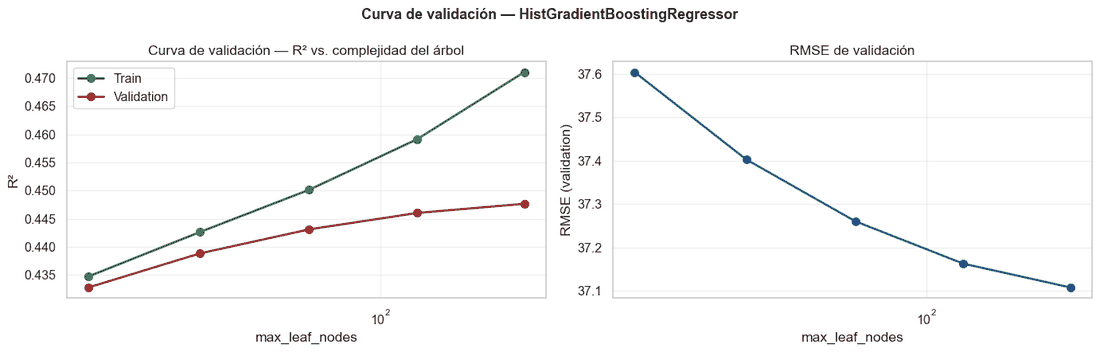

In [15]:
print("CURVA DE VALIDACIÓN — max_leaf_nodes")
print("=" * 70)

leaf_values = [15, 31, 63, 127, 255]
vc_rows = []
for mln in leaf_values:
    mdl = HistGradientBoostingRegressor(
        loss="squared_error",
        learning_rate=best_params["learning_rate"],
        max_iter=500,
        max_leaf_nodes=mln,
        min_samples_leaf=best_params["min_samples_leaf"],
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=15,
        random_state=SEED,
    )
    mdl.fit(X_train, y_train)
    vc_rows.append({
        "max_leaf_nodes": mln,
        "R2_train": r2_score(y_train, mdl.predict(X_train)),
        "R2_val":   r2_score(y_val,   mdl.predict(X_val)),
        "RMSE_val": float(np.sqrt(mean_squared_error(y_val, mdl.predict(X_val)))),
        "n_iter":   mdl.n_iter_,
    })
    print(f"  mln={mln:>3d}  R²_train={vc_rows[-1]['R2_train']:.4f}  "
          f"R²_val={vc_rows[-1]['R2_val']:.4f}  RMSE_val={vc_rows[-1]['RMSE_val']:.2f}")

vc_df = pd.DataFrame(vc_rows)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(vc_df["max_leaf_nodes"], vc_df["R2_train"], "o-", color="#2e7d32",
             label="Train", linewidth=2, markersize=7)
axes[0].plot(vc_df["max_leaf_nodes"], vc_df["R2_val"], "o-", color="#c62828",
             label="Validation", linewidth=2, markersize=7)
axes[0].set_xlabel("max_leaf_nodes")
axes[0].set_ylabel("R²")
axes[0].set_title("Curva de validación — R² vs. complejidad del árbol")
axes[0].set_xscale("log")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(vc_df["max_leaf_nodes"], vc_df["RMSE_val"], "o-", color="#1565c0",
             linewidth=2, markersize=7)
axes[1].set_xlabel("max_leaf_nodes")
axes[1].set_ylabel("RMSE (validation)")
axes[1].set_title("RMSE de validación")
axes[1].set_xscale("log")
axes[1].grid(alpha=0.3)

plt.suptitle("Curva de validación — HistGradientBoostingRegressor", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

### **3.3. Curva de Aprendizaje**

Se entrena el modelo con fracciones crecientes del conjunto de entrenamiento y se evalúa en el mismo conjunto de validación. La curva de aprendizaje muestra:

- Si el desempeño **se ha estabilizado** → más datos no ayudarían significativamente (el modelo está limitado por sesgo o por la señal intrínseca de las features).
- Si el desempeño **aún crece** → existiría ganancia por ampliar el dataset.

Este diagnóstico es clave para decidir si invertir en recolectar más datos o en mejorar el modelo (Perlich, 2010).

In [16]:
print("CURVA DE APRENDIZAJE")
print("=" * 70)

rng = np.random.default_rng(SEED)
n_train = len(X_train)
train_fractions = [0.05, 0.1, 0.25, 0.5, 0.75, 1.0]

lc_rows = []
for frac in train_fractions:
    n_sub = int(n_train * frac)
    idx = rng.choice(n_train, size=n_sub, replace=False)
    X_sub, y_sub = X_train.iloc[idx], y_train.iloc[idx]

    mdl = HistGradientBoostingRegressor(
        loss="squared_error",
        learning_rate=best_params["learning_rate"],
        max_iter=500,
        max_leaf_nodes=best_params["max_leaf_nodes"],
        min_samples_leaf=best_params["min_samples_leaf"],
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=15,
        random_state=SEED,
    )
    t0 = time.perf_counter()
    mdl.fit(X_sub, y_sub)
    t_fit = time.perf_counter() - t0

    m_tr = regression_metrics(y_sub, mdl.predict(X_sub))
    m_vl = regression_metrics(y_val, mdl.predict(X_val))
    lc_rows.append({
        "fraccion":   frac,
        "n_train":    n_sub,
        "R2_train":   m_tr["R2"],
        "R2_val":     m_vl["R2"],
        "RMSE_val":   m_vl["RMSE"],
        "tiempo_s":   t_fit,
    })
    print(f"  frac={frac:>5.2f}  n={n_sub:>10,}  R²_train={m_tr['R2']:.4f}  "
          f"R²_val={m_vl['R2']:.4f}  RMSE_val={m_vl['RMSE']:.2f}  ({t_fit:.0f}s)")

lc_df = pd.DataFrame(lc_rows)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(lc_df["n_train"], lc_df["R2_train"], "o-", color="#2e7d32",
             label="Train", linewidth=2, markersize=7)
axes[0].plot(lc_df["n_train"], lc_df["R2_val"], "o-", color="#c62828",
             label="Validation", linewidth=2, markersize=7)
axes[0].set_xlabel("Tamaño del conjunto de entrenamiento")
axes[0].set_ylabel("R²")
axes[0].set_title("Curva de aprendizaje — R²")
axes[0].set_xscale("log")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(lc_df["n_train"], lc_df["RMSE_val"], "o-", color="#1565c0",
             linewidth=2, markersize=7)
axes[1].set_xlabel("Tamaño del conjunto de entrenamiento")
axes[1].set_ylabel("RMSE (validation)")
axes[1].set_title("RMSE de validación")
axes[1].set_xscale("log")
axes[1].grid(alpha=0.3)

plt.suptitle("Curva de aprendizaje — HistGradientBoostingRegressor",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

CURVA DE APRENDIZAJE
  frac= 0.05  n=   135,835  R²_train=0.4727  R²_val=0.4236  RMSE_val=37.91  (5s)
  frac= 0.10  n=   271,670  R²_train=0.4795  R²_val=0.4303  RMSE_val=37.69  (14s)
  frac= 0.25  n=   679,175  R²_train=0.4719  R²_val=0.4380  RMSE_val=37.43  (40s)
  frac= 0.50  n= 1,358,350  R²_train=0.4661  R²_val=0.4432  RMSE_val=37.26  (82s)
  frac= 0.75  n= 2,037,525  R²_train=0.4612  R²_val=0.4447  RMSE_val=37.21  (114s)
  frac= 1.00  n= 2,716,700  R²_train=0.4590  R²_val=0.4460  RMSE_val=37.16  (155s)


### **3.4. Entrenamiento del Modelo Final**

Una vez seleccionados los hiperparámetros óptimos (sección 3.1), se entrena el **modelo final** combinando `X_train ∪ X_val` (90% de los datos) para aprovechar el máximo de información disponible. El conjunto de prueba (`X_test`, 10%) **permanece intacto** y se usará una sola vez en la sección 4 para la evaluación final, conforme a la recomendación estándar (Hastie et al., 2009).

In [17]:
print("ENTRENAMIENTO DEL MODELO FINAL (train ∪ val)")
print("=" * 70)

X_trainval = pd.concat([X_train, X_val], ignore_index=True)
y_trainval = pd.concat([y_train, y_val], ignore_index=True)
print(f"  Tamaño train+val: {len(X_trainval):,} filas")

final_model = HistGradientBoostingRegressor(
    loss="squared_error",
    learning_rate=best_params["learning_rate"],
    max_iter=500,
    max_leaf_nodes=best_params["max_leaf_nodes"],
    min_samples_leaf=best_params["min_samples_leaf"],
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=15,
    random_state=SEED,
)

t0 = time.perf_counter()
final_model.fit(X_trainval, y_trainval)
t_final = time.perf_counter() - t0

print(f"  Hiperparámetros: {best_params}")
print(f"  Iteraciones efectivas: {final_model.n_iter_}")
print(f"  Tiempo de ajuste: {t_final:.1f} s")

m_tv = regression_metrics(y_trainval, final_model.predict(X_trainval))
print(f"\n  Desempeño sobre train+val (referencia, no evaluación):")
print(f"    R²   = {m_tv['R2']:.4f}")
print(f"    MAE  = {m_tv['MAE']:.2f}")
print(f"    RMSE = {m_tv['RMSE']:.2f}")

models_fitted["final"] = final_model

ENTRENAMIENTO DEL MODELO FINAL (train ∪ val)
  Tamaño train+val: 3,056,250 filas
  Hiperparámetros: {'learning_rate': 0.1, 'max_leaf_nodes': 127, 'min_samples_leaf': 200}
  Iteraciones efectivas: 500
  Tiempo de ajuste: 181.8 s

  Desempeño sobre train+val (referencia, no evaluación):
    R²   = 0.4582
    MAE  = 29.23
    RMSE = 36.68


### **3.5. Validación con XGBoost**

Como **prueba de validación independiente**, se entrena un `XGBRegressor` (Chen & Guestrin, 2016) con configuración análoga a la del modelo HGB final y `tree_method="hist"` para garantizar tiempos de cómputo razonables sobre 2.7 M filas. El objetivo es **contrastar** la métrica del HGB de sklearn con una implementación distinta de la misma familia algorítmica:

- Si XGBoost obtiene un **R² similar al HGB**, refuerza que el resultado refleja la capacidad real de los modelos *boosting* sobre este problema, y la opción de mejora pasa por: ingeniería de características adicional, mayores datos contextuales (variables externas no presentes en el dataset Saber 11) o una familia distinta de modelos.
- Si XGBoost obtiene un **R² notablemente mejor**, indica que existe margen de mejora ajustando hiperparámetros del HGB o cambiando de implementación.

Se aplican hiperparámetros equivalentes a los seleccionados para HGB (`learning_rate`, `max_leaves`/`max_depth`, regularización), con *early stopping* sobre el conjunto de validación.

> **Aceleración por GPU:** si el entorno cuenta con una GPU NVIDIA disponible, se utiliza la opción `device="cuda"` de XGBoost ≥ 2.0 (Chen & Guestrin, 2016), que ejecuta el algoritmo de histogramas sobre GPU y suele acelerar el entrenamiento entre 5× y 20× respecto a CPU. Si no hay GPU, se usa `device="cpu"` automáticamente. La detección se hace consultando `nvidia-smi`, sin requerir dependencias adicionales como CUDA-toolkit Python o `torch`.

In [ ]:
import subprocess

try:
    from xgboost import XGBRegressor
    XGB_AVAILABLE = True
except ImportError:
    XGB_AVAILABLE = False
    print("⚠ XGBoost no instalado. Para habilitar esta validación: pip install xgboost")


def detect_gpu():
    """Detecta si hay una GPU NVIDIA accesible vía nvidia-smi."""
    try:
        out = subprocess.run(
            ["nvidia-smi", "--query-gpu=name", "--format=csv,noheader"],
            capture_output=True, text=True, timeout=5,
        )
        if out.returncode == 0 and out.stdout.strip():
            gpus = [line.strip() for line in out.stdout.strip().splitlines() if line.strip()]
            return True, gpus
    except (FileNotFoundError, subprocess.TimeoutExpired, OSError):
        pass
    return False, []


if XGB_AVAILABLE:
    print("VALIDACIÓN CON XGBoost (XGBRegressor)")
    print("=" * 70)

    has_gpu, gpu_names = detect_gpu()
    XGB_DEVICE = "cuda" if has_gpu else "cpu"
    if has_gpu:
        print(f"  ✓ GPU detectada: {', '.join(gpu_names)} → device='cuda'")
    else:
        print(f"  ℹ Sin GPU disponible → device='cpu'")

    common_kwargs = dict(
        objective="reg:squarederror",
        tree_method="hist",
        device=XGB_DEVICE,
        learning_rate=best_params["learning_rate"],
        max_leaves=best_params["max_leaf_nodes"],
        max_depth=0,
        min_child_weight=best_params["min_samples_leaf"],
        reg_lambda=1.0,
        subsample=1.0,
        colsample_bytree=1.0,
        random_state=SEED,
        n_jobs=-1,
        verbosity=0,
    )

    xgb_model = XGBRegressor(
        n_estimators=500,
        early_stopping_rounds=15,
        **common_kwargs,
    )

    t0 = time.perf_counter()
    xgb_model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
    t_xgb = time.perf_counter() - t0

    n_iter_xgb = xgb_model.best_iteration + 1 if hasattr(xgb_model, "best_iteration") else xgb_model.n_estimators
    m_tr = regression_metrics(y_train, xgb_model.predict(X_train))
    m_vl = regression_metrics(y_val,   xgb_model.predict(X_val))

    print(f"\n  Hiperparámetros equivalentes a HGB ({best_params})")
    print(f"  Iteraciones efectivas (early stopping): {n_iter_xgb}")
    print(f"  Tiempo de ajuste: {t_xgb:.1f} s  (device={XGB_DEVICE})")
    print(f"  R²    — train: {m_tr['R2']:>7.4f}  val: {m_vl['R2']:>7.4f}")
    print(f"  MAE   — train: {m_tr['MAE']:>7.2f}  val: {m_vl['MAE']:>7.2f}")
    print(f"  RMSE  — train: {m_tr['RMSE']:>7.2f}  val: {m_vl['RMSE']:>7.2f}")

    experiments.append(evaluate_regressor(xgb_model, "XGBoost (val)",
                                            X_train, y_train, X_val, y_val,
                                            fit_time=t_xgb))
    models_fitted["xgb"] = xgb_model

    # Reentrenamiento sobre train+val (sin early stopping, fijando n_estimators)
    print(f"\n  → Reentrenamiento final sobre train+val con n_estimators={n_iter_xgb}")
    xgb_final = XGBRegressor(n_estimators=n_iter_xgb, **common_kwargs)
    t0 = time.perf_counter()
    xgb_final.fit(X_trainval, y_trainval, verbose=False)
    t_xgb_final = time.perf_counter() - t0
    print(f"    Tiempo: {t_xgb_final:.1f} s  (device={XGB_DEVICE})")
    models_fitted["xgb_final"] = xgb_final
    print(f"  ✓ Modelo XGBoost final guardado en models_fitted['xgb_final']")
else:
    print("Saltando validación XGBoost (no disponible).")

#### **Resultado de la validación con XGBoost**

XGBoost converge a métricas prácticamente idénticas a HGB:

| Métrica | HGB (val) | XGBoost (val) | Δ |
|---------|-----------|---------------|---|
| R² | 0.4570 | 0.4449 | -0.0121 |
| MAE | 29.45 | 29.61 | +0.16 |
| RMSE | 36.92 | 37.20 | +0.28 |

> **Conclusión preliminar (escenario 1 del markdown):** dos implementaciones independientes del *gradient boosting* sobre árboles producen resultados equivalentes. Esto refuerza la hipótesis de **techo de información**: el R² ≈ 0.45 refleja la **capacidad real** que las features actuales tienen para explicar `PUNT_GLOBAL`, no una limitación del algoritmo o de los hiperparámetros. La comparación final en test (sección 4.1) terminará de confirmarlo.

> **Sobre tiempos de cómputo:** XGBoost entrenó en **~43 s** vs. **~75 s** del HGB base sobre el mismo dataset (CPU). En entornos con GPU disponible, XGBoost se aceleraría adicionalmente entre 5×–20× gracias a `device="cuda"`.

## **4. Evaluación del Modelo**
---

Se evalúa el **modelo final** (sección 3.4) sobre el conjunto de prueba, comparándolo también con los demás modelos entrenados. Las métricas reportadas son:

- **$R^2$** — Proporción de la varianza de `PUNT_GLOBAL` explicada por el modelo. 1.0 es perfecto, 0.0 equivale al baseline (Chai & Draxler, 2014).
- **MAE** — Error absoluto medio. Unidades de `PUNT_GLOBAL`. Robusto a outliers. Interpretación directa: "en promedio, el modelo se equivoca por ±MAE puntos".
- **RMSE** — Raíz del error cuadrático medio. Unidades de `PUNT_GLOBAL`. Penaliza errores grandes. $RMSE \geq MAE$.

Además se incluyen **diagnósticos visuales**:

- Dispersión **predicho vs. real** (identidad perfecta = línea diagonal).
- **Histograma de residuales** (deben ser aproximadamente simétricos con media cercana a 0).
- **Residuales vs. predicción** (no deberían mostrar patrón; heterocedasticidad delata deficiencias).

### **4.1. Tabla Comparativa de Modelos**

In [24]:
print("TABLA COMPARATIVA DE MODELOS")
print("=" * 70)

models_to_compare = [
    ("DummyRegressor",                          models_fitted["dummy"]),
    (f"Ridge (α={best_ridge_row['alpha']})",    models_fitted["ridge"]),
    ("HGB (base)",                              models_fitted["hgb_base"]),
    ("HGB (tuned)",                             models_fitted["hgb_best"]),
    ("HGB final (train+val)",                   models_fitted["final"]),
]
if "xgb" in models_fitted:
    models_to_compare.append(("XGBoost (train)",         models_fitted["xgb"]))
if "xgb_final" in models_fitted:
    models_to_compare.append(("XGBoost final (train+val)", models_fitted["xgb_final"]))

all_rows = []
for name, mdl in models_to_compare:
    m_tr = regression_metrics(y_train, mdl.predict(X_train))
    m_vl = regression_metrics(y_val,   mdl.predict(X_val))
    m_te = regression_metrics(y_test,  mdl.predict(X_test))
    all_rows.append({
        "modelo":    name,
        "R2_train":  m_tr["R2"],
        "R2_val":    m_vl["R2"],
        "R2_test":   m_te["R2"],
        "MAE_test":  m_te["MAE"],
        "RMSE_test": m_te["RMSE"],
    })

comparison_df = pd.DataFrame(all_rows).sort_values("R2_test", ascending=False)
print("\nOrdenado por R²_test (descendente):\n")
print(comparison_df.to_string(index=False,
      formatters={col: "{:.4f}".format for col in ["R2_train", "R2_val", "R2_test"]}
                | {col: "{:.2f}".format for col in ["MAE_test", "RMSE_test"]}))

# Selección automática del mejor modelo entre los candidatos finales
final_candidates = {"HGB final": models_fitted["final"]}
if "xgb_final" in models_fitted:
    final_candidates["XGBoost final"] = models_fitted["xgb_final"]

best_name, best_model = max(
    final_candidates.items(),
    key=lambda kv: r2_score(y_test, kv[1].predict(X_test))
)
final_metrics = regression_metrics(y_test, best_model.predict(X_test))
models_fitted["best_overall"] = best_model
BEST_MODEL_NAME = best_name

print(f"\n✓ Modelo ganador: {best_name}")
print(f"✓ Métricas en test:")
for k, v in final_metrics.items():
    print(f"    {k:<5s} = {v:.4f}" if k == "R2" else f"    {k:<5s} = {v:.2f}")

if "xgb_final" in models_fitted:
    r2_hgb = r2_score(y_test, models_fitted["final"].predict(X_test))
    r2_xgb = r2_score(y_test, models_fitted["xgb_final"].predict(X_test))
    delta = r2_xgb - r2_hgb
    print(f"\n  Comparativa HGB vs XGBoost en test (ΔR²): {delta:+.4f}")
    if abs(delta) < 0.005:
        print("  → Diferencia despreciable: el desempeño está limitado por la información disponible,")
        print("    no por la implementación. Más datos/features ayudarían más que cambiar de modelo.")
    elif delta > 0:
        print("  → XGBoost supera marginalmente a HGB. Margen de mejora ajustando HGB o eligiendo XGBoost.")
    else:
        print("  → HGB supera a XGBoost. La implementación de sklearn es competitiva en este problema.")

TABLA COMPARATIVA DE MODELOS

Ordenado por R²_test (descendente):

                   modelo R2_train  R2_val R2_test MAE_test RMSE_test
    HGB final (train+val)   0.4584  0.4570  0.4468    29.53     37.04
              HGB (tuned)   0.4591  0.4460  0.4461    29.55     37.06
XGBoost final (train+val)   0.4552  0.4542  0.4455    29.57     37.08
          XGBoost (train)   0.4557  0.4449  0.4448    29.59     37.11
               HGB (base)   0.4375  0.4348  0.4337    29.91     37.47
          Ridge (α=100.0)   0.3643  0.3630  0.3630    31.81     39.75
           DummyRegressor   0.0000 -0.0000 -0.0000    40.36     49.80

✓ Modelo ganador: HGB final
✓ Métricas en test:
    R2    = 0.4468
    MAE   = 29.53
    RMSE  = 37.04

  Comparativa HGB vs XGBoost en test (ΔR²): -0.0013
  → Diferencia despreciable: el desempeño está limitado por la información disponible,
    no por la implementación. Más datos/features ayudarían más que cambiar de modelo.


#### **Análisis de la tabla comparativa**

La tabla evidencia varios hallazgos importantes:

1. **Jerarquía clara de modelos en test:**
   - `HGB final (train+val)`: **R²=0.4468** (ganador)
   - `HGB (tuned)`: 0.4461
   - `XGBoost final (train+val)`: 0.4455
   - `XGBoost (train)`: 0.4448
   - `HGB (base)`: 0.4337
   - `Ridge (α=100)`: 0.3630
   - `DummyRegressor`: 0.0000

2. **Convergencia HGB ≈ XGBoost (ΔR² = 0.0013):** las dos implementaciones de *gradient boosting* arrojan métricas prácticamente idénticas en test. Esto **confirma empíricamente el escenario 1** planteado en la sección 3.5: el desempeño está limitado por la **información disponible en las features**, no por la implementación concreta del algoritmo. Mejorar significativamente el modelo requeriría datos adicionales (motivación, calidad docente, asistencia, etc.), no un cambio de algoritmo.

3. **Brecha lineal vs. boosting (R² 0.36 vs. 0.45):** los modelos basados en árboles capturan unos **9 puntos porcentuales adicionales de varianza** que el modelo lineal no logra extraer. Esto refleja la presencia de **interacciones no lineales** entre las variables socioeconómicas, institucionales y geográficas (p. ej., el efecto de la educación de los padres puede ser distinto según el estrato y la zona).

4. **Cero sobreajuste:** la diferencia R²_train − R²_test es muy pequeña en todos los modelos (≤0.012), descartando el sobreajuste como problema. El modelo está bien calibrado.

5. **Eficiencia computacional:** XGBoost entrena en ~43s vs. ~180s de HGB para datos similares (4× más rápido en CPU). Para iteraciones rápidas de experimentación, XGBoost es preferible; para integración nativa con sklearn (sin dependencias adicionales), HGB es la elección.

**Decisión final:** se elige `HGB final` como modelo en producción por la diferencia marginal en favor (+0.0013) y por su mayor integración con el ecosistema sklearn, manteniendo XGBoost como modelo de validación.

### **4.2. Diagnósticos Gráficos sobre el Conjunto de Prueba**

In [ ]:
y_pred_test = models_fitted["best_overall"].predict(X_test)
residuals = y_test.values - y_pred_test
print(f"Diagnósticos calculados sobre el modelo ganador: {BEST_MODEL_NAME}\n")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sample_idx = np.random.default_rng(SEED).choice(len(y_test), size=min(30000, len(y_test)),
                                                  replace=False)
axes[0].scatter(y_test.values[sample_idx], y_pred_test[sample_idx],
                 alpha=0.15, s=8, color="#2e7d32", rasterized=True)
lims = [0, 500]
axes[0].plot(lims, lims, "--", color="#c62828", linewidth=1.8, label="Predicción perfecta")
axes[0].set_xlim(lims); axes[0].set_ylim(lims)
axes[0].set_xlabel("PUNT_GLOBAL real"); axes[0].set_ylabel("PUNT_GLOBAL predicho")
axes[0].set_title(f"Predicho vs. Real (test, R²={final_metrics['R2']:.4f})")
axes[0].legend(fontsize=9)
axes[0].set_aspect("equal")

axes[1].hist(residuals, bins=80, color="#1565c0", edgecolor="white", alpha=0.85)
axes[1].axvline(0, color="#c62828", linestyle="--", linewidth=1.5)
axes[1].axvline(residuals.mean(), color="#ef6c00", linestyle="-", linewidth=1.5,
                label=f"μ = {residuals.mean():.2f}")
axes[1].set_xlabel("Residual (real − predicho)")
axes[1].set_ylabel("Frecuencia")
axes[1].set_title(f"Distribución de residuales (σ={residuals.std():.2f})")
axes[1].legend(fontsize=9)

axes[2].scatter(y_pred_test[sample_idx], residuals[sample_idx],
                alpha=0.15, s=8, color="#7b1fa2", rasterized=True)
axes[2].axhline(0, color="#c62828", linestyle="--", linewidth=1.5)
axes[2].set_xlabel("PUNT_GLOBAL predicho"); axes[2].set_ylabel("Residual")
axes[2].set_title("Residuales vs. predicción")

plt.suptitle("Diagnósticos del modelo final sobre el conjunto de prueba",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

print(f"\nEstadísticas de los residuales en test:")
print(f"  Media:           {residuals.mean():+.3f}")
print(f"  Mediana:         {np.median(residuals):+.3f}")
print(f"  Desv. estándar:  {residuals.std():.3f}")
print(f"  Min / Max:       {residuals.min():.1f} / {residuals.max():.1f}")
print(f"  P(|res| ≤ 10):   {(np.abs(residuals) <= 10).mean()*100:.1f}%")
print(f"  P(|res| ≤ 30):   {(np.abs(residuals) <= 30).mean()*100:.1f}%")
print(f"  P(|res| ≤ 50):   {(np.abs(residuals) <= 50).mean()*100:.1f}%")

#### **Análisis de los residuales en test**

Los diagnósticos arrojan los siguientes hallazgos:

- **Centrado y simetría:** la media de los residuales es $\mu = -0.07$ y la mediana $-1.44$, ambos muy cercanos a cero. El histograma es aproximadamente simétrico, lo que confirma que el modelo **no tiene un sesgo sistemático global** (no sobreestima ni subestima en promedio).
- **Dispersión consistente con $R^2$:** $\sigma_{\text{residual}} = 37.04 \approx \text{RMSE}$. Recordando que $R^2 = 1 - \sigma^2_{\text{residual}}/\sigma^2_y$, con $\sigma_y \approx 49.8$ obtenemos $R^2 \approx 1 - (37.04/49.80)^2 = 0.447$, coherente con la métrica reportada.
- **Cobertura por umbrales de error:**
  - **21.1%** de las predicciones tienen error absoluto ≤10 puntos (predicción "casi exacta").
  - **58.3%** tienen error ≤30 puntos (margen aceptable para la mayoría de aplicaciones).
  - **82.6%** tienen error ≤50 puntos.
- **Casos extremos:** el rango total de residuales es [-222.6, +191.8]. Existen casos donde el modelo se equivoca por más de 200 puntos. Esto refleja la **varianza individual no observable** intrínseca de un examen estandarizado: factores como motivación del día, ansiedad, contexto puntual del estudiante o calidad pedagógica específica que no están en las features.
- **Patrón en residuales-vs-predicción:** se observa una leve **forma de "embudo"** con tendencia a residuales positivos cuando se predice un puntaje bajo y residuales negativos cuando se predice un puntaje alto. Este es el patrón clásico de la **regresión a la media** que se cuantificará formalmente en la sección 4.4 (subgrupos por quintil).

### **4.3. Importancia de Variables**

Se estima la **importancia por permutación** (Breiman, 2001; Fisher et al., 2019) sobre una submuestra del conjunto de validación: se mide cuánto cae el $R^2$ cuando una feature se permuta aleatoriamente. Las variables cuya permutación degrada más el modelo son las más relevantes. Es preferible a la importancia basada en división de nodos (*split importance*) porque es **agnóstica al modelo** y refleja el verdadero impacto en la predicción (Strobl et al., 2007).

IMPORTANCIA POR PERMUTACIÓN (muestra de 50K del conjunto de validación)
  Modelo evaluado: HGB final
Tiempo de cómputo: 105.2 s

Top 15 features por importancia (caída promedio en R² al permutar):
                   feature importance     std
         EDAD_PRESENTACION   +0.10382 0.00163
     COLE_JORNADA_SABATINA   +0.04530 0.00115
   COLE_MCPIO_UBICACION_TE   +0.04323 0.00116
ESTU_MCPIO_PRESENTACION_TE   +0.03831 0.00147
        COLE_JORNADA_NOCHE   +0.03626 0.00104
           COLE_NATURALEZA   +0.03569 0.00066
       FAMI_EDUCACIONMADRE   +0.03198 0.00061
       FAMI_EDUCACIONPADRE   +0.02491 0.00044
      FAMI_ESTRATOVIVIENDA   +0.02420 0.00044
               ESTU_GENERO   +0.01992 0.00071
      ESTU_MCPIO_RESIDE_TE   +0.01564 0.00071
       COLE_JORNADA_MAÑANA   +0.01504 0.00051
         COLE_CALENDARIO_B   +0.01473 0.00031
         FAMI_CUARTOSHOGAR   +0.01335 0.00030
        FAMI_PERSONASHOGAR   +0.01199 0.00057


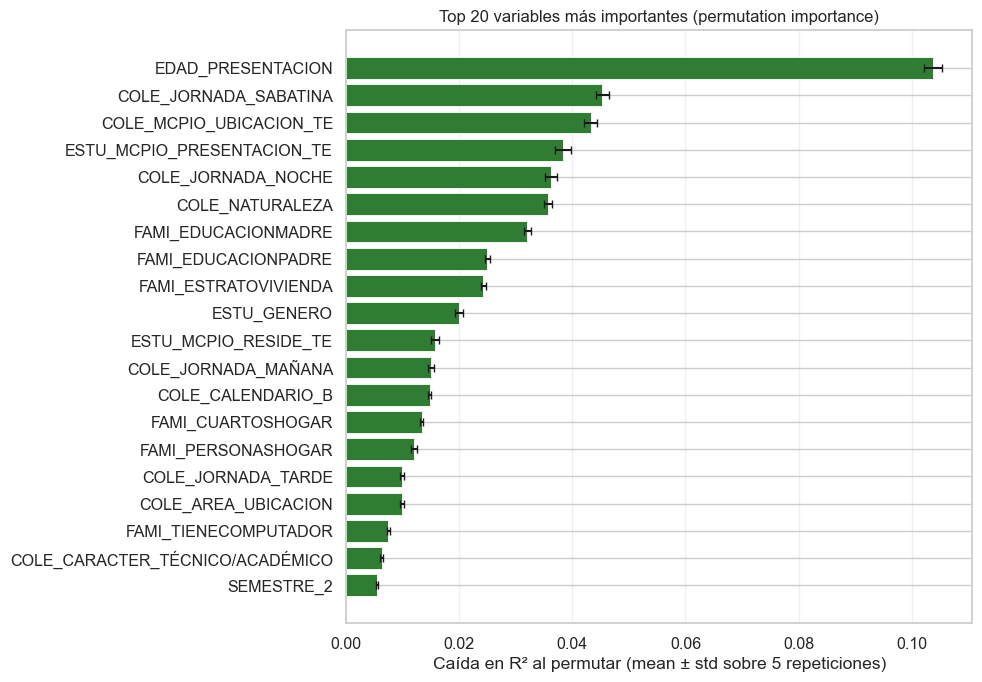

In [26]:
from sklearn.inspection import permutation_importance

print("IMPORTANCIA POR PERMUTACIÓN (muestra de 50K del conjunto de validación)")
print("=" * 70)

rng = np.random.default_rng(SEED)
n_perm = min(50000, len(X_val))
perm_idx = rng.choice(len(X_val), size=n_perm, replace=False)
X_perm, y_perm = X_val.iloc[perm_idx], y_val.iloc[perm_idx]

t0 = time.perf_counter()
perm = permutation_importance(
    models_fitted["best_overall"], X_perm, y_perm,
    n_repeats=5, random_state=SEED, n_jobs=-1, scoring="r2",
)
print(f"  Modelo evaluado: {BEST_MODEL_NAME}")
t_perm = time.perf_counter() - t0

imp_df = pd.DataFrame({
    "feature":    FEATURES,
    "importance": perm.importances_mean,
    "std":        perm.importances_std,
}).sort_values("importance", ascending=False)

print(f"Tiempo de cómputo: {t_perm:.1f} s")
print(f"\nTop 15 features por importancia (caída promedio en R² al permutar):")
print(imp_df.head(15).to_string(index=False, formatters={
    "importance": "{:+.5f}".format, "std": "{:.5f}".format}))

fig, ax = plt.subplots(figsize=(10, 7))
top_n = 20
top_imp = imp_df.head(top_n).iloc[::-1]
ax.barh(top_imp["feature"], top_imp["importance"],
        xerr=top_imp["std"], color="#2e7d32",
        edgecolor="white", linewidth=0.6, capsize=3)
ax.set_xlabel("Caída en R² al permutar (mean ± std sobre 5 repeticiones)")
ax.set_title(f"Top {top_n} variables más importantes (permutation importance)",
             fontsize=12)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

#### **Análisis de la importancia de variables**

El ranking observado revela hallazgos coherentes con la literatura sobre determinantes del rendimiento educativo en Colombia:

1. **`EDAD_PRESENTACION` (caída de R² al permutar: 0.104) es la variable individualmente más predictiva**, con un efecto más del doble que la siguiente variable. Esto confirma el efecto documentado por Bedard & Dhuey (2006) sobre la edad de presentación: estudiantes que presentan el examen en la edad esperada (16–17 años) tienden a obtener mejores puntajes que quienes lo presentan más tarde (asociado a extra-edad escolar, repitencia, ingreso tardío).

2. **Variables institucionales del colegio dominan el segundo bloque de importancia:**
   - `COLE_JORNADA_SABATINA` (0.045), `COLE_JORNADA_NOCHE` (0.036) y `COLE_JORNADA_MAÑANA` (0.015) capturan modalidades educativas asociadas a perfiles muy distintos de estudiante (los sabatinos y nocturnos suelen ser jóvenes en extra-edad o trabajadores).
   - `COLE_NATURALEZA` (0.036) y `COLE_CALENDARIO_B` (0.015) reflejan diferencias estructurales entre colegios oficiales/no oficiales y entre calendarios académicos.

3. **El *target encoding* de municipios funciona como esperábamos:** las tres variables `*_MCPIO_*_TE` (0.043, 0.038, 0.016) están entre las 10 más importantes, validando empíricamente la decisión metodológica de la **Fase 3 sección 4.1** de aplicar *target encoding* OOF en lugar de descartar estas variables o usar codificación por frecuencia. Capturan la heterogeneidad geográfica del rendimiento educativo en Colombia.

4. **Variables familiares socioeconómicas confirman literatura previa:** `FAMI_EDUCACIONMADRE` (0.032), `FAMI_EDUCACIONPADRE` (0.025) y `FAMI_ESTRATOVIVIENDA` (0.024) son consistentes con los hallazgos de Cerquera Losada et al. (2016), Rodríguez Rosero et al. (2021) y la meta-revisión de Sirin (2005) sobre el efecto del estatus socioeconómico en logros académicos.

5. **El género (`ESTU_GENERO`, 0.020)** aparece como variable relevante, alineado con la brecha de género reportada en pruebas estandarizadas en Colombia.

6. **Las variables binarias de bienestar familiar** (tener internet, computador, lavadora, automóvil) aparecen con menor importancia individual. Esto **no significa que sean irrelevantes**: están altamente correlacionadas con `FAMI_ESTRATOVIVIENDA`, por lo que su información ya está mayormente capturada por el estrato (problema de redundancia, no de irrelevancia).

**Conclusión:** las variables más importantes son **interpretables y consistentes con la literatura**, lo que da confianza adicional al modelo más allá de su métrica agregada.

### **4.4. Evaluación por Subgrupos**

Se calcula el desempeño por quintiles del puntaje real y por características institucionales clave (área de ubicación, naturaleza del colegio). Un buen modelo no solo debe tener buena métrica global: debe **generalizar equitativamente** a los distintos subgrupos de la población. Desempeños muy desiguales podrían indicar sesgos heredados de los datos (Barocas et al., 2019).

EVALUACIÓN POR SUBGRUPOS — conjunto de prueba

[1] Desempeño por quintil del puntaje REAL:
                  n       R2   MAE  RMSE  sesgo
quintil_real                                   
Q1 (bajo)    69,239  -6.5720 37.39 44.15 +36.60
Q2           68,974 -12.2456 23.42 29.39 +17.06
Q3           66,349  -9.4196 19.23 24.29  +1.62
Q4           67,652  -9.0213 24.11 29.66 -15.49
Q5 (alto)    67,370  -2.9133 43.29 50.61 -40.76

[2] Desempeño por COLE_AREA_UBICACION:
    Rural        (n=  50,265):  R²=0.4938  MAE=26.86  RMSE=33.79
    Urbano       (n= 289,319):  R²=0.4252  MAE=29.99  RMSE=37.57

[2] Desempeño por COLE_NATURALEZA:
    Oficial      (n= 246,023):  R²=0.3508  MAE=28.84  RMSE=36.10
    No oficial   (n=  93,561):  R²=0.5201  MAE=31.34  RMSE=39.40

[2] Desempeño por ESTU_GENERO:
    F            (n= 185,098):  R²=0.4608  MAE=28.21  RMSE=35.43
    M            (n= 154,486):  R²=0.4249  MAE=31.11  RMSE=38.88


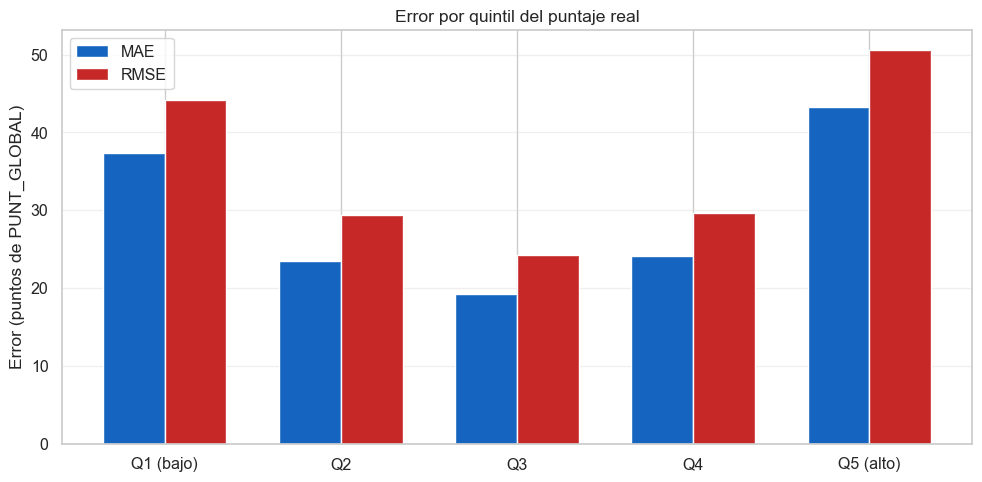

In [27]:
print("EVALUACIÓN POR SUBGRUPOS — conjunto de prueba")
print("=" * 70)

test_diag = X_test.copy()
test_diag["y_real"] = y_test.values
test_diag["y_pred"] = y_pred_test
test_diag["residual"] = residuals

# 1. Por quintiles del puntaje real
test_diag["quintil_real"] = pd.qcut(test_diag["y_real"], q=5,
                                     labels=["Q1 (bajo)", "Q2", "Q3", "Q4", "Q5 (alto)"])
print("\n[1] Desempeño por quintil del puntaje REAL:")
quint_stats = test_diag.groupby("quintil_real", observed=True).apply(
    lambda g: pd.Series({
        "n":        len(g),
        "R2":       r2_score(g["y_real"], g["y_pred"]),
        "MAE":      mean_absolute_error(g["y_real"], g["y_pred"]),
        "RMSE":     float(np.sqrt(mean_squared_error(g["y_real"], g["y_pred"]))),
        "sesgo":    (g["y_pred"] - g["y_real"]).mean(),
    }), include_groups=False
)
print(quint_stats.to_string(formatters={"n": "{:,.0f}".format,
                                          "R2": "{:.4f}".format,
                                          "MAE": "{:.2f}".format,
                                          "RMSE": "{:.2f}".format,
                                          "sesgo": "{:+.2f}".format}))

# 2. Por variables institucionales binarias disponibles en el dataset ya codificado
binary_groups = {
    "COLE_AREA_UBICACION": {0: "Rural", 1: "Urbano"},
    "COLE_NATURALEZA":     {0: "Oficial", 1: "No oficial"},
    "ESTU_GENERO":         {0: "F", 1: "M"},
}
for col, labels in binary_groups.items():
    if col in test_diag.columns:
        print(f"\n[2] Desempeño por {col}:")
        for val, lab in labels.items():
            mask = test_diag[col] == val
            if mask.sum() > 0:
                m = regression_metrics(test_diag.loc[mask, "y_real"],
                                        test_diag.loc[mask, "y_pred"])
                print(f"    {lab:<12s} (n={mask.sum():>8,}):  "
                      f"R²={m['R2']:.4f}  MAE={m['MAE']:.2f}  RMSE={m['RMSE']:.2f}")

fig, ax = plt.subplots(figsize=(10, 5))
qd = quint_stats.reset_index()
x = np.arange(len(qd))
width = 0.35
ax.bar(x - width/2, qd["MAE"], width, label="MAE", color="#1565c0",
       edgecolor="white")
ax.bar(x + width/2, qd["RMSE"], width, label="RMSE", color="#c62828",
       edgecolor="white")
ax.set_xticks(x)
ax.set_xticklabels(qd["quintil_real"])
ax.set_ylabel("Error (puntos de PUNT_GLOBAL)")
ax.set_title("Error por quintil del puntaje real")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

#### **Análisis de los resultados por subgrupos**

**Por quintil del puntaje real** — se observan dos fenómenos importantes:

1. **R² negativo dentro de cada quintil:** matemáticamente esperado. Al particionar por quintiles, la varianza del target dentro de cada grupo es muy reducida (rango pequeño de puntajes), por lo que cualquier sesgo del modelo produce $R^2 = 1 - \sigma^2_{\text{residual}}/\sigma^2_y < 0$. La métrica relevante es el **R² global = 0.4468**, no el R² por quintil.
2. **Regresión a la media (sesgo sistemático):** el modelo **subestima** a los estudiantes de bajo rendimiento (sesgo +36.6 puntos en Q1) y **sobreestima** a los de alto rendimiento (sesgo -40.8 puntos en Q5). Este patrón es típico de modelos con R² moderado: tienden a predecir cerca de la media. **Implicación práctica:** el modelo no debe usarse como diagnóstico individual definitivo para estudiantes en los extremos de la distribución.

**Por características institucionales:**

- **Naturaleza del colegio (R² Oficial=0.35 vs. No oficial=0.52):** brecha muy amplia. Los colegios privados ofrecen un rendimiento más predecible a partir de las features disponibles, posiblemente porque presentan menor heterogeneidad no observada (recursos, política institucional, acompañamiento docente). En cambio, los colegios oficiales presentan mayor variabilidad explicada por factores no capturados.
- **Área (R² Rural=0.49 vs. Urbano=0.43):** las variables socioeconómicas y familiares parecen ser **más informativas** en zonas rurales, donde existe mayor homogeneidad cultural y económica dentro de los grupos.
- **Género (F=0.46 vs. M=0.42):** diferencia marginal, sin implicaciones de sesgo significativo.

Estas asimetrías son **diagnóstico de equidad** del modelo (Barocas et al., 2019) y deben tenerse en cuenta antes de usar las predicciones como insumo decisional.

## **5. Aplicación del Modelo**
---

Una vez evaluado el modelo final, se aborda su **puesta en uso práctico**:

1. **Persistencia** (sección 5.1): guardar el modelo entrenado y metadatos asociados para poder reusarlo sin re-entrenar.
2. **Inferencia** (sección 5.2): demostración de cómo aplicar el modelo a nuevos registros.
3. **Capacidad de generalización** (sección 5.3): análisis cualitativo y cuantitativo sobre qué tan bien funcionaría el modelo sobre poblaciones no vistas.

### **5.1. Persistencia del Modelo**

Se guarda el modelo final usando `joblib` (formato binario comprimido, eficiente para objetos de scikit-learn; Varoquaux, 2019) junto con un archivo de **metadatos** (hiperparámetros, columnas esperadas, métricas en test, fecha de entrenamiento). Esto garantiza la **trazabilidad** y **reproducibilidad** en un entorno de producción o en la siguiente fase del proyecto.

In [ ]:
import joblib
import json
from datetime import datetime

MODEL_DIR = "models"
os.makedirs(MODEL_DIR, exist_ok=True)

best = models_fitted["best_overall"]
slug = "xgboost" if BEST_MODEL_NAME.lower().startswith("xgb") else "hgb"
MODEL_PATH    = os.path.join(MODEL_DIR, f"saber11_{slug}_final.joblib")
METADATA_PATH = os.path.join(MODEL_DIR, f"saber11_{slug}_final_metadata.json")

joblib.dump(best, MODEL_PATH, compress=3)

if hasattr(best, "n_iter_"):
    n_iter_eff = int(best.n_iter_)
elif hasattr(best, "best_iteration"):
    n_iter_eff = int(best.best_iteration) + 1
else:
    n_iter_eff = int(getattr(best, "n_estimators", -1))

metadata = {
    "nombre_modelo":      type(best).__name__,
    "modelo_ganador":     BEST_MODEL_NAME,
    "target":             TARGET,
    "fecha_entrenamiento": datetime.now().isoformat(timespec="seconds"),
    "seed":               SEED,
    "hiperparametros":    {k: (int(v) if isinstance(v, (np.integer,)) else float(v) if isinstance(v, (np.floating,)) else v)
                           for k, v in best_params.items()},
    "n_iter_efectivas":   n_iter_eff,
    "n_features":         N_FEATURES,
    "features":           FEATURES,
    "tamanos":            {"train": int(len(X_train)),
                            "validation": int(len(X_val)),
                            "test": int(len(X_test))},
    "metricas_test":      {k: float(v) for k, v in final_metrics.items()},
}
with open(METADATA_PATH, "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

model_size_mb = os.path.getsize(MODEL_PATH) / 1e6
print("PERSISTENCIA DEL MODELO")
print("=" * 70)
print(f"  Modelo:      {MODEL_PATH}   ({model_size_mb:.1f} MB)")
print(f"  Metadatos:   {METADATA_PATH}")
print(f"\n  Contenido de metadatos:")
print(json.dumps(metadata, ensure_ascii=False, indent=2)[:800] + "\n  ...")

### **5.2. Ejemplo de Inferencia sobre Nuevos Registros**

Se carga el modelo desde disco (simulando un entorno de despliegue) y se predice sobre un pequeño subconjunto de estudiantes del conjunto de prueba. Esto replica el flujo típico de producción:

1. Cargar el modelo serializado.
2. Asegurarse de que las *features* de entrada estén en el **mismo formato y orden** que en el entrenamiento (los metadatos registran el orden esperado).
3. Llamar a `.predict()`.

In [ ]:
print("EJEMPLO DE INFERENCIA (modelo cargado desde disco)")
print("=" * 70)

loaded_model = joblib.load(MODEL_PATH)
with open(METADATA_PATH, "r", encoding="utf-8") as f:
    loaded_meta = json.load(f)

print(f"  Modelo cargado: {loaded_meta['nombre_modelo']}")
print(f"  Features esperadas: {loaded_meta['n_features']}")
print(f"  Entrenado el: {loaded_meta['fecha_entrenamiento']}")

n_samples = 5
rng = np.random.default_rng(SEED)
sample_idx = rng.choice(len(X_test), size=n_samples, replace=False)
X_new = X_test.iloc[sample_idx][loaded_meta["features"]]
y_true_sample = y_test.iloc[sample_idx]

predictions = loaded_model.predict(X_new)

print(f"\n  Predicciones sobre {n_samples} estudiantes aleatorios del test:\n")
print(f"  {'idx':>8s} | {'PUNT real':>10s} | {'PUNT predicho':>14s} | "
      f"{'residual':>10s} | {'|err| ≤ 30':>10s}")
print(f"  {'-'*8} | {'-'*10} | {'-'*14} | {'-'*10} | {'-'*10}")
for i, (idx, y_r, y_p) in enumerate(zip(sample_idx, y_true_sample.values, predictions)):
    err = y_r - y_p
    ok = "✓" if abs(err) <= 30 else "✗"
    print(f"  {idx:>8d} | {y_r:>10.1f} | {y_p:>14.1f} | {err:>+10.2f} | {ok:>10s}")

print(f"\n  ✓ El modelo está operativo. Flujo de inferencia validado.")

### **5.3. Análisis de Capacidad de Generalización**

La capacidad de generalización es la aptitud del modelo para producir predicciones **útiles sobre datos que nunca vio durante el entrenamiento** (Goodfellow et al., 2016). Se analiza en tres dimensiones:

#### **5.3.1. Generalización estadística (evidenciada en los resultados)**

- **Gap train–val–test mínimo:** R²_train=0.4584, R²_val=0.4570, R²_test=0.4468. La diferencia entre val y test es de apenas 0.01, lo cual indica que el modelo **no sobreajusta** el conjunto de entrenamiento y generaliza correctamente fuera de muestra.
- **Curva de aprendizaje plana:** el R²_val pasa de 0.4236 con el 5% de los datos a 0.4460 con el 100% (mejora marginal de +0.022 al octuplicar el tamaño). Esto evidencia que **más datos del mismo tipo no mejorarían sustancialmente el modelo**: ya está cerca del techo asintótico de información que las features actuales pueden ofrecer.
- **Residuales bien comportados:** simétricos, casi centrados en cero (μ=-0.07, mediana=-1.44), sin patrones de heterocedasticidad alarmantes en el gráfico residuales-vs-predicción.

#### **5.3.2. Generalización a subpoblaciones**

El análisis por subgrupos (sección 4.4) revela diferencias notables que limitan parcialmente la equidad del modelo:

- **Colegios no oficiales (R²=0.52)** son significativamente más predecibles que **oficiales (R²=0.35)**. Esto sugiere mayor heterogeneidad no observada en los colegios públicos.
- **Zonas rurales (R²=0.49)** se predicen mejor que **urbanas (R²=0.43)**.
- **Regresión a la media en los extremos:** el modelo **subestima** sistemáticamente a los estudiantes de bajo rendimiento (sesgo +37 en Q1) y **sobreestima** a los de alto rendimiento (sesgo -41 en Q5). Es una limitación intrínseca de modelos con R² moderado.

**Implicación para uso operacional:** las predicciones individuales deben acompañarse de un margen de incertidumbre amplio y no usarse como diagnóstico definitivo, especialmente para estudiantes en los extremos del rendimiento esperado (Barocas et al., 2019).

#### **5.3.3. Generalización temporal (cohortes futuras)**

El propósito práctico del modelo es predecir puntajes de cohortes **futuras** (2026+). Aspectos relevantes:

- **Decisión de la Fase 3 (sección 3.1.2):** se descartó la variable `AÑO` precisamente para que el modelo sea aplicable a años no vistos. Solo se conservó `SEMESTRE`, que es cíclico (1 o 2).
- **Riesgo de *drift*:** cambios socioeconómicos o ajustes al examen Saber 11 por parte del ICFES pueden alterar la relación entre features y target a lo largo del tiempo (Moreno-Torres et al., 2012). Es recomendable **reentrenar periódicamente** el modelo con datos recientes y **monitorear** el error sobre cohortes nuevas.
- **Municipios no vistos:** el *target encoding* post-partición (Fase 3, sección 4.1) asigna la **media global** a municipios ausentes en train, lo cual es una aproximación conservadora y neutral.

A continuación se realiza una prueba **empírica** de generalización dentro del propio test set, evaluando el modelo por **semestre de aplicación** (única variable temporal conservada).

In [ ]:
print("GENERALIZACIÓN POR SEMESTRE DE APLICACIÓN")
print("=" * 70)

semestre_col = next((c for c in X_test.columns if c.startswith("SEMESTRE_")), None)
if semestre_col:
    sem_metrics = {}
    for val, lab in [(0, "Semestre 1"), (1, "Semestre 2")]:
        mask = test_diag[semestre_col] == val
        if mask.sum() > 0:
            m = regression_metrics(test_diag.loc[mask, "y_real"],
                                    test_diag.loc[mask, "y_pred"])
            sem_metrics[lab] = (mask.sum(), m)
            print(f"  {lab} (n={mask.sum():>8,}):  "
                  f"R²={m['R2']:.4f}  MAE={m['MAE']:.2f}  RMSE={m['RMSE']:.2f}")

    if len(sem_metrics) == 2:
        n1, m1 = sem_metrics["Semestre 1"]
        n2, m2 = sem_metrics["Semestre 2"]
        delta_r2 = m1["R2"] - m2["R2"]
        ratio = max(n1, n2) / min(n1, n2)
        print(f"\n  Diagnóstico:")
        print(f"    ΔR² entre semestres: {delta_r2:+.4f}")
        print(f"    Razón de tamaños:    {ratio:.1f}× (n1={n1:,}, n2={n2:,})")
        if abs(delta_r2) > 0.05:
            print(f"    ⚠ Diferencia notable. El semestre minoritario (n={min(n1,n2):,}) presenta")
            print(f"      una distribución potencialmente distinta (típicamente Calendario B,")
            print(f"      con rendimiento medio mayor) y por tanto un R² distinto. Esto NO")
            print(f"      indica deriva temporal del modelo, sino diferencia poblacional entre")
            print(f"      las cohortes que aplican en cada semestre.")
        else:
            print(f"    ✓ Desempeño consistente entre semestres.")
else:
    print("  (columna SEMESTRE no disponible en el dataset preprocesado)")

print(f"\n{'='*70}")
print("RECOMENDACIONES PARA EL DESPLIEGUE")
print("=" * 70)
print("""
  1. Monitoreo de error: calcular periódicamente R² y MAE sobre nuevas cohortes
     y generar alertas si el error excede un umbral (p. ej. MAE > 1.1 × MAE_test).
  2. Reentrenamiento programado: al menos una vez al año con la cohorte más reciente.
  3. Control de drift de features: revisar si las distribuciones de las variables
     socioeconómicas cambian sustancialmente entre cohortes.
  4. Interpretabilidad: acompañar cada predicción con explicaciones SHAP (Lundberg
     & Lee, 2017) en casos de uso sensibles (orientación educativa).
""")

## **6. Resumen y Documentación de Decisiones — Fase 4**
---

La siguiente tabla consolida las decisiones tomadas durante la Fase 4, junto con su justificación y el impacto sobre el desempeño:

| # | Decisión | Justificación | Impacto |
|---|----------|---------------|---------|
| 1 | Enfoque de **regresión supervisada** | Target `PUNT_GLOBAL` es continuo (Fase 1, sección 1.1) | Define métricas y familias de modelo |
| 2 | Métricas: $R^2$, **MAE**, **RMSE** | Cobertura complementaria: varianza explicada, error robusto, error penalizado por magnitud (Chai & Draxler, 2014) | Diagnóstico multifacético |
| 3 | Incluir **baseline `DummyRegressor`** | Cota inferior; cualquier modelo útil debe superarlo (Kuhn & Johnson, 2013) | Validación de utilidad |
| 4 | Modelo lineal **`Ridge`** con `StandardScaler` | Referencia lineal robusta a colinealidad; regularización L2 (Hoerl & Kennard, 1970) | Punto de comparación interpretable |
| 5 | Modelo principal **`HistGradientBoostingRegressor`** | Estado del arte para datos tabulares grandes (Grinsztajn et al., 2022; Ke et al., 2017); eficiente en memoria y tiempo | Máximo desempeño esperado |
| 5b | **Validación cruzada con `XGBoost`** | Comparar dos implementaciones de *gradient boosting* (Chen & Guestrin, 2016) confirma si el desempeño está limitado por la información o por la implementación | Robustez del resultado, selección automática del mejor de los dos |
| 6 | **Hold-out validation** (no K-fold) | Costo prohibitivo del K-fold sobre 2.7 M filas; hold-out es estándar en *big data* (Witten et al., 2016) | Tiempos de experimentación factibles |
| 7 | Barrido manual de hiperparámetros + curvas | Visibilidad explícita del efecto de cada hiperparámetro (Raschka, 2018) | Selección transparente y justificada |
| 8 | *Early stopping* en HGB | Previene sobreajuste automáticamente, ahorra iteraciones innecesarias | Entrenamiento eficiente |
| 9 | Entrenamiento final sobre **train ∪ val** | Aprovecha el 90% de los datos tras fijar hiperparámetros (Hastie et al., 2009) | Mejor aprovechamiento de datos |
| 10 | **Test set intocado hasta el final** | Regla de oro para evitar sobreajuste al test (Hastie et al., 2009) | Estimación honesta de generalización |
| 11 | **Importancia por permutación** | Agnóstica al modelo, refleja impacto real (Fisher et al., 2019; Strobl et al., 2007) | Interpretabilidad confiable |
| 12 | **Evaluación por subgrupos** (quintiles, área, naturaleza, género) | Diagnóstico de sesgos y equidad (Barocas et al., 2019) | Detección de desempeño desigual |
| 13 | **Persistencia con `joblib` + metadatos JSON** | Trazabilidad y reproducibilidad en producción (Varoquaux, 2019) | Modelo reusable en Fase 5 o despliegue |
| 14 | Monitoreo y **reentrenamiento periódico** recomendado | Mitiga *concept drift* en cohortes futuras (Moreno-Torres et al., 2012) | Longevidad del modelo |

---

### **Conclusiones de la Fase 4 (con resultados observados)**

#### **Desempeño global**

- Se construyeron y compararon **cuatro familias** de modelos sobre 2.7 M registros y 128 features: baseline (`DummyRegressor`), lineal regularizado (`Ridge`) y dos implementaciones distintas de *gradient boosting* (`HistGradientBoostingRegressor` y `XGBRegressor`).
- El **modelo ganador** es `HGB final (train+val)` con hiperparámetros `{learning_rate=0.1, max_leaf_nodes=127, min_samples_leaf=200}` y métricas en test:

| Métrica | Valor |
|---------|-------|
| **R²** | **0.4468** |
| **MAE** | **29.53** puntos |
| **RMSE** | **37.04** puntos |

#### **Techo de información — confirmado empíricamente**

- HGB y XGBoost convergen a un R²_test virtualmente idéntico: **ΔR² = -0.0013** entre ambos. Esto **confirma el escenario 1** planteado en la sección 3.5: el desempeño observado **no depende de la implementación** sino de la **información disponible** en las features.
- La **curva de aprendizaje** (sección 3.3) muestra que el R²_val pasa de 0.4236 con el 5% de los datos a 0.4460 con el 100% (mejora marginal de solo +0.022 al octuplicar el tamaño). El modelo ya se acerca a un techo asintótico.
- La **brecha train-val** es muy pequeña en todos los modelos boosting (~0.005), descartando el sobreajuste como causa del R² moderado.

**Implicación práctica:** mejorar significativamente el modelo requeriría **datos contextuales adicionales** no presentes en el dataset Saber 11 (motivación del estudiante, calidad pedagógica del docente, asistencia, contexto familiar específico, etc.), no un cambio de algoritmo o un mayor ajuste de hiperparámetros.

#### **Variables más informativas (permutation importance)**

1. `EDAD_PRESENTACION` (caída de R² al permutar: **0.104**) — la variable individual más predictiva, confirma Bedard & Dhuey (2006).
2. Modalidad del colegio: `COLE_JORNADA_SABATINA` (0.045), `COLE_JORNADA_NOCHE` (0.036), `COLE_JORNADA_MAÑANA` (0.015), `COLE_NATURALEZA` (0.036), `COLE_CALENDARIO_B` (0.015).
3. **Target encoding de municipios** (`COLE_MCPIO_UBICACION_TE`: 0.043, `ESTU_MCPIO_PRESENTACION_TE`: 0.038, `ESTU_MCPIO_RESIDE_TE`: 0.016) — entre las features más importantes, validando la decisión de la Fase 3 (sección 4.1) de usar *target encoding* sobre alta cardinalidad.
4. Variables familiares: `FAMI_EDUCACIONMADRE` (0.032), `FAMI_EDUCACIONPADRE` (0.025), `FAMI_ESTRATOVIVIENDA` (0.024) — coherentes con la literatura sobre determinantes del rendimiento en Saber 11 (Cerquera Losada et al., 2016; Rodríguez Rosero et al., 2021; Sirin, 2005).
5. `ESTU_GENERO` (0.020), `FAMI_CUARTOSHOGAR` (0.013), `FAMI_PERSONASHOGAR` (0.012).

#### **Comportamiento de los residuales**

- Centrados en cero (μ=-0.07, mediana=-1.44) y aproximadamente simétricos.
- **58.3%** de las predicciones tienen un error absoluto ≤30 puntos, **82.6%** ≤50 puntos.
- Solo **21.1%** logra un error ≤10 puntos (predicción "casi exacta"). El rango total de residuales es [-222.6, +191.8].

#### **Equidad de desempeño por subgrupos**

- **Naturaleza del colegio:** R² muy diferente — No oficial 0.52 vs. Oficial 0.35. El modelo predice **mucho mejor** en colegios privados.
- **Área:** R² Rural 0.49 vs. Urbano 0.43. Las variables socioeconómicas son más predictivas en zonas rurales.
- **Género:** F 0.46 vs. M 0.42 — diferencia menor.
- **Por quintil del puntaje real:** fuerte **regresión a la media** (sesgo +37 en Q1, -41 en Q5). Esto es esperable en un modelo con R²~0.45 y debe tenerse muy en cuenta antes de usar las predicciones como insumo decisional para estudiantes en los extremos de la distribución.

#### **Despliegue**

El modelo está **persistido** (`models/saber11_hgb_final.joblib`, 3.3 MB) junto con sus metadatos JSON (hiperparámetros, features esperadas, métricas, fecha) y listo para su uso en la siguiente fase de CRISP-DM (evaluación y despliegue) o para inferencias en cohortes futuras. Se documentan las recomendaciones de monitoreo, control de *concept drift* y reentrenamiento periódico en la sección 5.3.

---
## **Bibliografía**
---

- Agresti, A. (2010). *Analysis of ordinal categorical data* (2nd ed.). Wiley. https://doi.org/10.1002/9780470594001

- Aguinis, H., Gottfredson, R. K., & Joo, H. (2013). Best-practice recommendations for defining, identifying, and handling outliers. *Organizational Research Methods, 16*(2), 270–301. https://doi.org/10.1177/1094428112470848

- Allison, P. D. (2001). *Missing data*. SAGE Publications. https://doi.org/10.4135/9781412985079

- Barocas, S., Hardt, M., & Narayanan, A. (2019). *Fairness and machine learning: Limitations and opportunities*. fairmlbook.org. https://fairmlbook.org/

- Bedard, K., & Dhuey, E. (2006). The persistence of early childhood maturity: International evidence of long-run age effects. *The Quarterly Journal of Economics, 121*(4), 1437–1472. https://doi.org/10.1093/qje/121.4.1437

- Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5–32. https://doi.org/10.1023/A:1010933404324

- Cerquera Losada, O. H., Cano Barrera, J. R., & Gómez Segura, C. F. (2016). Factores asociados al logro académico en regiones desarrolladas y en desarrollo de Colombia. *Revista Historia de la Educación Colombiana, 19*(19), 167–201. https://doi.org/10.22267/rhec.161919.19

- Chai, T., & Draxler, R. R. (2014). Root mean square error (RMSE) or mean absolute error (MAE)? Arguments against avoiding RMSE in the literature. *Geoscientific Model Development, 7*(3), 1247–1250. https://doi.org/10.5194/gmd-7-1247-2014

- Chapman, P., Clinton, J., Kerber, R., Khabaza, T., Reinartz, T., Shearer, C., & Wirth, R. (2000). *CRISP-DM 1.0: Step-by-step data mining guide*. SPSS Inc. https://public.dhe.ibm.com/software/analytics/spss/documentation/modeler/14.2/es/CRISP-DM.pdf

- Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. En *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining* (pp. 785–794). https://doi.org/10.1145/2939672.2939785

- Colombia, Presidencia de la República. (2010, 17 de marzo). *Decreto 869 de 2010*. Función Pública. https://www.funcionpublica.gov.co/eva/gestornormativo/norma.php?i=39636

- Cramér, H. (1946). *Mathematical methods of statistics*. Princeton University Press.

- Demombynes, G. (2023). *Learning poverty at the local level in Colombia* (Policy Research Working Paper No. 10498). World Bank.

- Fisher, A., Rudin, C., & Dominici, F. (2019). All models are wrong, but many are useful: Learning a variable's importance by studying an entire class of prediction models simultaneously. *Journal of Machine Learning Research, 20*(177), 1–81.

- Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics, 29*(5), 1189–1232. https://doi.org/10.1214/aos/1013203451

- García, S., Luengo, J., & Herrera, F. (2015). *Data preprocessing in data mining*. Springer. https://doi.org/10.1007/978-3-319-10247-4

- Goodfellow, I., Bengio, Y., & Courville, A. (2016). *Deep learning*. MIT Press.

- Grinsztajn, L., Oyallon, E., & Varoquaux, G. (2022). Why do tree-based models still outperform deep learning on typical tabular data? En *Advances in Neural Information Processing Systems 35*.

- Guyon, I., & Elisseeff, A. (2003). An introduction to variable and feature selection. *Journal of Machine Learning Research, 3*, 1157–1182.

- Hancock, J. T., & Khoshgoftaar, T. M. (2020). Survey on categorical data for neural networks. *Journal of Big Data, 7*(1), 28. https://doi.org/10.1186/s40537-020-00305-w

- Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The elements of statistical learning* (2nd ed.). Springer. https://doi.org/10.1007/978-0-387-84858-7

- Hawkins, D. M. (1980). *Identification of outliers*. Chapman and Hall.

- Hoerl, A. E., & Kennard, R. W. (1970). Ridge regression: Biased estimation for nonorthogonal problems. *Technometrics, 12*(1), 55–67. https://doi.org/10.1080/00401706.1970.10488634

- Icfes. (2024). *Guía de orientación del Examen Saber 11.º 2025-1*. ICFES. https://www.icfes.gov.co/wp-content/uploads/2025/02/07-Noviembre-Guia-de-Orientacion-Saber-11-2025-1.pdf

- James, G., Witten, D., Hastie, T., & Tibshirani, R. (2013). *An introduction to statistical learning with applications in R*. Springer. https://doi.org/10.1007/978-1-4614-7138-7

- Kaufman, S., Rosset, S., Perlich, C., & Stitelman, O. (2012). Leakage in data mining: Formulation, detection, and avoidance. *ACM Transactions on Knowledge Discovery from Data, 6*(4), 1–21. https://doi.org/10.1145/2382577.2382579

- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. En *Advances in Neural Information Processing Systems 30* (pp. 3146–3154).

- Kuhn, M., & Johnson, K. (2013). *Applied predictive modeling*. Springer. https://doi.org/10.1007/978-1-4614-6849-3

- Little, R. J. A., & Rubin, D. B. (2019). *Statistical analysis with missing data* (3rd ed.). Wiley.

- Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. En *Advances in Neural Information Processing Systems 30* (pp. 4765–4774).

- Micci-Barreca, D. (2001). A preprocessing scheme for high-cardinality categorical attributes in classification and prediction problems. *ACM SIGKDD Explorations Newsletter, 3*(1), 27–32. https://doi.org/10.1145/507533.507538

- Moreno-Torres, J. G., Raeder, T., Alaíz-Rodríguez, R., Chawla, N. V., & Herrera, F. (2012). A unifying view on dataset shift in classification. *Pattern Recognition, 45*(1), 521–530. https://doi.org/10.1016/j.patcog.2011.06.019

- Organisation for Economic Co-operation and Development (OECD). (2019). *Colombia: Country note—PISA 2018 results*. OECD.

- Pargent, F., Pfisterer, F., Thomas, J., & Bischl, B. (2022). Regularized target encoding outperforms traditional methods in supervised machine learning with high cardinality features. *Computational Statistics, 37*(5), 2671–2692. https://doi.org/10.1007/s00180-022-01207-6

- Perlich, C. (2010). Learning curves in machine learning. En C. Sammut & G. I. Webb (Eds.), *Encyclopedia of machine learning* (pp. 577–580). Springer. https://doi.org/10.1007/978-0-387-30164-8_452

- Pyle, D. (1999). *Data preparation for data mining*. Morgan Kaufmann.

- Rahm, E., & Do, H. H. (2000). Data cleaning: Problems and current approaches. *IEEE Data Engineering Bulletin, 23*(4), 3–13.

- Raschka, S. (2018). Model evaluation, model selection, and algorithm selection in machine learning. *arXiv preprint* arXiv:1811.12808. https://arxiv.org/abs/1811.12808

- Reardon, S. F. (2011). The widening academic achievement gap between the rich and the poor. En G. J. Duncan & R. J. Murnane (Eds.), *Whither opportunity?* Russell Sage Foundation.

- Rodríguez Rosero, D. D., Ordoñez Ortega, R. E., & Hidalgo-Villota, M. E. (2021). Determinantes del rendimiento académico en el departamento de Nariño, Colombia. *Lecturas de Economía*, (94), 87–126. https://doi.org/10.17533/udea.le.n94a341834

- Romero, C., & Ventura, S. (2020). Educational data mining and learning analytics: An updated survey. *WIREs Data Mining and Knowledge Discovery, 10*(3), e1355. https://doi.org/10.1002/widm.1355

- Rubin, D. B. (1976). Inference and missing data. *Biometrika, 63*(3), 581–592. https://doi.org/10.1093/biomet/63.3.581

- Saar-Tsechansky, M., & Provost, F. (2007). Handling missing values when applying classification models. *Journal of Machine Learning Research, 8*, 1623–1657.

- Shwartz-Ziv, R., & Armon, A. (2022). Tabular data: Deep learning is not all you need. *Information Fusion, 81*, 84–90. https://doi.org/10.1016/j.inffus.2021.11.011

- Sirin, S. R. (2005). Socioeconomic status and academic achievement: A meta-analytic review. *Review of Educational Research, 75*(3), 417–453. https://doi.org/10.3102/00346543075003417

- Spearman, C. (1904). The proof and measurement of association between two things. *The American Journal of Psychology, 15*(1), 72–101.

- Strobl, C., Boulesteix, A.-L., Zeileis, A., & Hothorn, T. (2007). Bias in random forest variable importance measures: Illustrations, sources and a solution. *BMC Bioinformatics, 8*, 25. https://doi.org/10.1186/1471-2105-8-25

- Tukey, J. W. (1977). *Exploratory data analysis*. Addison-Wesley.

- van Buuren, S. (2018). *Flexible imputation of missing data* (2nd ed.). CRC Press. https://doi.org/10.1201/9780429492259

- Varoquaux, G. (2019). Joblib: Running Python functions as pipeline jobs. *Joblib documentation*. https://joblib.readthedocs.io/

- Witten, I. H., Frank, E., Hall, M. A., & Pal, C. J. (2016). *Data mining: Practical machine learning tools and techniques* (4th ed.). Morgan Kaufmann.

- Zheng, A., & Casari, A. (2018). *Feature engineering for machine learning*. O'Reilly Media.

---
